In [1]:
USE_CUDA = True

# Dependencies

## Code

In [46]:
import time
import queue
import threading
import warnings
import multiprocessing
from functools import partial
from typing import Any, Callable, Iterator, Literal, cast

## Status

In [47]:
def print_status(message: str) -> None:
    print(f"\r{message:<80}", end="", flush=True)


def end_status(message: str = "") -> None:
    print(f"\r{message:<80}", flush=True)

In [48]:
def format_duration(seconds: float) -> str:
    minutes, remaining_seconds = divmod(int(seconds), 60)
    hours, remaining_minutes = divmod(minutes, 60)
    return f"{hours:02d}:{remaining_minutes:02d}:{remaining_seconds:02d}"

In [49]:
def print_progress(
    current: int,
    total: int,
    prefix: str = "",
    width: int = 30,
    started: float | None = None,
    suffix: str = "",
) -> None:
    fraction = current / total if total else 0
    filled = int(width * fraction)
    bar = "█" * filled + "-" * (width - filled)
    message = f"{prefix} |{bar}| {current}/{total} ({fraction:.0%})"
    if started is not None:
        elapsed = time.time() - started
        message += f" | {format_duration(elapsed)} elapsed"
        if 0 < current < total:
            message += f", ~{format_duration(elapsed / current * (total - current))} left"
    if suffix:
        message += f" | {suffix}"
    print_status(message)

In [50]:
class GridSearchProgress:
    def __init__(self, total: int, prefix: str, refresh_seconds: float = 10) -> None:
        self.total = total
        self.prefix = prefix
        self.refresh_seconds = refresh_seconds
        self.fitted = 0
        self.scored = 0
        self.failed = 0
        self.started = time.time()
        # with n_jobs != 1 the fits run in worker processes, which can only reach this process through a manager queue
        self.manager = multiprocessing.get_context("spawn").Manager()
        self.events = self.manager.Queue()
        self.listener = threading.Thread(target=self.listen, daemon=True)
        self.listener.start()

    def show(self) -> None:
        suffix = f"{self.fitted} fitted, {self.failed} failed"
        print_progress(self.scored + self.failed, self.total, self.prefix, started=self.started, suffix=suffix)

    def listen(self) -> None:
        while True:
            self.show()
            try:
                event = self.events.get(timeout=self.refresh_seconds)
            except queue.Empty:
                continue
            if event is None:
                return
            if event == "fitted":
                self.fitted += 1
            elif event == "scored":
                self.scored += 1
            else:
                self.failed += 1

    def close(self) -> None:
        self.events.put(None)
        self.listener.join()
        self.manager.shutdown()

## OS, Systems, and File's Manager

In [51]:
import os
import sys
import gc
import shutil
import hashlib
import joblib
import json

### Configurations

In [52]:
ROW_INDEX_COLUMN = "row_index"

### Loading Data

In [53]:
def get_file_paths_in_folder(folder_path: str, file_extension: str) -> list[str]:
    file_paths = []
    for file_name in os.listdir(folder_path):
        if file_name.endswith(f".{file_extension}"):
            file_paths.append(os.path.join(folder_path, file_name))
    return sorted(file_paths)

### Dump and Load

In [54]:
def load(object_path: str) -> Any:
    return joblib.load(object_path)

In [55]:
def dump(obj: Any, dump_path: str) -> None:
    joblib.dump(obj, dump_path)

### File's Path

In [56]:
# cached path
PATH_FOLDER_CACHE = "cache"
PATH_FOLDER_TRAINED_MODEL = "trained-models"
PATH_FOLDER_GRID_SEARCH = "grid-search"
PATH_FOLDER_EVALUATION = "evaluation"
PATH_FOLDER_NOISE_EVALUATION = "noise-evaluation"
PATH_FOLDER_PREDICTIONS = "predictions"

In [57]:
# class label's
PATH_JSON_ORIGINAL_CLASSES_LIST = os.path.join(PATH_FOLDER_CACHE, "original-classes.json")
PATH_JSON_MINIMIZED_CLASSES_LIST = os.path.join(PATH_FOLDER_CACHE, "minimized-classes.json")
PATH_JSON_CURRENTLY_USED_CLASSES_LIST = PATH_JSON_ORIGINAL_CLASSES_LIST

In [58]:
# transformers
PATH_LABEL_ENCODER_TRANSFORMER = os.path.join(PATH_FOLDER_CACHE, "label-encoder-transformer.pkl")
PATH_PCA_TRANSFORMER = os.path.join(PATH_FOLDER_CACHE, "pca-transformer.pkl")

In [59]:
# data pipeline path
PATH_FOLDER_ORIGINAL_DATASET = "cse-cic-ids2018"
PATH_FOLDER_DATA_PIPELINE = "data-pipeline"
PATH_FOLDER_TRAINED_MODEL_WOUT_SMOTE = os.path.join(PATH_FOLDER_TRAINED_MODEL, "wout-smote")
PATH_FOLDER_TRAINED_MODEL_WITH_SMOTE = os.path.join(PATH_FOLDER_TRAINED_MODEL, "with-smote")
PATH_FOLDER_GRID_SEARCH_WOUT_SMOTE = os.path.join(PATH_FOLDER_GRID_SEARCH, "wout-smote")
PATH_FOLDER_GRID_SEARCH_WITH_SMOTE = os.path.join(PATH_FOLDER_GRID_SEARCH, "with-smote")
PATH_FOLDER_PARQUET_DATASET = os.path.join(PATH_FOLDER_DATA_PIPELINE, "01-raw-parquet")
PATH_FOLDER_CLEANED_DATASET = os.path.join(PATH_FOLDER_DATA_PIPELINE, "02-cleaned-parquet")
PATH_FOLDER_DEDUPLICATED_DATASET = os.path.join(PATH_FOLDER_DATA_PIPELINE, "03-deduplicated-parquet")
PATH_FOLDER_SPLITTED_DATASET = os.path.join(PATH_FOLDER_DATA_PIPELINE, "04-splitted-parquet")
PATH_FOLDER_SPLITTED_DATASET_TRAIN = os.path.join(PATH_FOLDER_SPLITTED_DATASET, "train")
PATH_FOLDER_SPLITTED_DATASET_TEST = os.path.join(PATH_FOLDER_SPLITTED_DATASET, "test")
PATH_FOLDER_NOISY_DATASET = os.path.join(PATH_FOLDER_DATA_PIPELINE, "06-noisy-parquet")
PATH_FOLDER_NOISY_DATASET_TEST = os.path.join(PATH_FOLDER_NOISY_DATASET, "test")

### File's Name

In [60]:
FEATURES_FILE_NAME = "features.parquet"
LABELS_FILE_NAME = "labels.parquet"
ENCODED_LABELS_FILE_NAME = "encoded-labels.parquet"

# noisy datasets
NOISE_CHECK_FILE_NAME = "noise-check.csv"

# predictions
PREDICTIONS_FILE_NAME = "predictions.parquet"

# evaluation results
OUTCOME_COUNTS_FILE_NAME = "outcome-counts.parquet"
DISPLACEMENT_BINS_FILE_NAME = "displacement-bins.csv"
METRICS_FILE_NAME = "metrics.csv"
DEGRADATION_FILE_NAME = "degradation.csv"
ROBUSTNESS_RANKING_FILE_NAME = "robustness-ranking.csv"
MIXTURE_CHECK_FILE_NAME = "mixture-check.csv"
CLASS_METRICS_FILE_NAME = "class-metrics.csv"
ERROR_COMPOSITION_FILE_NAME = "error-composition.csv"
PREDICTION_SUMMARIES_FILE_NAME = "prediction-summaries.csv"
KEY_FINDINGS_FILE_NAME = "key-findings.csv"
MODEL_COMPARISON_PLOT_FILE_NAME = "model-comparison.png"
ERROR_COMPOSITION_PLOT_FILE_NAME = "error-composition.png"
FLIP_RATE_PLOT_FILE_NAME = "flip-rate-against-displacement.png"
CONFUSION_MATRIX_PLOT_FILE_NAME = "confusion-matrix.png"
PREDICTION_TRANSITIONS_PLOT_FILE_NAME = "prediction-transitions.png"

## Data Processing

In [61]:
import re
import numpy as np
import pandas as pd
import polars as pl
import pyarrow as pa
import pyarrow.parquet as pq

In [62]:
if USE_CUDA:
    cuda_root = os.path.join(sys.prefix, "targets", "x86_64-linux")
    if os.path.isdir(os.path.join(cuda_root, "include")):
        os.environ.setdefault("CUDA_PATH", cuda_root)
    os.environ.setdefault("CUDA_CACHE_MAXSIZE", str(4 * 1024**3))

### Configurations

In [63]:
NUMERIC_DATA_TYPE = "float32"
LABEL_COLUMN = "label"
CLASS_COLUMN = "class"
ROW_COUNT_COLUMN = "rows"
BATCH_SIZE = 500_000
RANDOM_STATE = 42

### Batch Processing

In [64]:
def count_rows(dataset: pl.LazyFrame) -> int:
    return dataset.select(pl.len()).collect().item()

In [65]:
def read_in_batches(
    dataset: pl.LazyFrame,
    prefix: str = "Reading batches",
    batch_size: int = BATCH_SIZE,
) -> Iterator[tuple[int, pl.DataFrame]]:
    row_offsets = range(0, count_rows(dataset), batch_size)
    started = time.time()
    print_progress(0, len(row_offsets), prefix, started=started)
    for batch_index, row_offset in enumerate(row_offsets, start=1):
        yield row_offset, dataset.slice(row_offset, batch_size).collect()
        print_progress(batch_index, len(row_offsets), prefix, started=started)

In [66]:
def load_features(
    features: pl.LazyFrame,
    prefix: str = "Loading features",
    batch_size: int = BATCH_SIZE,
    numeric_data_type: str = NUMERIC_DATA_TYPE,
) -> pd.DataFrame:
    columns = features.collect_schema().names()
    values = np.empty((count_rows(features), len(columns)), dtype=numeric_data_type)
    for row_offset, batch in read_in_batches(features, prefix, batch_size):
        values[row_offset:row_offset + len(batch)] = batch.to_numpy()
    return pd.DataFrame(values, columns=columns)

### Load All Files

In [67]:
def load_all_files(folder_path: str, row_index_column: str = ROW_INDEX_COLUMN) -> pl.LazyFrame:
    file_paths = get_file_paths_in_folder(folder_path, "parquet")
    return pl.scan_parquet(file_paths).with_row_index(row_index_column)

### Classes List

In [68]:
def get_classes_list_from_a_folder(
    folder_path: str,
    file_extension: Literal["csv", "parquet"],
    label_column: str = LABEL_COLUMN,
) -> list[str]:
    if file_extension not in ("csv", "parquet"):
        raise ValueError("file_extension must be 'csv' or 'parquet'")

    classes = set()
    file_paths = get_file_paths_in_folder(folder_path, file_extension)
    started = time.time()
    for file_index, file_path in enumerate(file_paths, start=1):
        if file_extension == "csv":
            dataframe = pd.read_csv(
                file_path,
                usecols=lambda column: normalize_column_name(column) == label_column,
            )
            labels = dataframe.iloc[:, 0]
            labels = labels[labels != labels.name]
        else:
            labels = pd.read_parquet(file_path, columns=[label_column])[label_column]
        classes.update(labels.dropna().unique())
        print_progress(file_index, len(file_paths), "Reading classes", started=started)

    end_status(f"Found {len(classes)} classes in {len(file_paths)} files")
    return sorted(classes)

In [69]:
def create_classes_list_from_a_folder(
    folder_path: str,
    output_path: str = PATH_JSON_CURRENTLY_USED_CLASSES_LIST,
    label_column: str = LABEL_COLUMN,
) -> list[str]:
    if get_file_paths_in_folder(folder_path, "parquet"):
        file_extension = "parquet"
    elif get_file_paths_in_folder(folder_path, "csv"):
        file_extension = "csv"
    else:
        raise FileNotFoundError(f"No csv or parquet files found in {folder_path}")

    classes = get_classes_list_from_a_folder(folder_path, file_extension, label_column)

    os.makedirs(os.path.dirname(output_path) or ".", exist_ok=True)
    with open(output_path, "w", encoding="utf-8") as file:
        json.dump(classes, file, indent=4)

    return classes

In [70]:
def load_classes_list(file_path: str = PATH_JSON_CURRENTLY_USED_CLASSES_LIST) -> list[str]:
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

In [71]:
def count_classes_in_split(
    split_folder_path: str,
    labels_file_name: str = LABELS_FILE_NAME,
    label_column: str = LABEL_COLUMN,
) -> pd.Series:
    labels_file_path = os.path.join(split_folder_path, labels_file_name)
    class_counts = pl.scan_parquet(labels_file_path).group_by(label_column).len().collect()
    return class_counts.to_pandas().set_index(label_column)["len"]

### Cast to `float32`

In [72]:
def _to_float32(x:pd.DataFrame):
    return x.astype(np.float32)

### Feature Columns

In [73]:
def get_feature_columns(
    folder_path: str = PATH_FOLDER_PARQUET_DATASET,
    label_column: str = LABEL_COLUMN,
) -> list[str]:
    first_file_path = get_file_paths_in_folder(folder_path, "parquet")[0]
    feature_columns = []
    for column in pq.read_schema(first_file_path).names:
        if column != label_column:
            feature_columns.append(column)
    return feature_columns

## Parallel Processing

In [74]:
def create_tasks_list(function: Callable, per_task_arguments: list, *shared_arguments: Any) -> list:
    tasks = []
    for per_task_argument in per_task_arguments:
        task = joblib.delayed(function)(per_task_argument, *shared_arguments)
        tasks.append(task)
    return tasks

In [75]:
def run_tasks_in_parallel(tasks: list, n_jobs: int = -1, prefix: str = "Running tasks"):
    started = time.time()
    print_progress(0, len(tasks), prefix, started=started)
    results = []
    with joblib.parallel_config(backend="loky", inner_max_num_threads=1):
        for result in joblib.Parallel(n_jobs=n_jobs, return_as="generator")(tasks):
            results.append(result)
            print_progress(len(results), len(tasks), prefix, started=started)
    return results

## Segregate Data

In [76]:
def extract_column(
    dataframe: pd.DataFrame,
    source_column: str,
    target_column: str,
    regex: str,
) -> pd.DataFrame:
    dataframe = dataframe.copy()
    dataframe[target_column] = dataframe[source_column].str.extract(regex)[0]
    return dataframe

In [77]:
def group_and_sum(
    dataframe: pd.DataFrame,
    source_column: str,
    group_column: str,
    regex: str,
    value_columns: str | list[str] | None = None,
) -> pd.DataFrame:
    dataframe = extract_column(dataframe, source_column, group_column, regex)

    if value_columns is None:
        value_columns = dataframe.select_dtypes("number").columns.tolist()
    elif isinstance(value_columns, str):
        value_columns = [value_columns]

    return dataframe.groupby(group_column, as_index=False)[value_columns].sum()

## Plotting

In [78]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

### Colors

In [79]:
BAR_COLOR = "#2a78d6"
GRID_COLOR = "#e1e0d9"
TEXT_COLOR = "#0b0b0b"
TEXT_ON_DARK_COLOR = "#ffffff"
EMPTY_CELL_COLOR = "#fcfcfb"
# categorical colors, given to the series in this fixed order
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SERIES_MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]

SEQUENTIAL_COLORMAP = mcolors.LinearSegmentedColormap.from_list(
    "sequential_blue",
    ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"],
).with_extremes(bad=EMPTY_CELL_COLOR)

DIVERGING_COLORMAP = mcolors.LinearSegmentedColormap.from_list(
    "diverging_blue_red",
    ["#2a78d6", "#f0efec", "#e34948"],
).with_extremes(bad=EMPTY_CELL_COLOR)

FIGURE_DPI = 300  # resolution of the saved figures

### Plot Function

In [80]:
def plot_bar(
    dataframe: pd.DataFrame,
    x: str,
    y: str,
    title: str | None = None,
    xlabel: str | None = None,
    ylabel: str | None = None,
    figsize: tuple[int, int] = (10, 5),
    rotation: int = 45,
    log_scale: bool = False,
) -> None:
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(dataframe[x].astype(str), dataframe[y], color=BAR_COLOR, zorder=3)
    ax.set_title(title or f"{y} per {x}")
    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(ylabel or y)
    if log_scale:
        ax.set_yscale("log")
    else:
        ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8, zorder=0)
    plt.xticks(rotation=rotation, ha="right")
    plt.tight_layout()
    plt.show()

In [81]:
def plot_heatmap(
    matrix: pd.DataFrame,
    title: str,
    colormap: mcolors.Colormap = SEQUENTIAL_COLORMAP,
    value_range: tuple[float | None, float | None] = (None, None),
    log_scale: bool = False,
    annotate: bool = False,
    annotation_format: str = ",.0f",
    xlabel: str = "",
    ylabel: str = "",
    colorbar_label: str = "",
    figsize: tuple[int, int] = (12, 10),
    font_size: int = 8,
    save_path: str | None = None,
    show: bool = True,
) -> None:
    values = matrix.to_numpy(dtype=float)
    if log_scale:
        values = np.ma.masked_less_equal(values, 0)
        normalization = mcolors.LogNorm(*value_range)
    else:
        normalization = mcolors.Normalize(*value_range)

    fig, ax = plt.subplots(figsize=figsize)
    image = ax.imshow(values, cmap=colormap, norm=normalization, aspect="auto")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(matrix.shape[1]))
    ax.set_xticklabels(matrix.columns, rotation=90, fontsize=font_size)
    ax.set_yticks(range(matrix.shape[0]))
    ax.set_yticklabels(matrix.index, fontsize=font_size)
    colorbar = fig.colorbar(image, ax=ax)
    colorbar.set_label(colorbar_label)

    if annotate:
        for row_index in range(matrix.shape[0]):
            for column_index in range(matrix.shape[1]):
                value = values[row_index, column_index]
                if value is np.ma.masked or np.isnan(value):
                    continue
                if normalization(value) > 0.6:
                    text_color = TEXT_ON_DARK_COLOR
                else:
                    text_color = TEXT_COLOR
                ax.text(
                    column_index,
                    row_index,
                    f"{value:{annotation_format}}",
                    ha="center",
                    va="center",
                    color=text_color,
                    fontsize=font_size,
                )

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=FIGURE_DPI, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)

## Encode Classes' Label

In [82]:
from sklearn.preprocessing import LabelEncoder, FunctionTransformer

## Pipelines

In [83]:
from imblearn.pipeline import Pipeline
from sklearn.base import clone

### Splitting Datasets

In [84]:
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, GridSearchCV, ParameterGrid

### Features Scaling

In [85]:
from sklearn.preprocessing import StandardScaler

### Principal Component Analysis

In [86]:
from sklearn.decomposition import PCA

### Synthetic Minority Oversampling Technique (SMOTE)

In [87]:
from imblearn.over_sampling import SMOTE

### Models

In [88]:
from cuml import KNeighborsClassifier, SVC, LinearSVC, RandomForestClassifier, LogisticRegression
from xgboost import XGBClassifier

### Metrics

In [89]:
from sklearn.metrics import make_scorer, get_scorer, f1_score, precision_score, recall_score
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_recall_fscore_support
from sklearn.metrics import matthews_corrcoef, cohen_kappa_score, confusion_matrix

# CSV To Parquet

## Configurations

In [8]:
CHUNK_SIZE = 100_000

COLUMNS_TO_DROP = {
    "flow id",
    "src ip",
    "source ip",
    "src port",
    "source port",
    "dst ip",
    "destination ip",
    "timestamp",
}

## Normalize Columns

In [9]:
def normalize_column_name(column_name: Any) -> str:
    column_name = str(column_name).strip().lower()
    column_name = re.sub(r"[^0-9a-z]+", "_", column_name)
    return column_name.strip("_")

NameError: name 'Any' is not defined

In [ ]:
def normalize_column_names(column_names: list) -> list[str]:
    normalized_column_names = []
    for column_name in column_names:
        normalized_column_names.append(normalize_column_name(column_name))
    return normalized_column_names

## Create Schema

In [ ]:
def create_schema_columns(folder_path: str, columns_to_drop: set[str] = COLUMNS_TO_DROP) -> list[str]:
    columns = set()
    for file_path in get_file_paths_in_folder(folder_path, "csv"):
        raw_columns = pd.read_csv(file_path, nrows=0).columns.tolist()
        columns.update(normalize_column_names(raw_columns))
    columns -= set(normalize_column_names(list(columns_to_drop)))
    return sorted(columns)

In [ ]:
def create_schema(folder_path: str) -> pd.DataFrame:
    columns = create_schema_columns(folder_path)

    dtypes = []
    for column in columns:
        if column == LABEL_COLUMN:
            dtypes.append("str")
        else:
            dtypes.append(NUMERIC_DATA_TYPE)

    return pd.DataFrame({"column": columns, "dtype": dtypes})

## Cast Numeric Column to `float32`

In [ ]:
def cast_numeric_columns(
    dataframe: pd.DataFrame,
    numeric_data_type: Any = NUMERIC_DATA_TYPE,
) -> pd.DataFrame:
    dataframe = dataframe.copy()

    for column in dataframe.columns:
        if pd.api.types.is_numeric_dtype(dataframe[column]):
            dataframe[column] = dataframe[column].astype(numeric_data_type)

    return dataframe

## Apply Schema Template

In [ ]:
def apply_schema_to_dataframe(
    dataframe: pd.DataFrame,
    schema: pd.DataFrame,
    numeric_data_type: str = NUMERIC_DATA_TYPE,
) -> pd.DataFrame:
    dataframe = dataframe.rename(columns=normalize_column_name)
    dataframe = dataframe.reindex(columns=schema["column"].tolist())

    for column, dtype in zip(schema["column"], schema["dtype"]):
        if not isinstance(dtype, str) or dtype == "":
            continue

        if dtype.startswith(("int", "float")):
            numeric_values = pd.to_numeric(dataframe[column], errors="coerce")
            dataframe[column] = numeric_values.astype(numeric_data_type)
        else:
            try:
                dataframe[column] = dataframe[column].astype(dtype)
            except (ValueError, TypeError) as error:
                warnings.warn(f"Could not cast column '{column}' to {dtype}: {error}")

    return dataframe

## Remove Duplicate Header

In [ ]:
def remove_duplicate_header(dataframe: pd.DataFrame) -> pd.DataFrame:
    is_header_row = dataframe.eq(dataframe.columns.tolist(), axis=1).all(axis=1)
    return dataframe[~is_header_row].reset_index(drop=True)

## Clean A Single Chunk

In [ ]:
def clean_chunk(dataframe: pd.DataFrame, schema: pd.DataFrame) -> pd.DataFrame:
    dataframe = remove_duplicate_header(dataframe)
    dataframe = apply_schema_to_dataframe(dataframe, schema)
    return dataframe

## Write Chunk to Parquet

In [ ]:
def write_chunk_to_parquet(
    chunk: pd.DataFrame,
    chunk_index: int,
    csv_file_path: str,
    output_folder_path: str,
) -> str:
    os.makedirs(output_folder_path, exist_ok=True)
    base_name = os.path.splitext(os.path.basename(csv_file_path))[0]
    output_path = os.path.join(output_folder_path, f"{base_name}_part{chunk_index:04d}.parquet")
    chunk.to_parquet(output_path, index=False)
    return output_path

## Convert A Single CSV

In [ ]:
def convert_csv_to_parquet(
    csv_file_path: str,
    schema: pd.DataFrame,
    output_folder_path: str = PATH_FOLDER_PARQUET_DATASET,
    chunk_size: int = CHUNK_SIZE,
) -> list[str]:
    file_name = os.path.basename(csv_file_path)
    parquet_file_paths = []

    with pd.read_csv(csv_file_path, chunksize=chunk_size, low_memory=False) as chunks:
        for chunk_index, chunk in enumerate(chunks):
            chunk_index_interface = chunk_index + 1
            print_status(f"{file_name}: writing chunk {chunk_index_interface}")
            chunk = clean_chunk(chunk, schema)
            parquet_file_path = write_chunk_to_parquet(chunk, chunk_index_interface, csv_file_path, output_folder_path)
            parquet_file_paths.append(parquet_file_path)

    end_status(f"{file_name}: {len(parquet_file_paths)} chunks written")
    return parquet_file_paths

## Convert All CSV Files to Parquet

In [ ]:
def convert_all_csv_to_parquet(
    csv_folder_path: str = PATH_FOLDER_ORIGINAL_DATASET,
    n_jobs: int = -1,
) -> None:
    csv_file_paths = get_file_paths_in_folder(csv_folder_path, "csv")
    schema = create_schema(csv_folder_path)

    tasks = create_tasks_list(convert_csv_to_parquet, csv_file_paths, schema)
    results = run_tasks_in_parallel(tasks, n_jobs, "Converting CSV files to parquet")

    parquet_file_paths = []
    for result in results:
        parquet_file_paths.extend(result)

    end_status(f"Finished converting {len(csv_file_paths)} CSV files into {len(parquet_file_paths)} parquet files")

## Do the Converting

In [ ]:
convert_all_csv_to_parquet()

2018-03-01-Thursday_TrafficForML_CICFlowMeter.csv: 4 chunks written             00:00 elapsed
2018-02-21-Wednesday_TrafficForML_CICFlowMeter.csv: 11 chunks written           
2018-02-14-Wednesday_TrafficForML_CICFlowMeter.csv: 11 chunks written           
2018-03-02-Friday_TrafficForML_CICFlowMeter.csv: 11 chunks written              :00:15 elapsed, ~00:02:23 left
2018-02-15-Thursday_TrafficForML_CICFlowMeter.csv: 11 chunks written            
2018-02-22-Thursday_TrafficForML_CICFlowMeter.csv: 11 chunks written            :00:16 elapsed, ~00:01:07 left
2018-02-23-Friday_TrafficForML_CICFlowMeter.csv: 11 chunks written              
2018-02-16-Friday_TrafficForML_CICFlowMeter.csv: 11 chunks written              
2018-02-28-Wednesday_TrafficForML_CICFlowMeter.csv: 7 chunks written            :00:18 elapsed, ~00:00:42 left
2018-02-20-Tuesday_TrafficForML_CICFlowMeter.csv: 80 chunks written             
Finished converting 10 CSV files into 168 parquet files                         00:01:2

# Exploratory Data Analysis (EDA)

In [59]:
FILE_COLUMN = "file"
DAY_COLUMN = "day"
FEATURE_COLUMN = "feature"
PERCENTAGE_COLUMN = "percentage"
MISSING_COUNT_COLUMN = "missing"
NAN_COUNT_COLUMN = "nan"
INFINITE_COUNT_COLUMN = "infinite"
UNIQUE_COUNT_COLUMN = "unique"
CORRELATION_COLUMN = "correlation"

DAY_REGEX = r"^(\d{4}-\d{2}-\d{2})"
CORRELATION_THRESHOLD = 0.95
EDA_N_JOBS = 8

## Count Rows Per Day

In [60]:
def count_rows_in_a_single_file(file_path: str) -> int:
    return pq.ParquetFile(file_path).metadata.num_rows

In [61]:
def count_rows_in_all_files(
    folder_path: str = PATH_FOLDER_PARQUET_DATASET,
    file_column: str = FILE_COLUMN,
    row_count_column: str = ROW_COUNT_COLUMN,
) -> pd.DataFrame:
    records = []
    for file_path in get_file_paths_in_folder(folder_path, "parquet"):
        record = {
            file_column: os.path.basename(file_path),
            row_count_column: count_rows_in_a_single_file(file_path),
        }
        records.append(record)
    return pd.DataFrame(records)

In [62]:
results = group_and_sum(count_rows_in_all_files(), FILE_COLUMN, DAY_COLUMN, DAY_REGEX, ROW_COUNT_COLUMN)
display(results)

,day,rows
0,2018-02-14,1048575
1,2018-02-15,1048575
2,2018-02-16,1048574
3,2018-02-20,7948748
4,2018-02-21,1048575
5,2018-02-22,1048575
6,2018-02-23,1048575
7,2018-02-28,613071
8,2018-03-01,331100
9,2018-03-02,1048575


### Plot Row Count Each Day

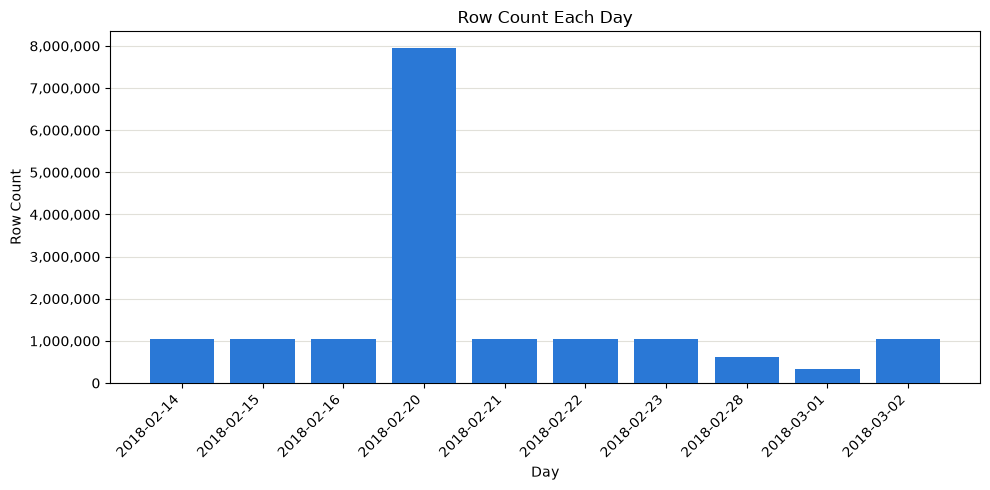

In [63]:
plot_bar(results, DAY_COLUMN, ROW_COUNT_COLUMN, "Row Count Each Day", "Day", "Row Count")
del results

## Count Class Distribution

In [64]:
results = create_classes_list_from_a_folder(PATH_FOLDER_PARQUET_DATASET)
display(results)
del results

Found 15 classes in 168 files                                                   ed ~00:00:00 left


['Benign',
 'Bot',
 'Brute Force -Web',
 'Brute Force -XSS',
 'DDOS attack-HOIC',
 'DDOS attack-LOIC-UDP',
 'DDoS attacks-LOIC-HTTP',
 'DoS attacks-GoldenEye',
 'DoS attacks-Hulk',
 'DoS attacks-SlowHTTPTest',
 'DoS attacks-Slowloris',
 'FTP-BruteForce',
 'Infilteration',
 'SQL Injection',
 'SSH-Bruteforce']

In [65]:
def count_classes_in_a_single_file(
    file_path: str,
    label_column: str = LABEL_COLUMN,
    classes_list: list[str] | None = None,
    file_column: str = FILE_COLUMN,
) -> pd.DataFrame:
    if classes_list is None:
        classes_list = load_classes_list()

    labels = pd.read_parquet(file_path, columns=[label_column])[label_column]
    counts = labels.value_counts().reindex(classes_list, fill_value=0)

    record = {file_column: os.path.basename(file_path), **counts.to_dict()}
    return pd.DataFrame([record])

In [66]:
def count_classes_in_all_files(
    folder_path: str = PATH_FOLDER_PARQUET_DATASET,
    label_column: str = LABEL_COLUMN,
    classes_list: list[str] | None = None,
    n_jobs: int = EDA_N_JOBS,
) -> pd.DataFrame:
    if classes_list is None:
        classes_list = load_classes_list()

    file_paths = get_file_paths_in_folder(folder_path, "parquet")
    tasks = create_tasks_list(count_classes_in_a_single_file, file_paths, label_column, classes_list)

    results = run_tasks_in_parallel(tasks, n_jobs, "Counting classes")
    end_status(f"Counted classes in {len(tasks)} files")

    return pd.concat(results, ignore_index=True)

In [67]:
results = group_and_sum(count_classes_in_all_files(), FILE_COLUMN, DAY_COLUMN, DAY_REGEX)
display(results)

Counted classes in 168 files                                                    sed ~00:00:00 left


,day,Benign,Bot,Brute Force -Web,Brute Force -XSS,DDOS attack-HOIC,DDOS attack-LOIC-UDP,DDoS attacks-LOIC-HTTP,DoS attacks-GoldenEye,DoS attacks-Hulk,DoS attacks-SlowHTTPTest,DoS attacks-Slowloris,FTP-BruteForce,Infilteration,SQL Injection,SSH-Bruteforce
0,2018-02-14,667626,0,0,0,0,0,0,0,0,0,0,193360,0,0,187589
1,2018-02-15,996077,0,0,0,0,0,0,41508,0,0,10990,0,0,0,0
2,2018-02-16,446772,0,0,0,0,0,0,0,461912,139890,0,0,0,0,0
3,2018-02-20,7372557,0,0,0,0,0,576191,0,0,0,0,0,0,0,0
4,2018-02-21,360833,0,0,0,686012,1730,0,0,0,0,0,0,0,0,0
5,2018-02-22,1048213,0,249,79,0,0,0,0,0,0,0,0,0,34,0
6,2018-02-23,1048009,0,362,151,0,0,0,0,0,0,0,0,0,53,0
7,2018-02-28,544200,0,0,0,0,0,0,0,0,0,0,0,68871,0,0
8,2018-03-01,238037,0,0,0,0,0,0,0,0,0,0,0,93063,0,0
9,2018-03-02,762384,286191,0,0,0,0,0,0,0,0,0,0,0,0,0


### Plot Label Classes (Each Day)

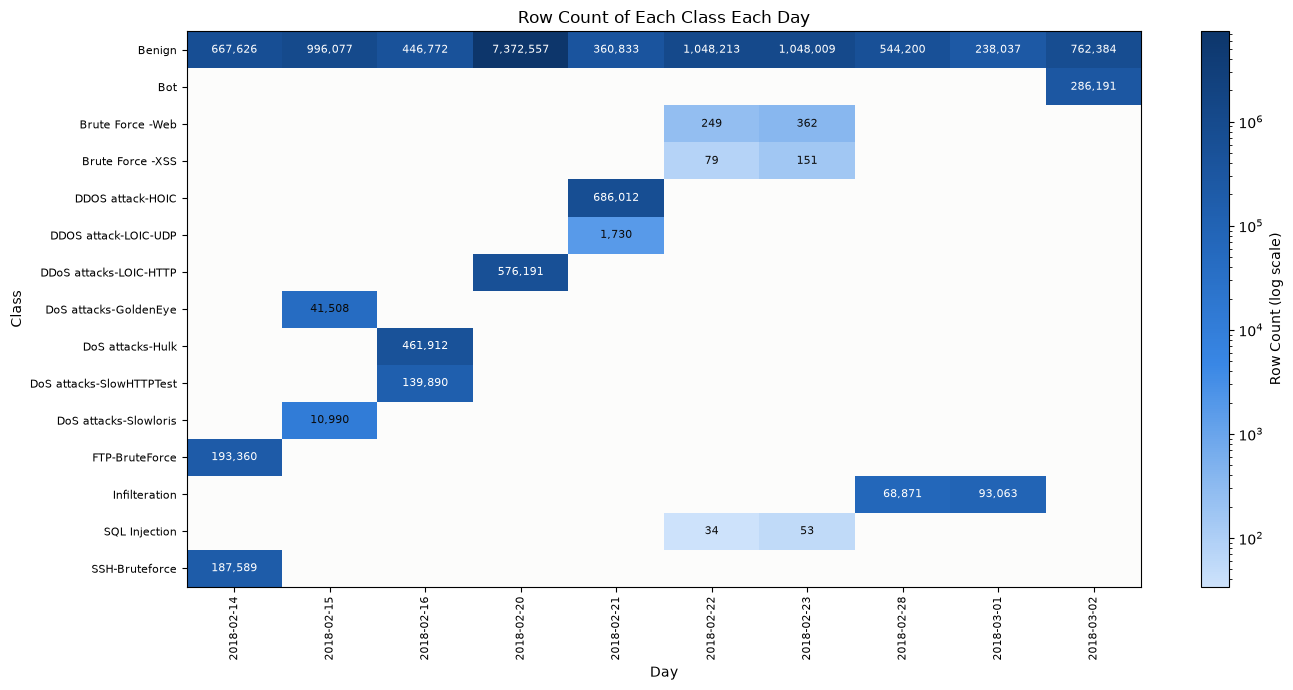

In [68]:
plot_heatmap(
    results.set_index(DAY_COLUMN).T,
    "Row Count of Each Class Each Day",
    xlabel="Day",
    ylabel="Class",
    log_scale=True,
    annotate=True,
    colorbar_label="Row Count (log scale)",
    figsize=(14, 7),
)

### Plot Label Classes (Total)

In [69]:
def count_total_classes(
    class_counts_per_day: pd.DataFrame,
    day_column: str = DAY_COLUMN,
    class_column: str = CLASS_COLUMN,
    row_count_column: str = ROW_COUNT_COLUMN,
    percentage_column: str = PERCENTAGE_COLUMN,
) -> pd.DataFrame:
    totals = class_counts_per_day.drop(columns=day_column).sum()
    totals = totals.rename_axis(class_column).reset_index(name=row_count_column)
    totals[percentage_column] = totals[row_count_column] / totals[row_count_column].sum() * 100
    return totals.sort_values(row_count_column, ascending=False, ignore_index=True)

,class,rows,percentage
0,Benign,13484708,83.070014
1,DDOS attack-HOIC,686012,4.226048
2,DDoS attacks-LOIC-HTTP,576191,3.549517
3,DoS attacks-Hulk,461912,2.845522
4,Bot,286191,1.763026
5,FTP-BruteForce,193360,1.191158
6,SSH-Bruteforce,187589,1.155607
7,Infilteration,161934,0.997564
8,DoS attacks-SlowHTTPTest,139890,0.861766
9,DoS attacks-GoldenEye,41508,0.255702


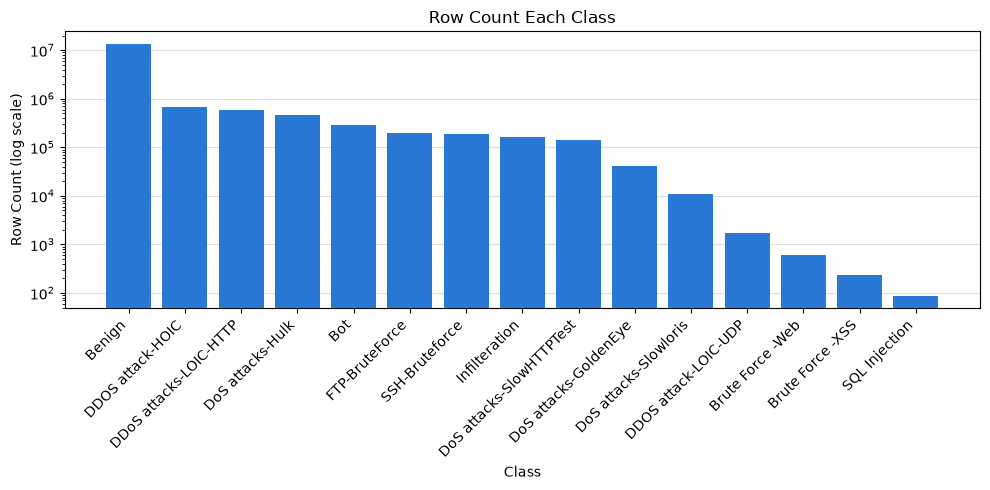

In [70]:
results = count_total_classes(results)
display(results)
plot_bar(
    results,
    CLASS_COLUMN,
    ROW_COUNT_COLUMN,
    "Row Count Each Class",
    "Class",
    "Row Count (log scale)",
    log_scale=True,
)
del results

## Descriptive Statistics

In [71]:
def describe_a_single_feature(
    feature: str,
    folder_path: str = PATH_FOLDER_PARQUET_DATASET,
    feature_column: str = FEATURE_COLUMN,
) -> dict:
    values = pl.col(feature).cast(pl.Float64)
    finite_values = values.filter(values.is_finite())

    statistics = pl.scan_parquet(os.path.join(folder_path, "*.parquet")).select(
        pl.len().alias(ROW_COUNT_COLUMN),
        values.null_count().alias(MISSING_COUNT_COLUMN),
        values.is_nan().sum().alias(NAN_COUNT_COLUMN),
        values.is_infinite().sum().alias(INFINITE_COUNT_COLUMN),
        finite_values.min().alias("min"),
        finite_values.max().alias("max"),
        finite_values.mean().alias("mean"),
        finite_values.median().alias("median"),
        finite_values.std().alias("std"),
        (values < 0).sum().alias("negative"),
        (values == 0).sum().alias("zero"),
        values.drop_nulls().n_unique().alias(UNIQUE_COUNT_COLUMN),
    )
    return {feature_column: feature, **statistics.collect().row(0, named=True)}

In [72]:
def describe_all_features(folder_path: str = PATH_FOLDER_PARQUET_DATASET) -> pd.DataFrame:
    feature_columns = get_feature_columns(folder_path)

    records = []
    started = time.time()
    for feature_index, feature in enumerate(feature_columns, start=1):
        records.append(describe_a_single_feature(feature, folder_path))
        print_progress(feature_index, len(feature_columns), prefix="Describing features", started=started)

    end_status(f"Described {len(feature_columns)} features")
    return pd.DataFrame(records)

In [73]:
descriptive_statistics = describe_all_features()
with pd.option_context("display.max_rows", None):
    display(descriptive_statistics)

Described 78 features                                                           psed ~00:00:00 left


,feature,rows,missing,nan,infinite,min,max,mean,median,std,negative,zero,unique
0,ack_flag_cnt,16232943,0,0,0,0.000000e+00,1.000000e+00,3.316020e-01,0.000000,4.707888e-01,0,10850066,2
1,active_max,16232943,0,0,0,0.000000e+00,1.140000e+08,2.623920e+05,0.000000,3.319230e+06,0,14605586,905146
2,active_mean,16232943,0,0,0,0.000000e+00,1.140000e+08,1.728776e+05,0.000000,2.505927e+06,0,14605586,1192290
3,active_min,16232943,0,0,0,0.000000e+00,1.140000e+08,1.154657e+05,0.000000,2.114145e+06,0,14605586,427163
4,active_std,16232943,0,0,0,0.000000e+00,7.523242e+07,8.644097e+04,0.000000,1.514575e+06,0,15107385,1009594
5,bwd_blk_rate_avg,16232943,0,0,0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0,16232943,1
6,bwd_byts_b_avg,16232943,0,0,0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0,16232943,1
7,bwd_header_len,16232943,0,0,0,0.000000e+00,2.462372e+06,1.330935e+02,16.000000,3.265496e+03,0,4148558,7366
8,bwd_iat_max,16232943,0,0,0,0.000000e+00,1.200000e+08,2.612947e+06,0.000000,1.024426e+07,0,9337704,1892963
9,bwd_iat_mean,16232943,0,0,0,0.000000e+00,1.200000e+08,8.241998e+05,0.000000,4.340497e+06,0,9337704,3875884


## Infinite Values

In [74]:
def find_affected_features(
    descriptive_statistics: pd.DataFrame,
    count_column: str,
    feature_column: str = FEATURE_COLUMN,
    row_count_column: str = ROW_COUNT_COLUMN,
    percentage_column: str = PERCENTAGE_COLUMN,
) -> pd.DataFrame:
    is_affected = descriptive_statistics[count_column] > 0
    columns = [feature_column, count_column, row_count_column]
    affected = descriptive_statistics.loc[is_affected, columns].copy()
    affected[percentage_column] = affected[count_column] / affected[row_count_column] * 100
    affected = affected.drop(columns=row_count_column)
    return affected.sort_values(count_column, ascending=False, ignore_index=True)

In [75]:
results = find_affected_features(descriptive_statistics, INFINITE_COUNT_COLUMN)
display(results)
del results

,feature,infinite,percentage
0,flow_pkts_s,95760,0.589912
1,flow_byts_s,36039,0.222011


## Missing Values

In [76]:
results = find_affected_features(descriptive_statistics, MISSING_COUNT_COLUMN)
display(results)
del results

,feature,missing,percentage
0,flow_byts_s,59721,0.3679


## NaN

In [77]:
results = find_affected_features(descriptive_statistics, NAN_COUNT_COLUMN)
display(results)
del results

,feature,nan,percentage


## Constant Features

In [78]:
def find_constant_features(
    descriptive_statistics: pd.DataFrame,
    feature_column: str = FEATURE_COLUMN,
    unique_count_column: str = UNIQUE_COUNT_COLUMN,
) -> pd.DataFrame:
    is_constant = descriptive_statistics[unique_count_column] <= 1
    columns = [feature_column, "min", unique_count_column]
    return descriptive_statistics.loc[is_constant, columns].reset_index(drop=True)

In [79]:
results = find_constant_features(descriptive_statistics)
display(results)
del results

,feature,min,unique
0,bwd_blk_rate_avg,0.0,1
1,bwd_byts_b_avg,0.0,1
2,bwd_pkts_b_avg,0.0,1
3,bwd_psh_flags,0.0,1
4,bwd_urg_flags,0.0,1
5,fwd_blk_rate_avg,0.0,1
6,fwd_byts_b_avg,0.0,1
7,fwd_pkts_b_avg,0.0,1


## Correlation Heatmaps

In [80]:
def get_varying_features(
    descriptive_statistics: pd.DataFrame,
    feature_column: str = FEATURE_COLUMN,
    unique_count_column: str = UNIQUE_COUNT_COLUMN,
) -> list[str]:
    is_varying = descriptive_statistics[unique_count_column] > 1
    return descriptive_statistics.loc[is_varying, feature_column].tolist()

In [81]:
def compute_covariance_in_a_single_file(
    file_path: str,
    feature_columns: list[str],
) -> tuple[int, np.ndarray, np.ndarray]:
    features = pd.read_parquet(file_path, columns=feature_columns).to_numpy(dtype=np.float64)
    features = features[np.isfinite(features).all(axis=1)]

    row_count = len(features)
    if row_count == 0:
        feature_count = len(feature_columns)
        return 0, np.zeros(feature_count), np.zeros((feature_count, feature_count))

    mean = features.mean(axis=0)
    features -= mean
    return row_count, mean, features.T @ features

In [82]:
def merge_covariance_statistics(first: tuple, second: tuple) -> tuple:
    first_row_count, first_mean, first_cross_products = first
    second_row_count, second_mean, second_cross_products = second

    row_count = first_row_count + second_row_count
    if row_count == 0:
        return first

    delta = second_mean - first_mean
    mean = first_mean + delta * second_row_count / row_count
    correction = np.outer(delta, delta) * first_row_count * second_row_count / row_count
    cross_products = first_cross_products + second_cross_products + correction
    return row_count, mean, cross_products

In [83]:
def compute_correlation_in_all_files(
    feature_columns: list[str],
    folder_path: str = PATH_FOLDER_PARQUET_DATASET,
    n_jobs: int = EDA_N_JOBS,
) -> pd.DataFrame:
    file_paths = get_file_paths_in_folder(folder_path, "parquet")
    tasks = create_tasks_list(compute_covariance_in_a_single_file, file_paths, feature_columns)

    results = run_tasks_in_parallel(tasks, n_jobs, f"Correlating {len(feature_columns)} features")
    end_status(f"Correlated {len(feature_columns)} features in {len(tasks)} files")

    total = results[0]
    for result in results[1:]:
        total = merge_covariance_statistics(total, result)

    _, _, cross_products = total
    standard_deviations = np.sqrt(np.diag(cross_products))
    correlation = cross_products / np.outer(standard_deviations, standard_deviations)
    return pd.DataFrame(correlation, index=feature_columns, columns=feature_columns)

In [84]:
def find_highly_correlated_pairs(
    correlation: pd.DataFrame,
    threshold: float = CORRELATION_THRESHOLD,
    feature_column: str = FEATURE_COLUMN,
    correlation_column: str = CORRELATION_COLUMN,
) -> pd.DataFrame:
    other_feature_column = f"other_{feature_column}"
    features = correlation.columns.tolist()

    records = []
    for first_index in range(len(features)):
        for second_index in range(first_index + 1, len(features)):
            value = correlation.iat[first_index, second_index]
            if abs(value) >= threshold:
                record = {
                    feature_column: features[first_index],
                    other_feature_column: features[second_index],
                    correlation_column: value,
                }
                records.append(record)

    pairs = pd.DataFrame(records, columns=[feature_column, other_feature_column, correlation_column])
    return pairs.sort_values(correlation_column, key=abs, ascending=False, ignore_index=True)

Correlated 70 features in 168 files                                             02 elapsed ~00:00:00 left


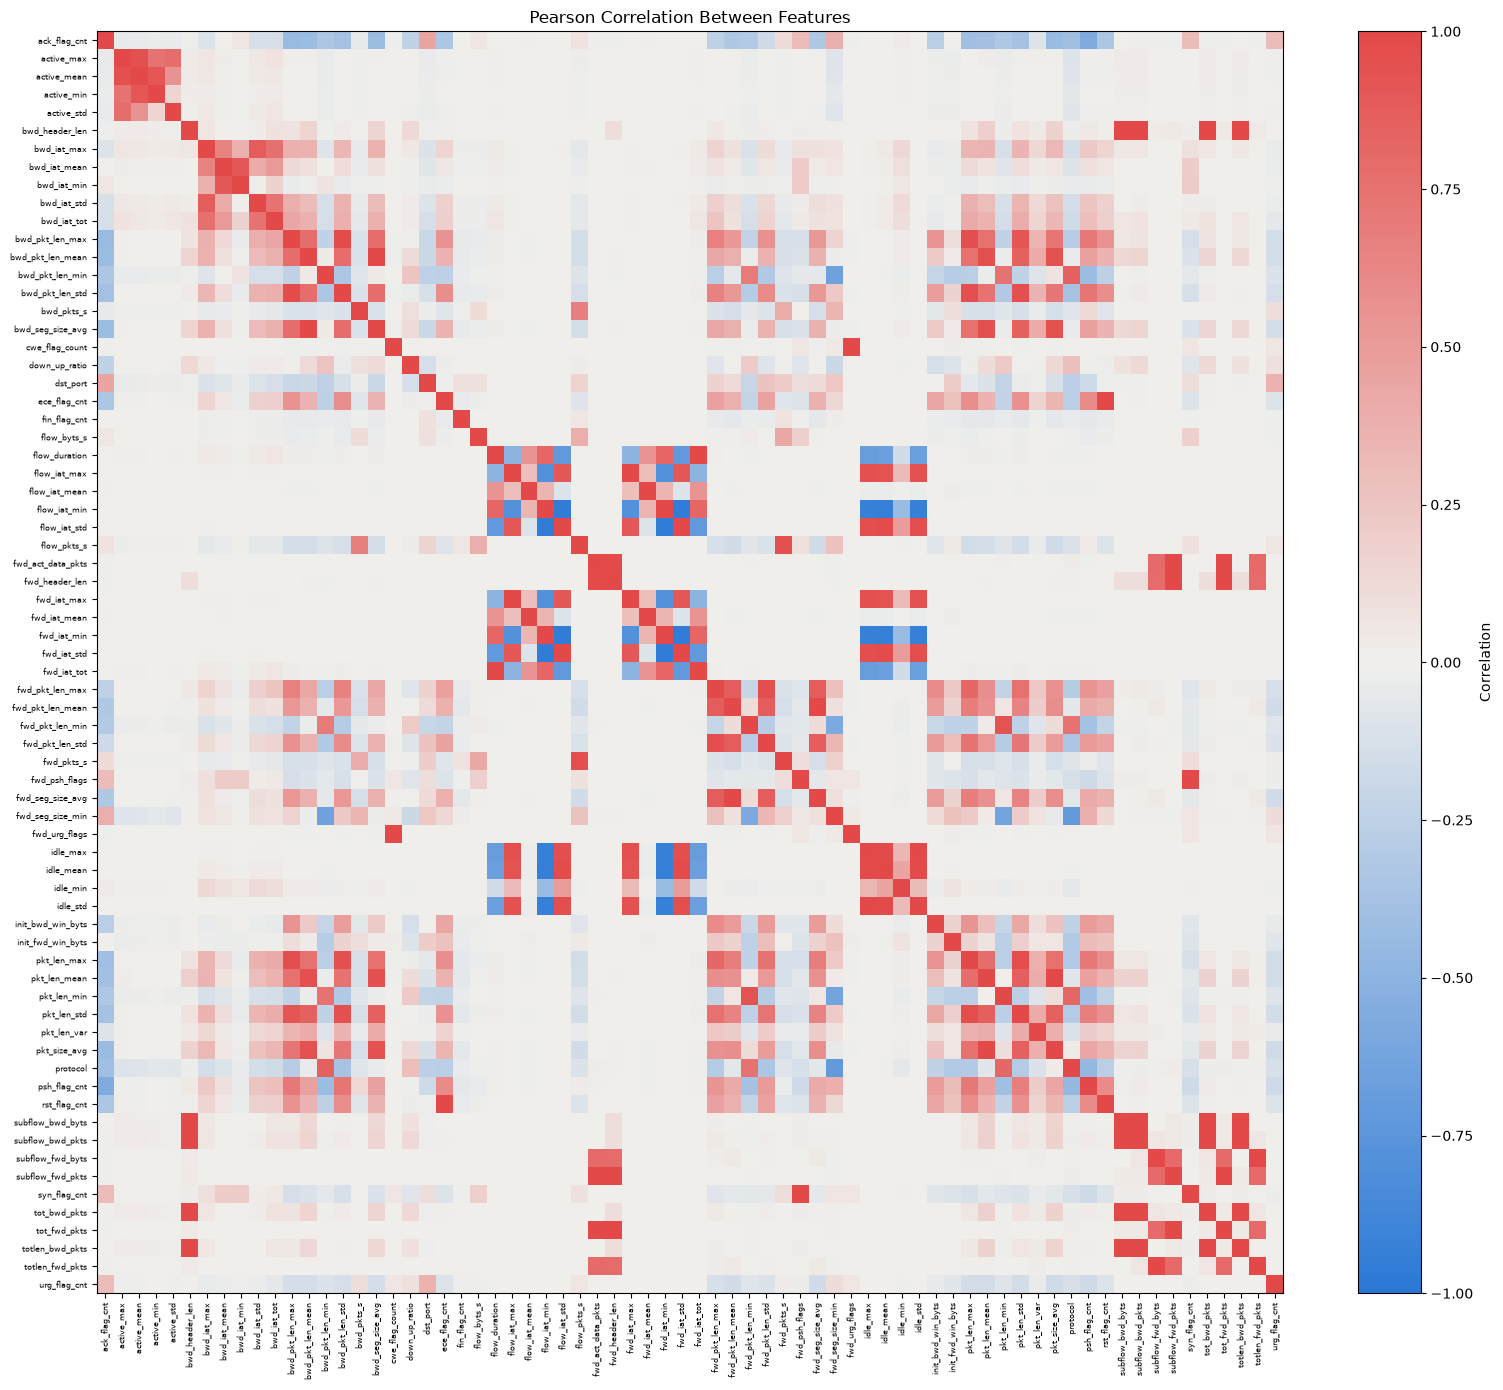

In [85]:
correlation = compute_correlation_in_all_files(get_varying_features(descriptive_statistics))
plot_heatmap(
    correlation,
    "Pearson Correlation Between Features",
    colormap=DIVERGING_COLORMAP,
    value_range=(-1, 1),
    colorbar_label="Correlation",
    figsize=(16, 14),
    font_size=6,
)

### Highly Correlated Features

In [86]:
results = find_highly_correlated_pairs(correlation)
with pd.option_context("display.max_rows", None):
    display(results)
del results, correlation, descriptive_statistics

,feature,other_feature,correlation
0,subflow_bwd_pkts,tot_bwd_pkts,1.000000
1,fwd_psh_flags,syn_flag_cnt,1.000000
2,fwd_pkt_len_mean,fwd_seg_size_avg,1.000000
3,subflow_fwd_pkts,tot_fwd_pkts,1.000000
4,cwe_flag_count,fwd_urg_flags,1.000000
5,bwd_pkt_len_mean,bwd_seg_size_avg,1.000000
6,subflow_fwd_byts,totlen_fwd_pkts,1.000000
7,subflow_bwd_byts,totlen_bwd_pkts,1.000000
8,flow_iat_min,fwd_iat_min,0.999996
9,flow_iat_max,fwd_iat_max,0.999994


# Data Cleaning

In [87]:
CONSTANT_FEATURES = [
    "bwd_blk_rate_avg",
    "bwd_byts_b_avg",
    "bwd_pkts_b_avg",
    "bwd_psh_flags",
    "bwd_urg_flags",
    "fwd_blk_rate_avg",
    "fwd_byts_b_avg",
    "fwd_pkts_b_avg",
]

ROWS_BEFORE_COLUMN = "rows_before"
MISSING_ROWS_COLUMN = "missing_rows_removed"
INFINITE_ROWS_COLUMN = "infinite_rows_removed"
ROWS_AFTER_COLUMN = "rows_after"

CLEANING_N_JOBS = 8

## Remove Constant Features

In [88]:
def remove_constant_features(
    dataframe: pd.DataFrame,
    constant_features: list[str] = CONSTANT_FEATURES,
) -> pd.DataFrame:
    return dataframe.drop(columns=constant_features)

## Remove Missing Values

In [89]:
def remove_missing_value_rows(dataframe: pd.DataFrame) -> pd.DataFrame:
    return dataframe.dropna()

## Remove Infinite Values

In [90]:
def remove_infinite_value_rows(dataframe: pd.DataFrame) -> pd.DataFrame:
    numeric_columns = dataframe.select_dtypes("number").columns
    has_infinite_value = np.isinf(dataframe[numeric_columns]).any(axis=1)
    return dataframe[~has_infinite_value]

## Clean A Single File

In [91]:
def clean_a_single_file(
    file_path: str,
    output_folder_path: str = PATH_FOLDER_CLEANED_DATASET,
    constant_features: list[str] = CONSTANT_FEATURES,
    file_column: str = FILE_COLUMN,
) -> dict:
    dataframe = pd.read_parquet(file_path)
    row_count_before = len(dataframe)

    dataframe = remove_constant_features(dataframe, constant_features)
    dataframe = remove_missing_value_rows(dataframe)
    row_count_after_missing = len(dataframe)
    dataframe = remove_infinite_value_rows(dataframe)
    row_count_after = len(dataframe)

    file_name = os.path.basename(file_path)
    os.makedirs(output_folder_path, exist_ok=True)
    dataframe.to_parquet(os.path.join(output_folder_path, file_name), index=False)

    return {
        file_column: file_name,
        ROWS_BEFORE_COLUMN: row_count_before,
        MISSING_ROWS_COLUMN: row_count_before - row_count_after_missing,
        INFINITE_ROWS_COLUMN: row_count_after_missing - row_count_after,
        ROWS_AFTER_COLUMN: row_count_after,
    }

## Clean All Files

In [92]:
def clean_all_files(
    input_folder_path: str = PATH_FOLDER_PARQUET_DATASET,
    output_folder_path: str = PATH_FOLDER_CLEANED_DATASET,
    n_jobs: int = CLEANING_N_JOBS,
) -> pd.DataFrame:
    file_paths = get_file_paths_in_folder(input_folder_path, "parquet")
    tasks = create_tasks_list(clean_a_single_file, file_paths, output_folder_path)

    records = run_tasks_in_parallel(tasks, n_jobs, "Cleaning files")
    summary = pd.DataFrame(records)

    rows_before = summary[ROWS_BEFORE_COLUMN].sum()
    rows_after = summary[ROWS_AFTER_COLUMN].sum()
    end_status(f"Cleaned {len(tasks)} files: {rows_before:,} rows -> {rows_after:,} rows")
    return summary

## Cleaning

In [93]:
results = group_and_sum(clean_all_files(), FILE_COLUMN, DAY_COLUMN, DAY_REGEX)
display(results)
del results

Cleaned 168 files: 16,232,943 rows -> 16,137,183 rows                           d ~00:00:00 left


,day,rows_before,missing_rows_removed,infinite_rows_removed,rows_after
0,2018-02-14,1048575,2277,1547,1044751
1,2018-02-15,1048575,4921,3106,1040548
2,2018-02-16,1048574,0,0,1048574
3,2018-02-20,7948748,36767,22686,7889295
4,2018-02-21,1048575,0,0,1048575
5,2018-02-22,1048575,3569,2041,1042965
6,2018-02-23,1048575,3754,1954,1042867
7,2018-02-28,613071,4041,2128,606902
8,2018-03-01,331100,1834,1085,328181
9,2018-03-02,1048575,2558,1492,1044525


# Remove Duplicate Values

In [94]:
DUPLICATE_ROWS_COLUMN = "duplicate_rows_removed"

ROW_HASH_SEEDS = (0, 1)
DEDUPLICATION_N_JOBS = 8

## Hash Rows

In [95]:
def hash_rows_in_a_single_file(
    file_path: str,
    hash_seeds: tuple[int, ...] = ROW_HASH_SEEDS,
) -> np.ndarray:
    row = pl.struct(pl.all())
    hash_columns = []
    for hash_seed in hash_seeds:
        hash_columns.append(row.hash(hash_seed).alias(f"hash_{hash_seed}"))
    return pl.read_parquet(file_path).select(hash_columns).to_numpy()

In [96]:
def hash_rows_in_all_files(
    file_paths: list[str],
    n_jobs: int = DEDUPLICATION_N_JOBS,
) -> list[np.ndarray]:
    tasks = create_tasks_list(hash_rows_in_a_single_file, file_paths)
    return run_tasks_in_parallel(tasks, n_jobs, "Hashing rows")

## Find Duplicate Rows

In [97]:
def find_duplicate_rows(row_hashes: list[np.ndarray]) -> np.ndarray:
    hashes = pd.DataFrame(np.concatenate(row_hashes))
    return hashes.duplicated(keep="first").to_numpy()

In [98]:
def get_row_offsets(file_paths: list[str], per_file_rows: list[np.ndarray]) -> dict[str, int]:
    row_offsets = {}
    row_offset = 0
    for file_path, file_rows in zip(file_paths, per_file_rows):
        row_offsets[os.path.basename(file_path)] = row_offset
        row_offset += len(file_rows)
    return row_offsets

## Remove Duplicates In A Single File

In [99]:
def remove_duplicate_rows_in_a_single_file(
    file_path: str,
    is_duplicate: np.ndarray,
    row_offsets: dict[str, int],
    output_folder_path: str = PATH_FOLDER_DEDUPLICATED_DATASET,
    file_column: str = FILE_COLUMN,
) -> dict:
    file_name = os.path.basename(file_path)
    dataframe = pd.read_parquet(file_path)
    row_count_before = len(dataframe)

    row_offset = row_offsets[file_name]
    is_duplicate_in_file = is_duplicate[row_offset:row_offset + row_count_before]
    dataframe = dataframe[~is_duplicate_in_file]
    row_count_after = len(dataframe)

    os.makedirs(output_folder_path, exist_ok=True)
    dataframe.to_parquet(os.path.join(output_folder_path, file_name), index=False)

    return {
        file_column: file_name,
        ROWS_BEFORE_COLUMN: row_count_before,
        DUPLICATE_ROWS_COLUMN: row_count_before - row_count_after,
        ROWS_AFTER_COLUMN: row_count_after,
    }

## Remove Duplicates In All Files

In [100]:
def remove_duplicate_rows_in_all_files(
    input_folder_path: str = PATH_FOLDER_CLEANED_DATASET,
    output_folder_path: str = PATH_FOLDER_DEDUPLICATED_DATASET,
    n_jobs: int = DEDUPLICATION_N_JOBS,
) -> pd.DataFrame:
    file_paths = get_file_paths_in_folder(input_folder_path, "parquet")

    row_hashes = hash_rows_in_all_files(file_paths, n_jobs)
    print_status("Finding duplicate rows")
    is_duplicate = find_duplicate_rows(row_hashes)
    row_offsets = get_row_offsets(file_paths, row_hashes)
    del row_hashes

    tasks = create_tasks_list(
        remove_duplicate_rows_in_a_single_file,
        file_paths,
        is_duplicate,
        row_offsets,
        output_folder_path,
    )
    records = run_tasks_in_parallel(tasks, n_jobs, f"Removing {is_duplicate.sum():,} duplicate rows")
    summary = pd.DataFrame(records)

    rows_before = summary[ROWS_BEFORE_COLUMN].sum()
    rows_after = summary[ROWS_AFTER_COLUMN].sum()
    end_status(f"Removed duplicates from {len(tasks)} files: {rows_before:,} rows -> {rows_after:,} rows")
    return summary

## Deduplication

In [101]:
results = group_and_sum(remove_duplicate_rows_in_all_files(), FILE_COLUMN, DAY_COLUMN, DAY_REGEX)
display(results)
del results

Hashing rows |█-----------------------------| 9/168 (5%) | 00:00:00 elapsed, ~00:00:15 left

/home/joshuans/miniforge3/envs/rapids/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Removed duplicates from 168 files: 16,137,183 rows -> 11,445,955 rows           ) | 00:00:06 elapsed ~00:00:00 left


,day,rows_before,duplicate_rows_removed,rows_after
0,2018-02-14,1044751,373970,670781
1,2018-02-15,1040548,210727,829821
2,2018-02-16,1048574,456675,591899
3,2018-02-20,7889295,1975627,5913668
4,2018-02-21,1048575,487201,561374
5,2018-02-22,1042965,257342,785623
6,2018-02-23,1042867,257276,785591
7,2018-02-28,606902,267638,339264
8,2018-03-01,328181,91818,236363
9,2018-03-02,1044525,312954,731571


## Class Distribution After Deduplication

In [102]:
results = group_and_sum(
    count_classes_in_all_files(PATH_FOLDER_DEDUPLICATED_DATASET),
    FILE_COLUMN,
    DAY_COLUMN,
    DAY_REGEX,
)
results = count_total_classes(results)
display(results)
del results

Counted classes in 168 files                                                    sed ~00:00:00 left


,class,rows,percentage
0,Benign,10095152,88.198425
1,DDoS attacks-LOIC-HTTP,575012,5.023714
2,DDOS attack-HOIC,198861,1.737391
3,DoS attacks-Hulk,145199,1.268562
4,Bot,144535,1.262761
5,Infilteration,139341,1.217382
6,SSH-Bruteforce,94048,0.821670
7,DoS attacks-GoldenEye,41392,0.361630
8,DoS attacks-Slowloris,9712,0.084851
9,DDOS attack-LOIC-UDP,1730,0.015115


# Splitting Datasets (Train, Dev/Val, Test)

In [103]:
TEST_SIZE = 0.2

In [104]:
TRAIN_ROWS_COLUMN = "train_rows"
TEST_ROWS_COLUMN = "test_rows"
TEST_PERCENTAGE_COLUMN = "test_percentage"

## Assign Test Rows

In [105]:
def assign_test_rows(
    dataset: pl.LazyFrame,
    label_column: str = LABEL_COLUMN,
    test_size: float = TEST_SIZE,
    random_state: int = RANDOM_STATE,
) -> pl.Series:
    label_codes = pl.col(label_column).cast(pl.Enum(load_classes_list())).to_physical()
    labels = dataset.select(label_codes).collect().to_series().to_numpy()

    row_indices = np.arange(len(labels))
    _, test_row_indices = train_test_split(
        row_indices,
        test_size=test_size,
        stratify=labels,
        random_state=random_state,
    )
    return pl.Series(ROW_INDEX_COLUMN, test_row_indices).cast(pl.get_index_type())

## Write Features And Labels

In [106]:
def write_features_and_labels(
    split: pl.LazyFrame,
    split_folder_path: str,
    label_column: str = LABEL_COLUMN,
    row_index_column: str = ROW_INDEX_COLUMN,
) -> None:
    os.makedirs(split_folder_path, exist_ok=True)

    features = split.drop(row_index_column, label_column)
    labels = split.select(label_column)
    features.sink_parquet(os.path.join(split_folder_path, FEATURES_FILE_NAME))
    labels.sink_parquet(os.path.join(split_folder_path, LABELS_FILE_NAME))

## Split Dataset

In [107]:
def split_dataset(
    input_folder_path: str = PATH_FOLDER_DEDUPLICATED_DATASET,
    train_folder_path: str = PATH_FOLDER_SPLITTED_DATASET_TRAIN,
    test_folder_path: str = PATH_FOLDER_SPLITTED_DATASET_TEST,
    row_index_column: str = ROW_INDEX_COLUMN,
) -> None:
    dataset = load_all_files(input_folder_path, row_index_column)
    row_count = dataset.select(pl.len()).collect().item()

    print_status(f"Assigning {row_count:,} rows to train and test")
    test_row_indices = assign_test_rows(dataset)
    is_test_row = pl.col(row_index_column).is_in(test_row_indices.implode())

    print_status("Writing the train split")
    write_features_and_labels(dataset.filter(~is_test_row), train_folder_path)
    print_status("Writing the test split")
    write_features_and_labels(dataset.filter(is_test_row), test_folder_path)

    test_row_count = len(test_row_indices)
    train_row_count = row_count - test_row_count
    end_status(f"Split {row_count:,} rows: {train_row_count:,} train rows, {test_row_count:,} test rows")

## Splitting

In [108]:
split_dataset()

Split 11,445,955 rows: 9,156,764 train rows, 2,289,191 test rows                


## Class Distribution Per Split

In [109]:
def summarize_split_classes(
    train_folder_path: str = PATH_FOLDER_SPLITTED_DATASET_TRAIN,
    test_folder_path: str = PATH_FOLDER_SPLITTED_DATASET_TEST,
    class_column: str = CLASS_COLUMN,
) -> pd.DataFrame:
    summary = pd.DataFrame({
        TRAIN_ROWS_COLUMN: count_classes_in_split(train_folder_path),
        TEST_ROWS_COLUMN: count_classes_in_split(test_folder_path),
    })
    total_rows = summary[TRAIN_ROWS_COLUMN] + summary[TEST_ROWS_COLUMN]
    summary[TEST_PERCENTAGE_COLUMN] = summary[TEST_ROWS_COLUMN] / total_rows * 100

    summary = summary.rename_axis(class_column).reset_index()
    return summary.sort_values(TRAIN_ROWS_COLUMN, ascending=False, ignore_index=True)

In [110]:
results = summarize_split_classes()
display(results)
del results

,class,train_rows,test_rows,test_percentage
0,Benign,8076122,2019030,19.999996
1,DDoS attacks-LOIC-HTTP,460010,115002,19.999930
2,DDOS attack-HOIC,159089,39772,19.999899
3,DoS attacks-Hulk,116159,29040,20.000138
4,Bot,115628,28907,20.000000
5,Infilteration,111473,27868,19.999856
6,SSH-Bruteforce,75238,18810,20.000425
7,DoS attacks-GoldenEye,33114,8278,19.999034
8,DoS attacks-Slowloris,7770,1942,19.995881
9,DDOS attack-LOIC-UDP,1384,346,20.000000


# Encode Classes' Label

## Load and Dump LabelEncoder

In [90]:
def load_label_encoder(label_encoder_path:str = PATH_LABEL_ENCODER_TRANSFORMER) -> LabelEncoder:
    return load(label_encoder_path)

In [91]:
def dump_label_encoder(label_encoder:LabelEncoder,label_encoder_path:str = PATH_LABEL_ENCODER_TRANSFORMER) -> None:
    dump(label_encoder,label_encoder_path)

## Make Label Encoder

In [92]:
def create_label_encoding()->LabelEncoder:
    encoder = LabelEncoder()
    classes_list = load_classes_list()
    encoder.fit(classes_list)
    dump_label_encoder(encoder)
    return encoder

In [93]:
create_label_encoding()

LabelEncoder()

## Encode and Decode Labels

In [94]:
def encode_labels(dataframe: pd.DataFrame, column: str = LABEL_COLUMN) -> pd.DataFrame:
    encoder = load_label_encoder()
    df = dataframe.copy()
    df[column] = encoder.transform(dataframe[column])
    return df

In [95]:
def encode_polar_labels(dataset: pl.LazyFrame, column: str = LABEL_COLUMN) -> pl.LazyFrame:
    classes = load_label_encoder().classes_.tolist()
    codes = list(range(len(classes)))
    return dataset.with_columns(pl.col(column).replace_strict(classes, codes, return_dtype=pl.Int64))

In [96]:
def decode_labels(dataframe: pd.DataFrame, column: str = LABEL_COLUMN) -> pd.DataFrame:
    encoder = load_label_encoder()
    df = dataframe.copy()
    df[column] = encoder.inverse_transform(df[column].astype(int))
    return df

## Encode Train and Test Labels

In [97]:
def encode_train_and_test_labels(output_name:str=ENCODED_LABELS_FILE_NAME):
    for folder in (PATH_FOLDER_SPLITTED_DATASET_TRAIN, PATH_FOLDER_SPLITTED_DATASET_TEST):
        print_status(f"Encoding labels in {folder}")
        labels = pl.scan_parquet(os.path.join(folder, LABELS_FILE_NAME))
        encode_polar_labels(labels).sink_parquet(os.path.join(folder, output_name))
    end_status("Encoded labels in the train and test splits")

In [98]:
encode_train_and_test_labels()

Encoded labels in the train and test splits                                     


# Pipeline

In [99]:
PCA_VARIANCE_THRESHOLD = 0.95
CUML_VERBOSE = 3  # cuML logs warnings and errors only

# rows of each class after SMOTE, as a ratio to the majority class rows of the fit, None leaves the class as it is
# from the mean validation F1 without SMOTE: >= 0.95 gets x1.25, 0.90-0.95 x2 (min 0.004), below 0.90 x3 (min 0.002)
SMOTE_CLASS_RATIOS = {
    "Benign": None,
    "DDoS attacks-LOIC-HTTP": 0.071,
    "DDOS attack-HOIC": 0.025,
    "DoS attacks-Hulk": 0.018,
    "Bot": 0.018,
    "Infilteration": 0.041,
    "SSH-Bruteforce": 0.012,
    "DoS attacks-GoldenEye": 0.0082,
    "DoS attacks-Slowloris": 0.004,
    "DDOS attack-LOIC-UDP": 0.002,
    "Brute Force -Web": 0.002,
    "Brute Force -XSS": 0.002,
    "SQL Injection": 0.002,
    "DoS attacks-SlowHTTPTest": 0.002,
    "FTP-BruteForce": 0.002,
}

## Shared Steps

In [100]:
class ProgressPipeline(Pipeline):
    def fit(self, X, y=None, progress: Any = None, **params):
        self.progress_ = progress
        # cuML's multiclass SVC sits in a reference cycle, so a dead fit keeps its GPU memory until the cycle collector runs
        gc.collect()
        try:
            super().fit(X, y, **params)
        except Exception:
            self.report_progress("failed")
            raise
        self.report_progress("fitted")
        return self

    # the scorers predict the validation rows after every fit, and for KNN that takes far longer than the fit
    def predict(self, X, **params):
        try:
            predictions = super().predict(X, **params)
        except Exception:
            self.report_progress("failed")
            raise
        self.report_progress("scored")
        return predictions

    def report_progress(self, event: str) -> None:
        progress = getattr(self, "progress_", None)
        if progress is None:
            return
        progress.put(event)
        if event != "fitted":
            self.progress_ = None  # each fit ends once, although every scorer retries a failed predict

In [101]:
def make_preprocessing_steps(pca_variance_threshold: float = PCA_VARIANCE_THRESHOLD) -> list[tuple[str, Any]]:
    return [
        ("cast", FunctionTransformer(_to_float32)),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=pca_variance_threshold, random_state=RANDOM_STATE)),
    ]

In [102]:
def make_smote_targets(labels: np.ndarray, class_ratios: dict[int, float]) -> dict[int, int]:
    classes, class_counts = np.unique(labels, return_counts=True)
    majority_count = class_counts.max()
    targets = {}
    for class_code, class_count in zip(classes, class_counts):
        if class_code not in class_ratios:
            continue
        target = int(round(class_ratios[class_code] * majority_count))
        # SMOTE cannot remove rows, so a class that already reaches its target keeps its rows
        if target > class_count:
            targets[int(class_code)] = target
    return targets

In [103]:
def make_smote(class_ratios: dict[str, float | None] = SMOTE_CLASS_RATIOS) -> SMOTE:
    class_names = load_label_encoder().classes_.tolist()
    missing_classes = sorted(set(class_names) - set(class_ratios))
    unknown_classes = sorted(set(class_ratios) - set(class_names))
    if missing_classes or unknown_classes:
        raise ValueError(f"SMOTE_CLASS_RATIOS has to list every class, missing {missing_classes}, unknown {unknown_classes}")

    code_ratios = {}
    for class_code, class_name in enumerate(class_names):
        if class_ratios[class_name] is not None:
            code_ratios[class_code] = class_ratios[class_name]
    # the targets are counted on the rows of each fit, so a grid search sample gets the same class shares as the final fit
    return SMOTE(sampling_strategy=partial(make_smote_targets, class_ratios=code_ratios), random_state=RANDOM_STATE)

In [104]:
def make_model_pipeline(model_name: str, model: Any, use_smote: bool = True) -> Pipeline:
    steps = []
    if use_smote:
        steps.append(("smote", make_smote()))
    steps.append((model_name, model))
    return ProgressPipeline(steps)

## K-Nearest-Neighbors

In [105]:
def make_knn_pipeline(use_smote: bool = True) -> Pipeline:
    return make_model_pipeline("knn", KNeighborsClassifier(verbose=CUML_VERBOSE), use_smote)

## Support Vector Machine

In [106]:
SVM_STALL_ERROR = "Working set has already been initialized"
SVM_RETRY_CACHE_SIZES = [512.0, 2048.0, 3072.0]

In [107]:
class RetrySVC(SVC):
    """cuML SVC that refits with other kernel cache sizes when cuML's SMO solver stalls.

    The stall ("Working set has already been initialized!") is a cuML bug. The cache size
    changes the order the solver visits the working set, so a refit often gets past it.
    """

    def fit(self, X, y, sample_weight=None):
        cache_size = self.cache_size
        try:
            for retry_cache_size in [cache_size, *SVM_RETRY_CACHE_SIZES]:
                self.cache_size = retry_cache_size
                try:
                    return super().fit(X, y, sample_weight)
                except RuntimeError as error:
                    if SVM_STALL_ERROR not in str(error):
                        raise
            raise RuntimeError(f"{SVM_STALL_ERROR} with every cache size in {SVM_RETRY_CACHE_SIZES}")
        finally:
            self.cache_size = cache_size

In [108]:
def make_svm_pipeline(use_smote: bool = True) -> Pipeline:
    return make_model_pipeline("svm", RetrySVC(verbose=CUML_VERBOSE), use_smote)

## Random Forest

In [109]:
def make_rf_pipeline(use_smote: bool = True) -> Pipeline:
    model = RandomForestClassifier(random_state=RANDOM_STATE, verbose=CUML_VERBOSE)
    return make_model_pipeline("rf", model, use_smote)

## Extreme Gradient Boost

In [110]:
def make_xgb_pipeline(use_smote: bool = True) -> Pipeline:
    model = XGBClassifier(
        device="cuda" if USE_CUDA else "cpu",
        tree_method="hist",
        max_bin=128,
        subsample=0.8,
        random_state=RANDOM_STATE,
    )
    return make_model_pipeline("xgb", model, use_smote)

## Logistic Regression (LogRes) or Softmax

In [111]:
def make_logreg_pipeline(use_smote: bool = True) -> Pipeline:
    return make_model_pipeline("logreg", LogisticRegression(verbose=CUML_VERBOSE), use_smote)

# PCA Transformer

In [112]:
COMPONENT_COLUMN = "component"
EXPLAINED_VARIANCE_COLUMN = "explained_variance_percentage"
CUMULATIVE_VARIANCE_COLUMN = "cumulative_variance_percentage"

## Load Train Split

In [113]:
def load_labels(
    split_folder_path: str,
    labels_file_name: str = ENCODED_LABELS_FILE_NAME,
    label_column: str = LABEL_COLUMN,
) -> pd.Series:
    labels = pl.scan_parquet(os.path.join(split_folder_path, labels_file_name)).select(label_column)
    return labels.collect().to_series().to_pandas()

In [114]:
def load_split(
    split_folder_path: str,
    features_file_name: str = FEATURES_FILE_NAME,
    labels_file_name: str = ENCODED_LABELS_FILE_NAME,
    label_column: str = LABEL_COLUMN,
) -> tuple[pd.DataFrame, pd.Series]:
    features = pl.scan_parquet(os.path.join(split_folder_path, features_file_name))
    features = load_features(features, f"Loading {split_folder_path}")
    labels = load_labels(split_folder_path, labels_file_name, label_column)
    if len(features) != len(labels):
        raise ValueError(f"{split_folder_path}: {len(features):,} feature rows but {len(labels):,} labels")
    return features, labels

## Load and Dump PCA Transformer

In [115]:
def load_pca_transformer(pca_transformer_path: str = PATH_PCA_TRANSFORMER) -> Pipeline:
    return load(pca_transformer_path)

In [116]:
def dump_pca_transformer(pca_transformer: Pipeline, pca_transformer_path: str = PATH_PCA_TRANSFORMER) -> None:
    dump(pca_transformer, pca_transformer_path)

## Make PCA Transformer

In [101]:
def create_pca_transformer(split_folder_path: str = PATH_FOLDER_SPLITTED_DATASET_TRAIN) -> Pipeline:
    features, _ = load_split(split_folder_path)
    print_status(f"Fitting the scaler and PCA on {len(features):,} rows")
    pca_transformer = Pipeline(make_preprocessing_steps()).fit(features)
    dump_pca_transformer(pca_transformer)
    end_status(f"Fitted the scaler and PCA on {len(features):,} rows of {split_folder_path}, saved to {PATH_PCA_TRANSFORMER}")
    return pca_transformer

In [102]:
create_pca_transformer()

Fitted the scaler and PCA on 9,156,764 rows of data-pipeline/04-splitted-parquet/train, saved to cache/pca-transformer.pkl left


Pipeline(steps=[('cast',
                 FunctionTransformer(func=<function _to_float32 at 0x7a9e204d02c0>)),
                ('scaler', StandardScaler()),
                ('pca', PCA(n_components=0.95, random_state=42))])

## Explained Variance

In [103]:
def summarize_explained_variance(pca: PCA) -> pd.DataFrame:
    component_count = len(pca.explained_variance_ratio_)
    return pd.DataFrame({
        COMPONENT_COLUMN: np.arange(1, component_count + 1),
        EXPLAINED_VARIANCE_COLUMN: pca.explained_variance_ratio_ * 100,
        CUMULATIVE_VARIANCE_COLUMN: np.cumsum(pca.explained_variance_ratio_) * 100,
    })

In [104]:
pca = load_pca_transformer().named_steps["pca"]
results = summarize_explained_variance(pca)
kept_variance = results[CUMULATIVE_VARIANCE_COLUMN].iloc[-1]
end_status(
    f"{pca.n_components_} principal components keep {kept_variance:.2f}% of the variance "
    f"(more than {PCA_VARIANCE_THRESHOLD:.0%})"
)
with pd.option_context("display.max_rows", None):
    display(results)
del pca, results, kept_variance

25 principal components keep 95.59% of the variance (more than 95%)             


,component,explained_variance_percentage,cumulative_variance_percentage
0,1,16.029911,16.029911
1,2,13.415505,29.445415
2,3,7.875618,37.321033
3,4,7.173468,44.494503
4,5,6.328940,50.823444
5,6,5.199128,56.022572
6,7,4.719165,60.741734
7,8,4.460383,65.202118
8,9,3.687749,68.889870
9,10,3.328786,72.218658


## Transform Split

In [127]:
def transform_split(
    split_folder_path: str,
    pca_transformer: Pipeline,
    batch_size: int = BATCH_SIZE,
) -> tuple[np.ndarray, pd.Series]:
    features = pl.scan_parquet(os.path.join(split_folder_path, FEATURES_FILE_NAME))
    component_count = pca_transformer.named_steps["pca"].n_components_
    components = np.empty((count_rows(features), component_count), dtype=NUMERIC_DATA_TYPE)
    for row_offset, batch in read_in_batches(features, f"Transforming {split_folder_path}", batch_size):
        components[row_offset:row_offset + len(batch)] = pca_transformer.transform(batch.to_pandas())
    labels = load_labels(split_folder_path)
    if len(components) != len(labels):
        raise ValueError(f"{split_folder_path}: {len(components):,} feature rows but {len(labels):,} labels")
    return components, labels

# Grid Search CV

In [117]:
N_SPLITS = 5
VALIDATION_SIZE = 0.2

# rows each final model is fitted on, None fits it on the full train split
TRAIN_SAMPLE_SIZES = {
    "knn": None,
    "svm": 1_000_000,
    "rf": None,
    "xgb": None,
    "logreg": None,
}
# rows each grid search is tuned on, drawn from the model's training rows, None tunes on all of them
GRID_SEARCH_SAMPLE_SIZES = {
    "knn": 250_000,
    "svm": 200_000,
    "rf": 1_000_000,
    "xgb": 1_000_000,
    "logreg": 1_000_000,
}
MIN_ROWS_PER_CLASS = 20

In [118]:
GRID_SEARCH_SCORING = {
    "f1_macro": partial(f1_score, average="macro", zero_division=0),
    "precision_macro": partial(precision_score, average="macro", zero_division=0),
    "recall_macro": partial(recall_score, average="macro", zero_division=0),
    "f1_weighted": partial(f1_score, average="weighted", zero_division=0),
    "precision_weighted": partial(precision_score, average="weighted", zero_division=0),
    "recall_weighted": partial(recall_score, average="weighted", zero_division=0),
    "accuracy": accuracy_score,
    "balanced_accuracy": balanced_accuracy_score,
    "mcc": matthews_corrcoef,
    "cohen_kappa": cohen_kappa_score,
}
GRID_SEARCH_RANK_METRIC = "f1_macro"
GRID_SEARCH_N_JOBS = 1

In [119]:
USE_SMOTE = False
SMOTE_K_NEIGHBORS_GRID = [3, 5, 7]

## Load Train Components

In [128]:
pca_transformer = load_pca_transformer()
train_components, train_labels = transform_split(PATH_FOLDER_SPLITTED_DATASET_TRAIN, pca_transformer)
end_status(f"Transformed {len(train_labels):,} train rows into {train_components.shape[1]} principal components")

Transforming data-pipeline/04-splitted-parquet/train |------------------------------| 0/19 (0%) | 00:00:00 elapsed

Transformed 9,156,764 train rows into 25 principal components                   ████| 19/19 (100%) | 00:00:06 elapsed ~00:00:00 left


## Parameter Grid

In [129]:
def make_param_grid(
    model_param_grid: dict | list[dict],
    use_smote: bool = True,
    smote_k_neighbors: list[int] = SMOTE_K_NEIGHBORS_GRID,
) -> list[dict]:
    if isinstance(model_param_grid, dict):
        model_param_grid = [model_param_grid]

    shared_param_grid = {}
    if use_smote:
        shared_param_grid["smote__k_neighbors"] = smote_k_neighbors

    param_grid = []
    for model_params in model_param_grid:
        param_grid.append({**shared_param_grid, **model_params})
    return param_grid

## Stratified Sample

In [130]:
FULL_ROWS_COLUMN = "full_rows"
FULL_PERCENTAGE_COLUMN = "full_percentage"
SAMPLE_ROWS_COLUMN = "sample_rows"
SAMPLE_PERCENTAGE_COLUMN = "sample_percentage"

In [131]:
def make_stratified_sample(
    features: np.ndarray,
    labels: pd.Series,
    sample_size: int | None,
    random_state: int = RANDOM_STATE,
    min_rows_per_class: int = MIN_ROWS_PER_CLASS,
) -> tuple[np.ndarray, pd.Series]:
    if sample_size is None or sample_size >= len(labels):
        return features, labels

    label_values = labels.to_numpy()
    classes, class_counts = np.unique(label_values, return_counts=True)
    # sampled per class by hand, because train_test_split(stratify=...) can round the rarest classes down to 0 rows
    quotas = np.round(class_counts * sample_size / len(labels)).astype(int)
    quotas = np.maximum(quotas, np.minimum(class_counts, min_rows_per_class))
    # the largest class gives up or takes the rows that the rounding and the minimum added or lost
    quotas[np.argmax(quotas)] += sample_size - quotas.sum()

    rng = np.random.default_rng(random_state)
    sample_rows = []
    for class_code, quota in zip(classes, quotas):
        class_rows = np.flatnonzero(label_values == class_code)
        sample_rows.append(rng.choice(class_rows, size=quota, replace=False))
    sample_rows = np.sort(np.concatenate(sample_rows))
    return features[sample_rows], labels.iloc[sample_rows].reset_index(drop=True)

In [132]:
def make_training_set(
    model_name: str,
    features: np.ndarray,
    labels: pd.Series,
    sample_sizes: dict[str, int | None] = TRAIN_SAMPLE_SIZES,
) -> tuple[np.ndarray, pd.Series]:
    if model_name not in sample_sizes:
        raise KeyError(f"{model_name!r} is missing from TRAIN_SAMPLE_SIZES, give it a row count or None for the full train split")
    return make_stratified_sample(features, labels, sample_sizes[model_name])

In [133]:
def summarize_sample_classes(
    labels: pd.Series,
    sample_labels: pd.Series,
    class_column: str = CLASS_COLUMN,
) -> pd.DataFrame:
    summary = pd.DataFrame({
        FULL_ROWS_COLUMN: labels.value_counts(),
        SAMPLE_ROWS_COLUMN: sample_labels.value_counts(),
    }).fillna(0).astype(int)
    summary[FULL_PERCENTAGE_COLUMN] = summary[FULL_ROWS_COLUMN] / summary[FULL_ROWS_COLUMN].sum() * 100
    summary[SAMPLE_PERCENTAGE_COLUMN] = summary[SAMPLE_ROWS_COLUMN] / summary[SAMPLE_ROWS_COLUMN].sum() * 100

    summary.index = load_label_encoder().classes_[summary.index.to_numpy()]
    columns = [FULL_ROWS_COLUMN, FULL_PERCENTAGE_COLUMN, SAMPLE_ROWS_COLUMN, SAMPLE_PERCENTAGE_COLUMN]
    summary = summary[columns].rename_axis(class_column).reset_index()
    return summary.sort_values(FULL_ROWS_COLUMN, ascending=False, ignore_index=True)

## SMOTE Targets

In [134]:
SMOTE_ROWS_COLUMN = "smote_rows"
SMOTE_PERCENTAGE_COLUMN = "smote_percentage"

In [135]:
def summarize_smote_classes(labels: pd.Series, class_column: str = CLASS_COLUMN) -> pd.DataFrame:
    class_rows = labels.value_counts()
    smote_rows = class_rows.copy()
    for class_code, target in make_smote().sampling_strategy(labels.to_numpy()).items():
        smote_rows[class_code] = target

    summary = pd.DataFrame({FULL_ROWS_COLUMN: class_rows, SMOTE_ROWS_COLUMN: smote_rows})
    summary[FULL_PERCENTAGE_COLUMN] = summary[FULL_ROWS_COLUMN] / summary[FULL_ROWS_COLUMN].sum() * 100
    summary[SMOTE_PERCENTAGE_COLUMN] = summary[SMOTE_ROWS_COLUMN] / summary[SMOTE_ROWS_COLUMN].sum() * 100

    summary.index = load_label_encoder().classes_[summary.index.to_numpy()]
    columns = [FULL_ROWS_COLUMN, FULL_PERCENTAGE_COLUMN, SMOTE_ROWS_COLUMN, SMOTE_PERCENTAGE_COLUMN]
    summary = summary[columns].rename_axis(class_column).reset_index()
    return summary.sort_values(FULL_ROWS_COLUMN, ascending=False, ignore_index=True)

In [136]:
results = summarize_smote_classes(train_labels)
synthetic_rows = results[SMOTE_ROWS_COLUMN].sum() - len(train_labels)
end_status(
    f"SMOTE adds {synthetic_rows:,} synthetic rows to the {len(train_labels):,} train rows "
    f"(+{synthetic_rows / len(train_labels):.2%})"
)
display(results)
del results, synthetic_rows

SMOTE adds 608,880 synthetic rows to the 9,156,764 train rows (+6.65%)          


,class,full_rows,full_percentage,smote_rows,smote_percentage
0,Benign,8076122,88.198429,8076122,82.699328
1,DDoS attacks-LOIC-HTTP,460010,5.023718,573405,5.871656
2,DDOS attack-HOIC,159089,1.737393,201903,2.067483
3,DoS attacks-Hulk,116159,1.268560,145370,1.488586
4,Bot,115628,1.262761,145370,1.488586
5,Infilteration,111473,1.217384,331121,3.390672
6,SSH-Bruteforce,75238,0.821666,96913,0.992387
7,DoS attacks-GoldenEye,33114,0.361634,66224,0.678132
8,DoS attacks-Slowloris,7770,0.084855,32304,0.330792
9,DDOS attack-LOIC-UDP,1384,0.015115,16152,0.165396


## Grid Search Scorer

In [137]:
CONFUSION_SCORE_PREFIX = "confusion"
CANDIDATE_COLUMN = "candidate"
SPLIT_COLUMN = "split"
TRUE_CLASS_COLUMN = "true_class"

In [138]:
def get_confusion_score_name(true_code: int, predicted_code: int) -> str:
    return f"{CONFUSION_SCORE_PREFIX}_{true_code}_{predicted_code}"

In [139]:
class GridSearchScorer:
    def __init__(self, metrics: dict[str, Callable], class_count: int) -> None:
        # a metric that cannot score would only show up as NaN after the whole grid search, so each one is tried first
        for name, metric in metrics.items():
            try:
                metric(np.arange(class_count), np.arange(class_count))
            except Exception as error:
                raise ValueError(f"{name!r} has to be a metric(labels, predictions) function") from error
        self.metrics = metrics
        self.class_count = class_count

    def get_score_names(self) -> list[str]:
        score_names = list(self.metrics)
        for true_code in range(self.class_count):
            for predicted_code in range(self.class_count):
                score_names.append(get_confusion_score_name(true_code, predicted_code))
        return score_names

    def __call__(self, estimator: Any, features: pd.DataFrame, labels: pd.Series) -> dict[str, float]:
        try:
            predictions = np.asarray(estimator.predict(features)).astype(np.int64, copy=False)
            scores = {}
            for name, metric in self.metrics.items():
                scores[name] = metric(labels, predictions)
            matrix = confusion_matrix(labels, predictions, labels=np.arange(self.class_count))
        except Exception as error:
            # a scorer that raises gets a single NaN instead of a dict, and that breaks GridSearchCV after the last fit
            warnings.warn(f"Scoring failed, every score of this fit is NaN: {error!r}")
            return dict.fromkeys(self.get_score_names(), np.nan)

        # cv_results_ only keeps numbers, so every cell of the confusion matrix is passed as a score of its own
        for true_code in range(self.class_count):
            for predicted_code in range(self.class_count):
                scores[get_confusion_score_name(true_code, predicted_code)] = matrix[true_code, predicted_code]
        return scores

## Confusion Matrices and Class Reports

In [140]:
def get_confusion_columns(split_index: int, class_count: int) -> list[str]:
    columns = []
    for true_code in range(class_count):
        for predicted_code in range(class_count):
            columns.append(f"split{split_index}_test_{get_confusion_score_name(true_code, predicted_code)}")
    return columns

In [141]:
def make_class_report(matrix: np.ndarray, class_names: list[str]) -> pd.DataFrame:
    true_rows = matrix.sum(axis=1)
    predicted_rows = matrix.sum(axis=0)
    hits = np.diag(matrix)
    with np.errstate(divide="ignore", invalid="ignore"):
        report = pd.DataFrame({
            CLASS_COLUMN: class_names,
            "precision": np.where(predicted_rows > 0, hits / predicted_rows, 0.0),
            "recall": np.where(true_rows > 0, hits / true_rows, 0.0),
            "f1": np.where(true_rows + predicted_rows > 0, 2 * hits / (true_rows + predicted_rows), 0.0),
            "support": true_rows,
        })

    # like the grid search scores, a class that is neither true nor predicted is left out of the macro average
    is_present = true_rows + predicted_rows > 0
    class_scores = report.loc[is_present, ["precision", "recall", "f1"]]
    macro_scores = class_scores.mean()
    weighted_scores = class_scores.mul(true_rows[is_present], axis=0).sum() / true_rows.sum()
    averages = pd.DataFrame({
        CLASS_COLUMN: ["accuracy", "macro avg", "weighted avg"],
        "precision": [np.nan, macro_scores["precision"], weighted_scores["precision"]],
        "recall": [np.nan, macro_scores["recall"], weighted_scores["recall"]],
        "f1": [hits.sum() / true_rows.sum(), macro_scores["f1"], weighted_scores["f1"]],
        "support": true_rows.sum(),
    })
    return pd.concat([report, averages], ignore_index=True)

In [142]:
def add_fit_columns(table: pd.DataFrame, fit: dict) -> pd.DataFrame:
    for position, (column, value) in enumerate(fit.items()):
        table.insert(position, column, [value] * len(table))
    return table

In [143]:
def report_every_fit(
    results: pd.DataFrame,
    class_names: list[str],
    n_splits: int = N_SPLITS,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    class_count = len(class_names)
    param_columns = []
    for column in results.columns:
        if column.startswith("param_"):
            param_columns.append(column)

    matrix_tables = []
    report_tables = []
    for candidate in results.index:
        fit = {CANDIDATE_COLUMN: candidate}
        for column in param_columns:
            fit[column] = results.loc[candidate, column]
        for split_index in range(n_splits):
            cells = results.loc[candidate, get_confusion_columns(split_index, class_count)].to_numpy(dtype=float)
            if np.isnan(cells).any():
                continue  # the fit failed, so it has no predictions
            matrix = cells.reshape(class_count, class_count).astype(np.int64)
            fit[SPLIT_COLUMN] = split_index

            matrix_table = pd.DataFrame(matrix, columns=class_names)
            matrix_table.insert(0, TRUE_CLASS_COLUMN, class_names)
            matrix_tables.append(add_fit_columns(matrix_table, fit))
            report_tables.append(add_fit_columns(make_class_report(matrix, class_names), fit))

    if not matrix_tables:
        raise ValueError("Every fit of the grid search failed, so there is no confusion matrix to report")
    return pd.concat(matrix_tables, ignore_index=True), pd.concat(report_tables, ignore_index=True)

In [144]:
def drop_confusion_scores(results: pd.DataFrame) -> pd.DataFrame:
    columns = []
    for column in results.columns:
        if f"_test_{CONFUSION_SCORE_PREFIX}_" not in column:
            columns.append(column)
    return results[columns]

## Run Grid Search

In [125]:
def make_splitter(
    n_splits: int = N_SPLITS,
    validation_size: float = VALIDATION_SIZE,
    random_state: int = RANDOM_STATE,
) -> StratifiedShuffleSplit:
    return StratifiedShuffleSplit(n_splits=n_splits, test_size=validation_size, random_state=random_state)

In [126]:
def get_split_score_columns(rank_metric: str = GRID_SEARCH_RANK_METRIC, n_splits: int = N_SPLITS) -> list[str]:
    columns = []
    for split_index in range(n_splits):
        columns.append(f"split{split_index}_test_{rank_metric}")
    return columns

In [127]:
def run_grid_search(
    model_name: str,
    pipeline: Pipeline,
    param_grid: list[dict],
    features: np.ndarray,
    labels: pd.Series,
    class_count: int,
    scoring: dict[str, Callable] = GRID_SEARCH_SCORING,
    rank_metric: str = GRID_SEARCH_RANK_METRIC,
    n_jobs: int = GRID_SEARCH_N_JOBS,
) -> pd.DataFrame:
    splitter = make_splitter()
    grid_search = GridSearchCV(
        pipeline,
        param_grid,
        scoring=GridSearchScorer(scoring, class_count),
        refit=False,  # the best fold model is refitted separately, so a failed refit cannot lose the results
        cv=splitter,
        n_jobs=n_jobs,
    )
    fit_count = len(ParameterGrid(param_grid)) * splitter.get_n_splits()
    progress = GridSearchProgress(fit_count, f"{model_name}: grid search on {len(labels):,} rows")
    try:
        with warnings.catch_warnings():
            # a failed fit makes every confusion matrix cell warn on its own, and the failed fits are counted below
            warnings.filterwarnings("ignore", message="One or more of the test scores are non-finite")
            grid_search.fit(features, labels, progress=progress.events)
    finally:
        progress.close()

    results = pd.DataFrame(grid_search.cv_results_)
    results = results.sort_values(f"rank_test_{rank_metric}", ignore_index=True)

    elapsed = format_duration(time.time() - progress.started)
    failed_count = results[get_split_score_columns(rank_metric)].isna().sum().sum()
    best_score = results.loc[0, f"mean_test_{rank_metric}"]
    end_status(f"{model_name}: {fit_count} fits in {elapsed}, {failed_count} failed, best {rank_metric} {best_score:.4f}")
    return results

In [128]:
def save_grid_search_results(
    results: pd.DataFrame,
    confusion_matrices: pd.DataFrame,
    class_reports: pd.DataFrame,
    model_name: str,
    use_smote: bool,
    sample_size: int,
    sample_classes: pd.DataFrame,
    smote_class_ratios: dict[str, float | None] = SMOTE_CLASS_RATIOS,
) -> None:
    if use_smote:
        folder_path = PATH_FOLDER_GRID_SEARCH_WITH_SMOTE
    else:
        folder_path = PATH_FOLDER_GRID_SEARCH_WOUT_SMOTE
    os.makedirs(folder_path, exist_ok=True)

    results.to_csv(os.path.join(folder_path, f"{model_name}.csv"), index=False)
    confusion_matrices.to_csv(os.path.join(folder_path, f"{model_name}-confusion-matrices.csv"), index=False)
    class_reports.to_csv(os.path.join(folder_path, f"{model_name}-class-reports.csv"), index=False)
    sample_classes.to_csv(os.path.join(folder_path, f"{model_name}-sample-classes.csv"), index=False)
    best_params = {"sample_size": sample_size, "params": results.loc[0, "params"]}
    if use_smote:
        best_params["smote_class_ratios"] = smote_class_ratios
    with open(os.path.join(folder_path, f"{model_name}-best-params.json"), "w", encoding="utf-8") as file:
        json.dump(best_params, file, indent=4, default=repr)

In [129]:
def summarize_grid_search(results: pd.DataFrame, rank_metric: str = GRID_SEARCH_RANK_METRIC) -> pd.DataFrame:
    columns = []
    for column in results.columns:
        if column.startswith(("param_", "mean_test_")):
            columns.append(column)
    columns.append(f"std_test_{rank_metric}")
    columns.append("mean_fit_time")
    return results[columns]

In [130]:
def search_model(
    model_name: str,
    make_pipeline: Callable[[bool], Pipeline],
    model_param_grid: dict | list[dict],
    features: np.ndarray,
    labels: pd.Series,
    use_smote: bool,
    sample_sizes: dict[str, int | None] = GRID_SEARCH_SAMPLE_SIZES,
) -> pd.DataFrame:
    if model_name not in sample_sizes:
        raise KeyError(f"{model_name!r} is missing from GRID_SEARCH_SAMPLE_SIZES, give it a row count or None for all of its training rows")

    print_status(f"{model_name}: sampling the training rows for the grid search")
    train_features, train_labels = make_training_set(model_name, features, labels)
    sample_features, sample_labels = make_stratified_sample(train_features, train_labels, sample_sizes[model_name])
    sample_classes = summarize_sample_classes(labels, sample_labels)
    kept_classes = (sample_classes[SAMPLE_ROWS_COLUMN] > 0).sum()
    end_status(
        f"{model_name}: grid search sample of {len(sample_labels):,} / {len(train_labels):,} training rows "
        f"({len(labels):,} train rows), {kept_classes} / {len(sample_classes)} classes kept"
    )

    class_names = load_label_encoder().classes_.tolist()
    results = run_grid_search(
        model_name,
        make_pipeline(use_smote),
        make_param_grid(model_param_grid, use_smote),
        sample_features,
        sample_labels,
        len(class_names),
    )
    confusion_matrices, class_reports = report_every_fit(results, class_names)
    results = drop_confusion_scores(results)
    save_grid_search_results(
        results,
        confusion_matrices,
        class_reports,
        model_name,
        use_smote,
        len(sample_labels),
        sample_classes,
    )

    del train_features, train_labels, sample_features, sample_labels
    gc.collect()
    return results

## Best Fold Model

In [131]:
def save_best_fold_model(
    model_name: str,
    make_pipeline: Callable[[bool], Pipeline],
    results: pd.DataFrame,
    features: np.ndarray,
    labels: pd.Series,
    use_smote: bool,
    pca_transformer: Pipeline,
    rank_metric: str = GRID_SEARCH_RANK_METRIC,
) -> None:
    # the search may have run on a sample whose split indices do not match the training rows, so no split is reused here
    train_features, train_labels = make_training_set(model_name, features, labels)
    print_status(f"{model_name}: fitting the best params on {len(train_labels):,} / {len(labels):,} train rows")
    pipeline = make_pipeline(use_smote).set_params(**clone(results.loc[0, "params"], safe=False))
    pipeline.fit(train_features, train_labels)
    # the PCA transformer goes in front, so the saved model takes raw features like the test and noisy splits
    pipeline = Pipeline([*pca_transformer.steps, *pipeline.steps])

    if use_smote:
        folder_path = PATH_FOLDER_TRAINED_MODEL_WITH_SMOTE
    else:
        folder_path = PATH_FOLDER_TRAINED_MODEL_WOUT_SMOTE
    os.makedirs(folder_path, exist_ok=True)
    model_path = os.path.join(folder_path, f"{model_name}.pkl")

    print_status(f"{model_name}: saving the model to {model_path}")
    dump(pipeline, model_path)
    best_score = results.loc[0, f"mean_test_{rank_metric}"]
    end_status(
        f"{model_name}: saved the model fitted on {len(train_labels):,} rows ({features.shape[1]} PCs) "
        f"to {model_path}, best mean CV {rank_metric} {best_score:.4f}"
    )

## K-Nearest-Neighbors

In [120]:
# cuML's KNeighborsClassifier only supports weights="uniform"
KNN_PARAM_GRID = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 13],
    "knn__metric": ["manhattan", "euclidean", "cosine"],
}

In [121]:
knn_results = search_model(
    "knn",
    make_knn_pipeline,
    KNN_PARAM_GRID,
    train_components,
    train_labels,
    USE_SMOTE,
)
display(knn_results.loc[0, "params"])
display(summarize_grid_search(knn_results).head(10))

knn: grid search sample of 250,000 / 9,156,764 training rows (9,156,764 train rows), 15 / 15 classes kept
knn: 105 fits in 00:01:00, 0 failed, best f1_macro 0.7295                        | 00:01:00 elapsed | 105 fitted, 0 faileditted, 0 failed


{'knn__metric': 'cosine', 'knn__n_neighbors': 3}

,param_knn__metric,param_knn__n_neighbors,mean_test_f1_macro,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_weighted,mean_test_precision_weighted,mean_test_recall_weighted,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_mcc,mean_test_cohen_kappa,std_test_f1_macro,mean_fit_time
0,cosine,3,0.729455,0.766177,0.719454,0.982706,0.980984,0.986016,0.986016,0.719454,0.934919,0.934098,0.028182,0.123193
1,cosine,1,0.728501,0.750773,0.728964,0.978960,0.978947,0.979004,0.979004,0.728964,0.904244,0.904240,0.021038,0.135655
2,manhattan,3,0.727467,0.755477,0.720802,0.982861,0.981172,0.986056,0.986056,0.720802,0.935119,0.934338,0.024287,0.093118
3,manhattan,1,0.726215,0.735731,0.730306,0.979113,0.979001,0.979244,0.979244,0.730306,0.905265,0.905263,0.019995,1.048726
4,cosine,5,0.724780,0.767852,0.716728,0.982874,0.981616,0.986668,0.986668,0.716728,0.937957,0.936898,0.026330,0.097625
5,manhattan,5,0.724646,0.768778,0.713925,0.982901,0.981621,0.986688,0.986688,0.713925,0.938054,0.937005,0.031459,0.089235
6,euclidean,1,0.721603,0.724687,0.731366,0.978820,0.978807,0.978856,0.978856,0.731366,0.903565,0.903559,0.025699,0.109075
7,euclidean,3,0.721171,0.752321,0.713184,0.982764,0.981090,0.986060,0.986060,0.713184,0.935121,0.934290,0.027691,0.106546
8,euclidean,5,0.720150,0.756327,0.713259,0.982872,0.981617,0.986656,0.986656,0.713259,0.937900,0.936842,0.031994,0.102844
9,manhattan,7,0.708216,0.754796,0.702198,0.982722,0.981567,0.986740,0.986740,0.702198,0.938291,0.937139,0.031093,0.088809


In [122]:
save_best_fold_model(
    "knn",
    make_knn_pipeline,
    knn_results,
    train_components,
    train_labels,
    USE_SMOTE,
    pca_transformer,
)

knn: saved the model fitted on 9,156,764 rows (25 PCs) to trained-models/wout-smote/knn.pkl, best mean CV f1_macro 0.7295


## Support Vector Machine

In [123]:

SVM_PARAM_GRID = [
    {"svm__kernel": ["rbf"], "svm__C": [0.1, 1.0, 10.0], "svm__gamma": ["scale", 0.1]},
    {"svm": [LinearSVC(loss="hinge", output_type="numpy", verbose=CUML_VERBOSE)], "svm__C": [0.1, 1.0, 10.0]},
]

In [124]:
svm_results = search_model(
    "svm",
    make_svm_pipeline,
    SVM_PARAM_GRID,
    train_components,
    train_labels,
    USE_SMOTE,
)
display(svm_results.loc[0, "params"])
display(summarize_grid_search(svm_results).head(10))

svm: grid search sample of 200,000 / 1,000,000 training rows (9,156,764 train rows), 15 / 15 classes kept
svm: grid search on 200,000 rows |████████████████████----------| 30/45 (67%) | 00:04:09 elapsed, ~00:02:04 left | 30 fitted, 0 failed[2026-10-14 20:33:52.940] [CUML] [warning] L-BFGS: max iterations reached
[2026-10-14 20:33:52.940] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-10-14 20:34:00.124] [CUML] [warning] L-BFGS: max iterations reached
[2026-10-14 20:34:00.125] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
svm: grid search on 200,000 rows |████████████████████----------| 30/45 (67%) | 00:04:19 elapsed, ~00:02:09 left | 30 fitted, 0 failed[2026-10-14 20:34:02.757] [CUML] [warn

{'svm__C': 10.0, 'svm__gamma': 0.1, 'svm__kernel': 'rbf'}

,param_svm__C,param_svm__gamma,param_svm__kernel,param_svm,mean_test_f1_macro,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_weighted,mean_test_precision_weighted,mean_test_recall_weighted,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_mcc,mean_test_cohen_kappa,std_test_f1_macro,mean_fit_time
0,10.0,0.1,rbf,NaN,0.719186,0.843948,0.681524,0.979218,0.978768,0.984785,0.984785,0.681524,0.929033,0.927336,0.021941,8.941270
1,10.0,scale,rbf,NaN,0.672678,0.762443,0.659849,0.978127,0.977292,0.984025,0.984025,0.659849,0.925467,0.923873,0.023953,8.585901
2,1.0,0.1,rbf,NaN,0.655816,0.762903,0.633716,0.978034,0.976748,0.984030,0.984030,0.633716,0.925444,0.923740,0.030473,6.964683
3,1.0,scale,rbf,NaN,0.604659,0.655839,0.586792,0.973060,0.970497,0.979065,0.979065,0.586792,0.902849,0.902033,0.007949,6.879516
4,10.0,NaN,NaN,LinearSVC(),0.496267,0.519837,0.497027,0.957350,0.953243,0.963240,0.963240,0.497027,0.826627,0.825356,0.039947,16.483828
5,0.1,0.1,rbf,NaN,0.493994,0.519089,0.479842,0.974281,0.968418,0.980835,0.980835,0.479842,0.909873,0.907092,0.002003,6.483711
6,1.0,NaN,NaN,LinearSVC(),0.485943,0.538808,0.484955,0.955311,0.952719,0.960590,0.960590,0.484955,0.814597,0.813538,0.033472,15.504704
7,0.1,NaN,NaN,LinearSVC(),0.478909,0.542977,0.472387,0.953089,0.950304,0.957905,0.957905,0.472387,0.798401,0.796048,0.020869,15.432008
8,0.1,scale,rbf,NaN,0.472589,0.509447,0.450537,0.955372,0.951646,0.963260,0.963260,0.450537,0.820822,0.810278,0.001121,6.742320


In [125]:
save_best_fold_model(
    "svm",
    make_svm_pipeline,
    svm_results,
    train_components,
    train_labels,
    USE_SMOTE,
    pca_transformer,
)

svm: saved the model fitted on 1,000,000 rows (25 PCs) to trained-models/wout-smote/svm.pkl, best mean CV f1_macro 0.7192


## Random Forest

In [132]:
RF_PARAM_GRID = {
    "rf__n_estimators": [100, 300],
    "rf__max_depth": [12, 16, 24],
    "rf__max_features": ["sqrt", "log2"],
}

In [127]:
rf_results = search_model(
    "rf",
    make_rf_pipeline,
    RF_PARAM_GRID,
    train_components,
    train_labels,
    USE_SMOTE,
)
display(rf_results.loc[0, "params"])
display(summarize_grid_search(rf_results).head(10))

rf: grid search sample of 1,000,000 / 9,156,764 training rows (9,156,764 train rows), 15 / 15 classes kept
rf: 60 fits in 00:12:17, 0 failed, best f1_macro 0.7495                         | 00:12:17 elapsed | 60 fitted, 0 faileditted, 0 failed


{'rf__max_depth': 24, 'rf__max_features': 'sqrt', 'rf__n_estimators': 300}

,param_rf__max_depth,param_rf__max_features,param_rf__n_estimators,mean_test_f1_macro,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_weighted,mean_test_precision_weighted,mean_test_recall_weighted,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_mcc,mean_test_cohen_kappa,std_test_f1_macro,mean_fit_time
0,24,sqrt,300,0.749459,0.814188,0.733630,0.983113,0.981884,0.987246,0.987246,0.733630,0.940565,0.939344,0.024274,20.386994
1,24,sqrt,100,0.748654,0.810097,0.731658,0.983126,0.981922,0.987252,0.987252,0.731658,0.940594,0.939375,0.027745,6.910559
2,24,log2,100,0.745016,0.806726,0.728351,0.983102,0.981940,0.987279,0.987279,0.728351,0.940724,0.939484,0.021416,6.321240
3,24,log2,300,0.739871,0.799276,0.724780,0.983052,0.981857,0.987263,0.987263,0.724780,0.940648,0.939396,0.020091,18.452977
4,16,sqrt,100,0.730008,0.807876,0.713943,0.982422,0.981866,0.987484,0.987484,0.713943,0.941741,0.940140,0.015921,5.685099
5,16,log2,100,0.717442,0.796853,0.703875,0.982391,0.982024,0.987515,0.987515,0.703875,0.941894,0.940268,0.022368,5.310079
6,16,sqrt,300,0.716465,0.785982,0.704689,0.982425,0.981910,0.987497,0.987497,0.704689,0.941804,0.940197,0.025777,16.741475
7,16,log2,300,0.708416,0.787906,0.697865,0.982365,0.981933,0.987503,0.987503,0.697865,0.941837,0.940208,0.020915,15.375800
8,12,sqrt,100,0.693103,0.775627,0.684132,0.981765,0.981906,0.987435,0.987435,0.684132,0.941551,0.939706,0.032780,4.925434
9,12,sqrt,300,0.692491,0.776410,0.681064,0.981790,0.981976,0.987483,0.987483,0.681064,0.941783,0.939938,0.033389,13.681477


In [136]:
rf_results = pd.DataFrame({
    "params": [{"rf__max_depth": 24, "rf__max_features": "sqrt", "rf__n_estimators": 300}],
    f"mean_test_{GRID_SEARCH_RANK_METRIC}": [np.nan],
})

In [137]:
save_best_fold_model(
    "rf",
    make_rf_pipeline,
    rf_results,
    train_components,
    train_labels,
    USE_SMOTE,
    pca_transformer,
)

rf: saved the model fitted on 9,156,764 rows (25 PCs) to trained-models/wout-smote/rf.pkl, best mean CV f1_macro nan


## Extreme Gradient Boost

In [138]:
# GridSearchCV gives no validation set for early stopping, so the tree count is searched instead
XGB_PARAM_GRID = {
    "xgb__n_estimators": [200, 400],
    "xgb__max_depth": [6, 8, 10],
    "xgb__learning_rate": [0.1, 0.3],
    "xgb__colsample_bytree": [0.6, 1.0],
}

In [139]:
xgb_results = search_model(
    "xgb",
    make_xgb_pipeline,
    XGB_PARAM_GRID,
    train_components,
    train_labels,
    USE_SMOTE,
)
display(xgb_results.loc[0, "params"])
display(summarize_grid_search(xgb_results).head(10))

xgb: grid search sample of 1,000,000 / 9,156,764 training rows (9,156,764 train rows), 15 / 15 classes kept
xgb: grid search on 1,000,000 rows |------------------------------| 0/120 (0%) | 00:00:14 elapsed | 1 fitted, 0 failed

/home/joshuans/miniforge3/envs/rapids/lib/python3.12/site-packages/xgboost/core.py:569: UserWarning: [21:16:30] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


xgb: 120 fits in 00:40:44, 0 failed, best f1_macro 0.7561                       %) | 00:40:44 elapsed | 120 fitted, 0 faileditted, 0 failed


{'xgb__colsample_bytree': 1.0,
 'xgb__learning_rate': 0.1,
 'xgb__max_depth': 8,
 'xgb__n_estimators': 200}

,param_xgb__colsample_bytree,param_xgb__learning_rate,param_xgb__max_depth,param_xgb__n_estimators,mean_test_f1_macro,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_weighted,mean_test_precision_weighted,mean_test_recall_weighted,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_mcc,mean_test_cohen_kappa,std_test_f1_macro,mean_fit_time
0,1.0,0.1,8,200,0.756114,0.823499,0.739620,0.982720,0.982057,0.987492,0.987492,0.739620,0.941763,0.940275,0.025539,15.308175
1,1.0,0.1,10,400,0.751215,0.803300,0.741271,0.983077,0.981679,0.987128,0.987128,0.741271,0.940003,0.938830,0.025364,30.378528
2,1.0,0.1,8,400,0.748119,0.809086,0.735348,0.983015,0.982069,0.987398,0.987398,0.735348,0.941297,0.939967,0.025556,26.611523
3,1.0,0.1,10,200,0.744989,0.808897,0.732882,0.983014,0.982024,0.987377,0.987377,0.732882,0.941196,0.939874,0.021686,16.868367
4,0.6,0.1,8,400,0.743801,0.808582,0.731943,0.982965,0.982051,0.987414,0.987414,0.731943,0.941376,0.940021,0.015770,26.328297
5,0.6,0.1,10,400,0.741126,0.801144,0.733109,0.983040,0.981738,0.987200,0.987200,0.733109,0.940347,0.939126,0.019390,30.878800
6,0.6,0.3,8,200,0.740843,0.802318,0.725916,0.982836,0.981541,0.987181,0.987181,0.725916,0.940261,0.938976,0.022752,13.820744
7,1.0,0.1,6,200,0.739371,0.805364,0.729042,0.982326,0.982124,0.987551,0.987551,0.729042,0.942075,0.940416,0.027296,12.915612
8,0.6,0.1,10,200,0.738684,0.804305,0.728767,0.982907,0.981931,0.987382,0.987382,0.728767,0.941224,0.939863,0.021956,17.108319
9,1.0,0.3,10,400,0.738653,0.774614,0.731367,0.982369,0.980360,0.985754,0.985754,0.731367,0.933579,0.932760,0.026195,27.978183


In [140]:
save_best_fold_model(
    "xgb",
    make_xgb_pipeline,
    xgb_results,
    train_components,
    train_labels,
    USE_SMOTE,
    pca_transformer,
)

xgb: saved the model fitted on 9,156,764 rows (25 PCs) to trained-models/wout-smote/xgb.pkl, best mean CV f1_macro 0.7561


## Logistic Regression (LogRes) or Softmax

In [141]:
LOGREG_PARAM_GRID = {
    "logreg__C": [0.01, 0.1, 1.0, 10.0],
    "logreg__penalty": ["l1", "l2"],
}

In [142]:
logreg_results = search_model(
    "logreg",
    make_logreg_pipeline,
    LOGREG_PARAM_GRID,
    train_components,
    train_labels,
    USE_SMOTE,
)
display(logreg_results.loc[0, "params"])
display(summarize_grid_search(logreg_results).head(10))

logreg: grid search sample of 1,000,000 / 9,156,764 training rows (9,156,764 train rows), 15 / 15 classes kept
logreg: grid search on 1,000,000 rows |------------------------------| 0/40 (0%) | 00:00:00 elapsed | 0 fitted, 0 failed[2026-10-14 22:05:17.425] [CUML] [warning] QWL-QN: max iterations reached
[2026-10-14 22:05:17.426] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
logreg: grid search on 1,000,000 rows |------------------------------| 1/40 (2%) | 00:00:09 elapsed, ~00:06:11 left | 1 fitted, 0 failed[2026-10-14 22:05:22.944] [CUML] [warning] QWL-QN: max iterations reached
[2026-10-14 22:05:22.944] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
logreg: grid search on 1,000,000 rows |█-----

{'logreg__C': 10.0, 'logreg__penalty': 'l1'}

,param_logreg__C,param_logreg__penalty,mean_test_f1_macro,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_weighted,mean_test_precision_weighted,mean_test_recall_weighted,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_mcc,mean_test_cohen_kappa,std_test_f1_macro,mean_fit_time
0,10.00,l1,0.604224,0.675634,0.588395,0.967630,0.966548,0.973526,0.973526,0.588395,0.874938,0.873392,0.027416,5.545422
1,1.00,l1,0.553658,0.596314,0.547723,0.967684,0.966557,0.973597,0.973597,0.547723,0.875245,0.873631,0.008348,4.806223
2,10.00,l2,0.551947,0.579088,0.556075,0.971069,0.969975,0.976901,0.976901,0.556075,0.891882,0.890896,0.003495,4.418156
3,1.00,l2,0.548283,0.572431,0.555019,0.968076,0.967114,0.973971,0.973971,0.555019,0.877613,0.876404,0.004447,4.894451
4,0.10,l1,0.536727,0.567070,0.537705,0.965949,0.964849,0.971863,0.971863,0.537705,0.867238,0.865872,0.002892,5.252494
5,0.10,l2,0.518942,0.540400,0.527764,0.963301,0.962339,0.969031,0.969031,0.527764,0.854614,0.853653,0.002533,5.664245
6,0.01,l1,0.491965,0.527136,0.496393,0.957889,0.956959,0.964284,0.964284,0.496393,0.831749,0.830670,0.002854,6.776835
7,0.01,l2,0.490238,0.525230,0.492201,0.960621,0.959538,0.967061,0.967061,0.492201,0.843497,0.841708,0.002439,2.773654


In [143]:
save_best_fold_model(
    "logreg",
    make_logreg_pipeline,
    logreg_results,
    train_components,
    train_labels,
    USE_SMOTE,
    pca_transformer,
)

logreg: fitting the best params on 9,156,764 / 9,156,764 train rows             [2026-10-14 22:09:16.826] [CUML] [warning] QWL-QN: max iterations reached
[2026-10-14 22:09:16.827] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
logreg: saved the model fitted on 9,156,764 rows (25 PCs) to trained-models/wout-smote/logreg.pkl, best mean CV f1_macro 0.6042


# Make Noisy Datasets

In [145]:
NOISE_MAGNITUDES = {
    "gaussian": 1.0,
    "uniform": 1.0,
    "multiplicative": 0.5,
    "missing": None,
}
NOISE_INTENSITIES = [0.1, 0.2, 0.3]
NOISE_SEED = RANDOM_STATE

IS_NOISE_COLUMN = "is_noise"
SCENARIO_COLUMN = "scenario"
NOISE_TYPE_COLUMN = "noise_type"
INTENSITY_COLUMN = "intensity"
STANDARD_DEVIATION_COLUMN = "standard_deviation"
MEDIAN_COLUMN = "median"

## Scan Test Split

In [146]:
test_features = pl.scan_parquet(os.path.join(PATH_FOLDER_SPLITTED_DATASET_TEST, FEATURES_FILE_NAME))
end_status(f"Scanned {count_rows(test_features):,} test rows x {len(test_features.collect_schema())} features")

Scanned 2,289,191 test rows x 70 features                                       


## Train Feature Statistics

In [147]:
def compute_feature_statistics(
    pca_transformer: Pipeline,
    train_folder_path: str = PATH_FOLDER_SPLITTED_DATASET_TRAIN,
) -> pd.DataFrame:
    scaler = pca_transformer.named_steps["scaler"]
    features = pl.scan_parquet(os.path.join(train_folder_path, FEATURES_FILE_NAME))
    feature_columns = features.collect_schema().names()
    if feature_columns != scaler.feature_names_in_.tolist():
        raise ValueError(f"{train_folder_path} and the PCA transformer have different features")

    medians = []
    started = time.time()
    for feature_index, feature in enumerate(feature_columns, start=1):
        medians.append(features.select(pl.col(feature).cast(pl.Float64).median()).collect().item())
        print_progress(feature_index, len(feature_columns), "Computing the train feature medians", started=started)
    return pd.DataFrame(
        {
            # the scaler's own standard deviation (ddof=0), so noise of one sigma is one unit after the scaler
            STANDARD_DEVIATION_COLUMN: np.sqrt(scaler.var_),
            MEDIAN_COLUMN: medians,
        },
        index=feature_columns,
    )

In [148]:
feature_statistics = compute_feature_statistics(load_pca_transformer())
end_status(f"Took the standard deviation of {len(feature_statistics)} features from the PCA transformer, the median from the train split")
with pd.option_context("display.max_rows", None):
    display(feature_statistics)

Took the standard deviation of 70 features from the PCA transformer, the median from the train split ~00:00:00 left


,standard_deviation,median
ack_flag_cnt,4.566114e-01,0.000000
active_max,3.939822e+06,0.000000
active_mean,2.978166e+06,0.000000
active_min,2.516420e+06,0.000000
active_std,1.795439e+06,0.000000
bwd_header_len,3.915519e+03,52.000000
bwd_iat_max,1.202412e+07,9266.000000
bwd_iat_mean,5.093679e+06,3423.000000
bwd_iat_min,4.508490e+06,1.000000
bwd_iat_std,3.969560e+06,0.000000


## Noise Scenarios

In [149]:
def get_noise_scenario_name(noise_type: str, intensity: float) -> str:
    return f"{noise_type}-{round(intensity * 100):02d}"

In [150]:
def list_noise_scenarios() -> list[tuple[str, float, str]]:
    scenarios = []
    for noise_type in NOISE_MAGNITUDES:
        for intensity in NOISE_INTENSITIES:
            scenarios.append((noise_type, intensity, get_noise_scenario_name(noise_type, intensity)))
    return scenarios

In [151]:
def make_scenario_rng(scenario: str, seed: int = NOISE_SEED) -> np.random.Generator:
    digest = hashlib.blake2b(f"{seed}/{scenario}".encode(), digest_size=8).digest()
    return np.random.default_rng(int.from_bytes(digest, "big"))

## Add Noise

In [152]:
def add_gaussian_noise(
    values: np.ndarray,
    magnitude: float,
    feature_statistics: pd.DataFrame,
    rng: np.random.Generator,
) -> np.ndarray:
    standard_deviations = magnitude * feature_statistics[STANDARD_DEVIATION_COLUMN].to_numpy()
    return values + rng.normal(0.0, standard_deviations, values.shape)

In [153]:
def add_uniform_noise(
    values: np.ndarray,
    magnitude: float,
    feature_statistics: pd.DataFrame,
    rng: np.random.Generator,
) -> np.ndarray:
    half_widths = magnitude * feature_statistics[STANDARD_DEVIATION_COLUMN].to_numpy() * np.sqrt(3)  # the same variance as the gaussian noise
    return values + rng.uniform(-half_widths, half_widths, values.shape)

In [154]:
def add_multiplicative_noise(
    values: np.ndarray,
    magnitude: float,
    feature_statistics: pd.DataFrame,
    rng: np.random.Generator,
) -> np.ndarray:
    return values * rng.normal(1.0, magnitude, values.shape)

In [155]:
def add_missing_values(
    values: np.ndarray,
    magnitude: float,
    feature_statistics: pd.DataFrame,
    rng: np.random.Generator,
) -> np.ndarray:
    # the pipeline cannot take NaN, so the blanked values are imputed with the train medians right away
    return np.broadcast_to(feature_statistics[MEDIAN_COLUMN].to_numpy(), values.shape)

In [156]:
NOISE_INJECTORS = {
    "gaussian": add_gaussian_noise,
    "uniform": add_uniform_noise,
    "multiplicative": add_multiplicative_noise,
    "missing": add_missing_values,
}

In [157]:
def select_noisy_rows(row_count: int, intensity: float, rng: np.random.Generator) -> np.ndarray:
    is_noise = np.zeros(row_count, dtype=bool)
    is_noise[rng.choice(row_count, round(intensity * row_count), replace=False)] = True
    return is_noise

In [158]:
def add_noise_to_features(
    features: pl.DataFrame,
    is_noise: np.ndarray,
    noise_type: str,
    feature_statistics: pd.DataFrame,
    rng: np.random.Generator,
) -> pl.DataFrame:
    values = features.to_numpy().astype(np.float64)
    add_noise = NOISE_INJECTORS[noise_type]
    values[is_noise] = add_noise(values[is_noise], NOISE_MAGNITUDES[noise_type], feature_statistics, rng)

    noisy_features = pl.DataFrame(values.astype(NUMERIC_DATA_TYPE), schema=features.columns, orient="row")
    return noisy_features.with_columns(pl.Series(IS_NOISE_COLUMN, is_noise))

## Store Noisy Datasets

In [159]:
def make_noisy_dataset(
    noise_type: str,
    intensity: float,
    scenario: str,
    test_features: pl.LazyFrame,
    feature_statistics: pd.DataFrame,
    output_folder_path: str = PATH_FOLDER_NOISY_DATASET_TEST,
    test_folder_path: str = PATH_FOLDER_SPLITTED_DATASET_TEST,
    batch_size: int = BATCH_SIZE,
) -> pl.LazyFrame:
    if test_features.collect_schema().names() != feature_statistics.index.tolist():
        raise ValueError("The test features and the train feature statistics have different columns")

    rng = make_scenario_rng(scenario)
    is_noise = select_noisy_rows(count_rows(test_features), intensity, rng)

    scenario_folder_path = os.path.join(output_folder_path, scenario)
    os.makedirs(scenario_folder_path, exist_ok=True)
    features_path = os.path.join(scenario_folder_path, FEATURES_FILE_NAME)
    prefix = f"{scenario}: adding {noise_type} noise to {intensity:.0%} of the rows"
    writer = None
    # the batches draw from one rng in row order, so the noise is the same as one draw over the whole split
    for row_offset, batch in read_in_batches(test_features, prefix, batch_size):
        batch_is_noise = is_noise[row_offset:row_offset + len(batch)]
        table = add_noise_to_features(batch, batch_is_noise, noise_type, feature_statistics, rng).to_arrow()
        if writer is None:
            writer = pq.ParquetWriter(features_path, table.schema)
        writer.write_table(table)
    if writer is not None:
        writer.close()

    shutil.copyfile(
        os.path.join(test_folder_path, ENCODED_LABELS_FILE_NAME),
        os.path.join(scenario_folder_path, ENCODED_LABELS_FILE_NAME),
    )
    return pl.scan_parquet(features_path)

In [160]:
def measure_noise(
    clean_features: pl.LazyFrame,
    noisy_features: pl.LazyFrame,
    noise_type: str,
    feature_statistics: pd.DataFrame,
    prefix: str = "Measuring the noise",
    batch_size: int = BATCH_SIZE,
) -> dict:
    standard_deviations = feature_statistics[STANDARD_DEVIATION_COLUMN].to_numpy()
    row_count = 0
    cell_count = 0
    noisy_row_count = 0
    changed_row_count = 0
    changed_cell_count = 0
    changed_intact_row_count = 0
    magnitude_statistics = StandardScaler()  # partial_fit keeps a running variance over the batches
    for row_offset, noisy_batch in read_in_batches(noisy_features, prefix, batch_size):
        is_noise = noisy_batch[IS_NOISE_COLUMN].to_numpy()
        noisy_values = noisy_batch.drop(IS_NOISE_COLUMN).to_numpy().astype(np.float64)
        clean_values = clean_features.slice(row_offset, batch_size).collect().to_numpy().astype(np.float64)
        is_changed = noisy_values != clean_values

        row_count += len(is_noise)
        cell_count += is_changed.size
        noisy_row_count += int(is_noise.sum())
        changed_row_count += int(is_changed.any(axis=1).sum())
        changed_cell_count += int(is_changed.sum())
        changed_intact_row_count += int(is_changed[~is_noise].any(axis=1).sum())

        differences = noisy_values[is_noise] - clean_values[is_noise]
        with np.errstate(divide="ignore", invalid="ignore"):
            if noise_type == "multiplicative":
                relative_differences = differences / clean_values[is_noise]
            else:
                relative_differences = differences / standard_deviations
        relative_differences = relative_differences[is_changed[is_noise]]
        if noise_type != "missing" and relative_differences.size > 0:
            magnitude_statistics.partial_fit(relative_differences.reshape(-1, 1))

    observed_magnitude = np.nan
    if hasattr(magnitude_statistics, "var_"):
        observed_magnitude = float(np.sqrt(magnitude_statistics.var_[0]))
    return {
        "noisy_rows_percentage": noisy_row_count / row_count * 100,
        "changed_rows_percentage": changed_row_count / row_count * 100,
        "changed_cells_percentage": changed_cell_count / cell_count * 100,
        "changed_intact_rows": changed_intact_row_count,
        "observed_magnitude": observed_magnitude,
    }

In [161]:
noise_check = []
for noise_type, intensity, scenario in list_noise_scenarios():
    noisy_features = make_noisy_dataset(noise_type, intensity, scenario, test_features, feature_statistics)
    record = {
        SCENARIO_COLUMN: scenario,
        NOISE_TYPE_COLUMN: noise_type,
        INTENSITY_COLUMN: intensity,
        "magnitude": NOISE_MAGNITUDES[noise_type],
        **measure_noise(test_features, noisy_features, noise_type, feature_statistics, f"{scenario}: measuring the noise"),
    }
    noise_check.append(record)
    end_status(f"{scenario}: stored in {os.path.join(PATH_FOLDER_NOISY_DATASET_TEST, scenario)}")

noise_check = pd.DataFrame(noise_check)
os.makedirs(PATH_FOLDER_NOISE_EVALUATION, exist_ok=True)
noise_check.to_csv(os.path.join(PATH_FOLDER_NOISE_EVALUATION, NOISE_CHECK_FILE_NAME), index=False)
display(noise_check.round(4))
del noisy_features

gaussian-10: stored in data-pipeline/06-noisy-parquet/test/gaussian-10          0:00:03 elapsed ~00:00:00 leftlapsed ~00:00:01 left
gaussian-20: stored in data-pipeline/06-noisy-parquet/test/gaussian-20          0:00:04 elapsed ~00:00:01 leftlapsed ~00:00:01 left
gaussian-30: stored in data-pipeline/06-noisy-parquet/test/gaussian-30          0:00:09 elapsed ~00:00:02 leftlapsed ~00:00:01 left
uniform-10: stored in data-pipeline/06-noisy-parquet/test/uniform-10            :00:03 elapsed ~00:00:00 leftapsed ~00:00:00 left
uniform-20: stored in data-pipeline/06-noisy-parquet/test/uniform-20            :00:03 elapsed ~00:00:00 leftapsed ~00:00:01 left
uniform-30: stored in data-pipeline/06-noisy-parquet/test/uniform-30            :00:03 elapsed ~00:00:00 leftapsed ~00:00:01 left
multiplicative-10: stored in data-pipeline/06-noisy-parquet/test/multiplicative-10 | 00:00:02 elapsed ~00:00:00 left0:06 elapsed ~00:00:01 left
multiplicative-20: stored in data-pipeline/06-noisy-parquet/test/multi

,scenario,noise_type,intensity,magnitude,noisy_rows_percentage,changed_rows_percentage,changed_cells_percentage,changed_intact_rows,observed_magnitude
0,gaussian-10,gaussian,0.1,1.0,10.0,10.0,10.0000,0,1.0000
1,gaussian-20,gaussian,0.2,1.0,20.0,20.0,20.0000,0,0.9999
2,gaussian-30,gaussian,0.3,1.0,30.0,30.0,30.0000,0,1.0000
3,uniform-10,uniform,0.1,1.0,10.0,10.0,10.0000,0,0.9999
4,uniform-20,uniform,0.2,1.0,20.0,20.0,20.0000,0,0.9999
5,uniform-30,uniform,0.3,1.0,30.0,30.0,30.0000,0,0.9999
6,multiplicative-10,multiplicative,0.1,0.5,10.0,10.0,5.9556,0,0.4999
7,multiplicative-20,multiplicative,0.2,0.5,20.0,20.0,11.9096,0,0.5000
8,multiplicative-30,multiplicative,0.3,0.5,30.0,30.0,17.8579,0,0.5000
9,missing-10,missing,0.1,NaN,10.0,10.0,6.8318,0,NaN


# Evaluate Models

In [162]:
SMOTE_SETTINGS = {
    "with-smote": "With SMOTE",
    "wout-smote": "Without SMOTE",
}
if USE_SMOTE:
    SMOTE_SETTING = "with-smote"
else:
    SMOTE_SETTING = "wout-smote"
SMOTE_LABEL = SMOTE_SETTINGS[SMOTE_SETTING]

EVALUATED_MODELS = {
    "knn": "KNN",
    "svm": "SVM",
    "rf": "Random Forest",
    "xgb": "XGBoost",
    "logreg": "Logistic Regression",
}

CLEAN_SCENARIO = "clean"
PREDICTION_BATCH_SIZE = 250_000
SAVE_CONFIDENCE = True
OVERWRITE_PREDICTIONS = False
PREDICTION_SUMMARY_KEY = "prediction_summary"
DATASET_FINGERPRINT_KEY = "dataset_fingerprint"
PREDICTION_BATCH_SIZE_KEY = "prediction_batch_size"

SMOTE_SETTING_COLUMN = "smote_setting"
MODEL_COLUMN = "model"
PREDICTION_COLUMN = "prediction"
CLEAN_PREDICTION_COLUMN = "clean_prediction"
CONFIDENCE_COLUMN = "confidence"
TRUE_CLASS_PROBABILITY_COLUMN = "true_class_probability"
DISPLACEMENT_COLUMN = "displacement"

## Classes

In [163]:
class_names = load_label_encoder().classes_.tolist()
end_status(f"{len(class_names)} classes: {', '.join(class_names)}")

15 classes: Benign, Bot, Brute Force -Web, Brute Force -XSS, DDOS attack-HOIC, DDOS attack-LOIC-UDP, DDoS attacks-LOIC-HTTP, DoS attacks-GoldenEye, DoS attacks-Hulk, DoS attacks-SlowHTTPTest, DoS attacks-Slowloris, FTP-BruteForce, Infilteration, SQL Injection, SSH-Bruteforce


## PCA Transformer

In [164]:
pca_transformer = load_pca_transformer()
end_status(f"Loaded {PATH_PCA_TRANSFORMER}, {pca_transformer.named_steps['pca'].n_components_} principal components")

Loaded cache/pca-transformer.pkl, 25 principal components                       


## Scenarios

In [165]:
def list_evaluation_scenarios() -> list[tuple[str, float, str]]:
    scenarios = [(CLEAN_SCENARIO, 0.0, CLEAN_SCENARIO)]
    scenarios.extend(list_noise_scenarios())
    return scenarios

In [166]:
def list_scenario_names(include_clean: bool = True) -> list[str]:
    scenarios = []
    for _, _, scenario in list_evaluation_scenarios():
        if include_clean or scenario != CLEAN_SCENARIO:
            scenarios.append(scenario)
    return scenarios

In [167]:
def get_scenario_details(scenario: str) -> tuple[str, float]:
    for noise_type, intensity, scenario_name in list_evaluation_scenarios():
        if scenario_name == scenario:
            return noise_type, intensity
    raise ValueError(f"Unknown scenario: {scenario}")

In [168]:
def get_scenario_folder_path(scenario: str) -> str:
    if scenario == CLEAN_SCENARIO:
        return PATH_FOLDER_SPLITTED_DATASET_TEST
    return os.path.join(PATH_FOLDER_NOISY_DATASET_TEST, scenario)

In [169]:
def scan_scenario_split(scenario: str) -> tuple[pl.LazyFrame, np.ndarray, np.ndarray]:
    folder_path = get_scenario_folder_path(scenario)
    features = pl.scan_parquet(os.path.join(folder_path, FEATURES_FILE_NAME))
    labels = load_labels(folder_path).to_numpy()
    if IS_NOISE_COLUMN in features.collect_schema().names():
        is_noise = features.select(IS_NOISE_COLUMN).collect().to_series().to_numpy()
        features = features.drop(IS_NOISE_COLUMN)
    else:
        is_noise = np.zeros(len(labels), dtype=bool)
    if count_rows(features) != len(labels):
        raise ValueError(f"{folder_path}: {count_rows(features):,} feature rows but {len(labels):,} labels")
    return features, labels, is_noise

## Trained Pipeline

In [170]:
def get_trained_model_path(smote_setting: str, model_name: str) -> str:
    return os.path.join(PATH_FOLDER_TRAINED_MODEL, smote_setting, f"{model_name}.pkl")

In [171]:
def load_trained_pipeline(smote_setting: str, model_name: str) -> Pipeline | None:
    model_path = get_trained_model_path(smote_setting, model_name)
    if not os.path.exists(model_path):
        end_status(f"No trained model at {model_path}, skipped")
        return None

    print_status(f"Loading {model_path}")
    return load(model_path)

In [172]:
def split_trained_pipeline(pipeline: Pipeline) -> tuple[Pipeline, Any]:
    preprocessing_steps = []
    for step_name, step in pipeline.steps[:-1]:
        if not hasattr(step, "fit_resample"):
            preprocessing_steps.append((step_name, step))
    return Pipeline(preprocessing_steps), pipeline.steps[-1][1]

In [173]:
def summarize_pipeline_settings(pipeline: Pipeline) -> dict:
    pca = pipeline.named_steps["pca"]
    smote = pipeline.named_steps.get("smote")
    return {
        "classifier": type(pipeline.steps[-1][1]).__name__,
        "pca_components": int(pca.n_components_),
        "pca_variance_percentage": float(pca.explained_variance_ratio_.sum() * 100),
        "smote_k_neighbors": None if smote is None else int(smote.k_neighbors),
    }

In [174]:
def uses_pca_transformer(pipeline: Pipeline, pca_transformer: Pipeline) -> bool:
    return joblib.hash(pipeline.steps[:len(pca_transformer.steps)]) == joblib.hash(pca_transformer.steps)

## Prediction Files

In [175]:
def get_predictions_path(smote_setting: str, model_name: str, scenario: str) -> str:
    return os.path.join(
        PATH_FOLDER_PREDICTIONS,
        f"{SMOTE_SETTING_COLUMN}={smote_setting}",
        f"{MODEL_COLUMN}={model_name}",
        f"{SCENARIO_COLUMN}={scenario}",
        PREDICTIONS_FILE_NAME,
    )

In [176]:
def save_predictions(predictions: pd.DataFrame, summary: dict, predictions_path: str) -> None:
    table = pa.Table.from_pandas(predictions, preserve_index=False)
    metadata = {**table.schema.metadata, PREDICTION_SUMMARY_KEY.encode(): json.dumps(summary).encode()}
    os.makedirs(os.path.dirname(predictions_path), exist_ok=True)
    # written under a temporary name first, so an interrupted run never leaves a file that looks finished
    temporary_path = f"{predictions_path}.tmp"
    pq.write_table(table.replace_schema_metadata(metadata), temporary_path)
    os.replace(temporary_path, predictions_path)

In [177]:
def scan_predictions(smote_setting: str, model_name: str, scenario: str) -> pl.LazyFrame:
    return pl.scan_parquet(get_predictions_path(smote_setting, model_name, scenario))

In [178]:
def read_prediction_summary(smote_setting: str, model_name: str, scenario: str) -> dict:
    metadata = pq.read_schema(get_predictions_path(smote_setting, model_name, scenario)).metadata or {}
    return json.loads(metadata.get(PREDICTION_SUMMARY_KEY.encode(), b"{}"))

In [179]:
file_fingerprints = {}


def fingerprint_file(file_path: str) -> str:
    key = (file_path, os.path.getsize(file_path), os.path.getmtime(file_path))
    if key not in file_fingerprints:
        print_status(f"Fingerprinting {file_path}")
        with open(file_path, "rb") as file:
            file_fingerprints[key] = hashlib.file_digest(file, "blake2b").hexdigest()
    return file_fingerprints[key]

In [180]:
def is_scenario_predicted(
    smote_setting: str,
    model_name: str,
    scenario: str,
    overwrite: bool = OVERWRITE_PREDICTIONS,
    batch_size: int = PREDICTION_BATCH_SIZE,
) -> bool:
    predictions_path = get_predictions_path(smote_setting, model_name, scenario)
    features_path = os.path.join(get_scenario_folder_path(scenario), FEATURES_FILE_NAME)
    if overwrite or not os.path.exists(predictions_path) or not os.path.exists(features_path):
        return False

    for fitted_path in [get_trained_model_path(smote_setting, model_name), PATH_PCA_TRANSFORMER]:
        if os.path.exists(fitted_path) and os.path.getmtime(fitted_path) > os.path.getmtime(predictions_path):
            return False
    summary = read_prediction_summary(smote_setting, model_name, scenario)
    # the batch size changes the last bits of the components, so every scenario of a model needs the same one
    if summary.get(PREDICTION_BATCH_SIZE_KEY) != batch_size:
        return False
    return summary.get(DATASET_FINGERPRINT_KEY) == fingerprint_file(features_path)

In [181]:
def list_pending_scenarios(smote_setting: str, model_name: str) -> list[str]:
    scenarios = list_scenario_names()
    if not is_scenario_predicted(smote_setting, model_name, CLEAN_SCENARIO):
        return scenarios

    pending_scenarios = []
    for scenario in scenarios:
        if not is_scenario_predicted(smote_setting, model_name, scenario):
            pending_scenarios.append(scenario)
    return pending_scenarios

## Predict

In [182]:
def has_probabilities(model: Any) -> bool:
    # cuML's SVC and LinearSVC only give probabilities when they are fitted with probability=True
    return hasattr(model, "predict_proba") and getattr(model, "probability", True)

In [183]:
def predict_batch(
    model: Any,
    components: np.ndarray,
    labels: np.ndarray,
    class_count: int,
    save_confidence: bool = SAVE_CONFIDENCE,
) -> pd.DataFrame:
    if save_confidence and has_probabilities(model):
        probabilities = np.asarray(model.predict_proba(components), dtype=np.float32)
        if probabilities.shape[1] != class_count:
            raise ValueError(f"predict_proba gave {probabilities.shape[1]} classes instead of {class_count}")
        # predict of KNN, Random Forest, XGBoost and Logistic Regression is the argmax of predict_proba,
        # so one pass gives both and the neighbour search of KNN runs once
        return pd.DataFrame({
            PREDICTION_COLUMN: probabilities.argmax(axis=1).astype(np.int64),
            CONFIDENCE_COLUMN: probabilities.max(axis=1),
            TRUE_CLASS_PROBABILITY_COLUMN: probabilities[np.arange(len(labels)), labels],
        })

    no_probabilities = np.full(len(components), np.nan, dtype=np.float32)
    return pd.DataFrame({
        PREDICTION_COLUMN: np.asarray(model.predict(components), dtype=np.int64),
        CONFIDENCE_COLUMN: no_probabilities,
        TRUE_CLASS_PROBABILITY_COLUMN: no_probabilities,
    })

## Predict One Scenario

In [184]:
def predict_scenario(
    smote_setting: str,
    model_name: str,
    scenario: str,
    preprocessing: Pipeline,
    model: Any,
    clean_predictions: np.ndarray | None,
    pipeline_settings: dict,
    class_count: int,
    batch_size: int = PREDICTION_BATCH_SIZE,
) -> np.ndarray:
    title = f"{EVALUATED_MODELS[model_name]} ({SMOTE_SETTINGS[smote_setting]}), {scenario}"
    dataset_fingerprint = fingerprint_file(os.path.join(get_scenario_folder_path(scenario), FEATURES_FILE_NAME))
    features, labels, is_noise = scan_scenario_split(scenario)
    clean_features, _, _ = scan_scenario_split(CLEAN_SCENARIO)

    batches = []
    transform_seconds = 0.0
    predict_seconds = 0.0
    for row_offset, batch in read_in_batches(features, f"{title}: predicting", batch_size):
        started = time.time()
        components = preprocessing.transform(batch.to_pandas())
        transform_seconds += time.time() - started
        clean_batch = clean_features.slice(row_offset, batch_size).collect()
        clean_components = preprocessing.transform(clean_batch.to_pandas())

        started = time.time()
        batch_labels = labels[row_offset:row_offset + len(batch)]
        batch_predictions = predict_batch(model, components, batch_labels, class_count)
        predict_seconds += time.time() - started
        displacements = np.linalg.norm(components - clean_components, axis=1).astype(np.float32)
        batch_predictions[DISPLACEMENT_COLUMN] = displacements
        batches.append(batch_predictions)
    predictions = pd.concat(batches, ignore_index=True)

    if clean_predictions is None:
        clean_predictions = predictions[PREDICTION_COLUMN].to_numpy()
    predictions.insert(0, LABEL_COLUMN, labels)
    predictions.insert(2, CLEAN_PREDICTION_COLUMN, clean_predictions)
    predictions.insert(3, IS_NOISE_COLUMN, is_noise)

    summary = {
        SMOTE_SETTING_COLUMN: smote_setting,
        MODEL_COLUMN: model_name,
        SCENARIO_COLUMN: scenario,
        ROW_COUNT_COLUMN: len(predictions),
        "noisy_rows": int(is_noise.sum()),
        "transform_seconds": transform_seconds,
        "predict_seconds": predict_seconds,
        "has_confidence": bool(predictions[CONFIDENCE_COLUMN].notna().any()),
        DATASET_FINGERPRINT_KEY: dataset_fingerprint,
        PREDICTION_BATCH_SIZE_KEY: batch_size,
        **pipeline_settings,
    }
    save_predictions(predictions, summary, get_predictions_path(smote_setting, model_name, scenario))

    f1_macro = f1_score(labels, predictions[PREDICTION_COLUMN], average="macro", zero_division=0)
    flip_rate = np.mean(predictions[PREDICTION_COLUMN].to_numpy() != clean_predictions)
    end_status(
        f"{title}: predicted in {format_duration(predict_seconds)}, f1_macro {f1_macro:.4f}, "
        f"{flip_rate:.2%} of the rows changed prediction"
    )
    return predictions[PREDICTION_COLUMN].to_numpy()

## Predict Every Scenario

In [185]:
def free_memory() -> None:
    gc.collect()

In [186]:
def predict_every_scenario(smote_setting: str, model_name: str, class_count: int, pca_transformer: Pipeline) -> None:
    title = f"{EVALUATED_MODELS[model_name]} ({SMOTE_SETTINGS[smote_setting]})"
    scenarios = list_pending_scenarios(smote_setting, model_name)
    if not scenarios:
        end_status(f"{title}: every scenario is already predicted, skipped")
        return
    pipeline = load_trained_pipeline(smote_setting, model_name)
    if pipeline is None:
        return
    if not uses_pca_transformer(pipeline, pca_transformer):
        end_status(f"{title}: not trained on the components of {PATH_PCA_TRANSFORMER}, retrain it first, skipped")
        return
    preprocessing, model = split_trained_pipeline(pipeline)
    pipeline_settings = summarize_pipeline_settings(pipeline)

    clean_predictions = None
    if CLEAN_SCENARIO not in scenarios:
        clean_predictions = scan_predictions(smote_setting, model_name, CLEAN_SCENARIO).select(PREDICTION_COLUMN)
        clean_predictions = clean_predictions.collect().to_series().to_numpy()
    end_status(f"{title}: {len(scenarios)} scenarios to predict")

    for scenario in scenarios:
        scenario_folder_path = get_scenario_folder_path(scenario)
        if not os.path.exists(os.path.join(scenario_folder_path, FEATURES_FILE_NAME)):
            end_status(f"{title}, {scenario}: no dataset in {scenario_folder_path}, skipped")
            continue
        predictions = predict_scenario(
            smote_setting,
            model_name,
            scenario,
            preprocessing,
            model,
            clean_predictions,
            pipeline_settings,
            class_count,
        )
        if scenario == CLEAN_SCENARIO:
            clean_predictions = predictions
        free_memory()

In [187]:
for model_name in EVALUATED_MODELS:
    predict_every_scenario(SMOTE_SETTING, model_name, len(class_names), pca_transformer)
    free_memory()

KNN (Without SMOTE): 13 scenarios to predict                                    
KNN (Without SMOTE), clean: predicted in 00:18:19, f1_macro 0.7441, 0.00% of the rows changed prediction00:02:00 left
KNN (Without SMOTE), gaussian-10: predicted in 00:18:19, f1_macro 0.6129, 1.22% of the rows changed prediction00:02:00 left
KNN (Without SMOTE), gaussian-20: predicted in 00:18:16, f1_macro 0.5550, 2.43% of the rows changed prediction00:02:00 left
KNN (Without SMOTE), gaussian-30: predicted in 00:18:17, f1_macro 0.5020, 3.67% of the rows changed prediction00:02:00 left
KNN (Without SMOTE), uniform-10: predicted in 00:18:20, f1_macro 0.6146, 1.23% of the rows changed prediction00:02:01 left
KNN (Without SMOTE), uniform-20: predicted in 00:18:19, f1_macro 0.5543, 2.47% of the rows changed prediction00:02:01 left
KNN (Without SMOTE), uniform-30: predicted in 00:18:20, f1_macro 0.5049, 3.66% of the rows changed prediction00:02:01 left
KNN (Without SMOTE), multiplicative-10: predicted in 00:18:1

/home/joshuans/miniforge3/envs/rapids/lib/python3.12/site-packages/xgboost/core.py:569: UserWarning: [12:04:21] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


XGBoost (Without SMOTE), clean: predicted in 00:00:02, f1_macro 0.7386, 0.00% of the rows changed prediction00:00:00 left
XGBoost (Without SMOTE), gaussian-10: predicted in 00:00:01, f1_macro 0.5599, 2.58% of the rows changed prediction00:00:00 left
XGBoost (Without SMOTE), gaussian-20: predicted in 00:00:01, f1_macro 0.5093, 5.16% of the rows changed prediction00:00:00 left
XGBoost (Without SMOTE), gaussian-30: predicted in 00:00:01, f1_macro 0.4464, 7.78% of the rows changed prediction00:00:00 left
XGBoost (Without SMOTE), uniform-10: predicted in 00:00:01, f1_macro 0.5517, 2.63% of the rows changed prediction00:00:00 left
XGBoost (Without SMOTE), uniform-20: predicted in 00:00:01, f1_macro 0.5041, 5.25% of the rows changed prediction00:00:00 left
XGBoost (Without SMOTE), uniform-30: predicted in 00:00:01, f1_macro 0.4496, 7.84% of the rows changed prediction00:00:00 left
XGBoost (Without SMOTE), multiplicative-10: predicted in 00:00:01, f1_macro 0.6711, 1.20% of the rows changed pre

# Compare Models

In [188]:
PATH_FOLDER_SETTING_EVALUATION = os.path.join(PATH_FOLDER_EVALUATION, SMOTE_SETTING)
PATH_FOLDER_SETTING_EVALUATION_MATRICES = os.path.join(PATH_FOLDER_SETTING_EVALUATION, "matrices")

POPULATIONS = {
    "all": "All Rows",
    "intact": "Intact Rows",
    "noisy": "Noisy Rows",
}
BENIGN_CLASS = "Benign"
CONFIDENT_ERROR_THRESHOLD = 0.9
PROBABILITY_FLOOR = 1e-7
DISPLACEMENT_BIN_COUNT = 10
SAVE_MATRIX_PLOTS = True
SHOW_NOISY_MATRICES = False

OUTCOME_COLUMNS = [IS_NOISE_COLUMN, LABEL_COLUMN, CLEAN_PREDICTION_COLUMN, PREDICTION_COLUMN]
COMBINATION_COLUMNS = [SMOTE_SETTING_COLUMN, MODEL_COLUMN, SCENARIO_COLUMN, NOISE_TYPE_COLUMN, INTENSITY_COLUMN]
CONFIDENCE_SUM_COLUMN = "confidence_sum"
CONFIDENT_ROWS_COLUMN = "confident_rows"
LOG_LOSS_SUM_COLUMN = "log_loss_sum"
DISPLACEMENT_SUM_COLUMN = "displacement_sum"
POPULATION_COLUMN = "population"
METRIC_COLUMN = "metric"
VALUE_COLUMN = "value"
CLEAN_VALUE_COLUMN = "clean_value"
DROP_COLUMN = "drop"
RETENTION_COLUMN = "retention"
BIN_COLUMN = "bin"

METRIC_LABELS = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced Accuracy",
    "precision_macro": "Precision (macro)",
    "recall_macro": "Recall (macro)",
    "f1_macro": "F1-score (macro)",
    "precision_weighted": "Precision (weighted)",
    "recall_weighted": "Recall (weighted)",
    "f1_weighted": "F1-score (weighted)",
    "mcc": "Matthews Correlation",
    "cohen_kappa": "Cohen's Kappa",
    "detection_rate": "Attack Detection Rate",
    "attack_precision": "Attack Alarm Precision",
    "attack_f1": "Attack F1-score",
    "false_alarm_rate": "False Alarm Rate",
    "flip_rate": "Prediction Flip Rate",
    "evasion_rate": "Attack Evasion Rate",
    "mean_confidence": "Mean Confidence",
    "confident_error_share": "Confident Error Share",
}
ROBUSTNESS_METRIC = "f1_macro"
ROBUSTNESS_METRICS = [
    "accuracy",
    "balanced_accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "f1_weighted",
    "mcc",
    "cohen_kappa",
    "detection_rate",
    "attack_f1",
]
COMPARED_METRICS = {
    "accuracy": "Accuracy",
    "precision_macro": "Precision (macro)",
    "recall_macro": "Recall (macro)",
    "f1_macro": "F1-score (macro)",
}
INTENSITY_PLOTS = [
    ("f1_macro", "all"),
    ("f1_macro", "noisy"),
    ("accuracy", "all"),
    ("mcc", "all"),
    ("detection_rate", "noisy"),
    ("false_alarm_rate", "noisy"),
    ("flip_rate", "noisy"),
    ("mean_confidence", "noisy"),
]

## Count Outcomes

In [189]:
def add_combination_columns(table: pd.DataFrame, smote_setting: str, model_name: str, scenario: str) -> pd.DataFrame:
    noise_type, intensity = get_scenario_details(scenario)
    combination = {
        SMOTE_SETTING_COLUMN: smote_setting,
        MODEL_COLUMN: model_name,
        SCENARIO_COLUMN: scenario,
        NOISE_TYPE_COLUMN: noise_type,
        INTENSITY_COLUMN: intensity,
    }
    table = table.copy()
    for position, (column, value) in enumerate(combination.items()):
        table.insert(position, column, value)
    return table

In [190]:
def count_outcomes(
    predictions: pl.LazyFrame,
    confident_threshold: float = CONFIDENT_ERROR_THRESHOLD,
    probability_floor: float = PROBABILITY_FLOOR,
) -> pd.DataFrame:
    confidence = pl.col(CONFIDENCE_COLUMN).fill_nan(None)
    true_class_probability = pl.col(TRUE_CLASS_PROBABILITY_COLUMN).cast(pl.Float64).fill_nan(None)
    outcomes = predictions.group_by(OUTCOME_COLUMNS).agg(
        pl.len().cast(pl.Int64).alias(ROW_COUNT_COLUMN),
        confidence.cast(pl.Float64).sum().alias(CONFIDENCE_SUM_COLUMN),
        # compared in float32 like the stored confidence, so a confidence of 0.9 counts as confident
        (confidence >= confident_threshold).sum().cast(pl.Float64).alias(CONFIDENT_ROWS_COLUMN),
        (-true_class_probability.clip(lower_bound=probability_floor).log()).sum().alias(LOG_LOSS_SUM_COLUMN),
        pl.col(DISPLACEMENT_COLUMN).cast(pl.Float64).sum().alias(DISPLACEMENT_SUM_COLUMN),
    )
    outcomes = outcomes.sort(OUTCOME_COLUMNS).collect(engine="streaming").to_pandas()
    if not predictions.select(confidence.is_not_null().any()).collect().item():
        outcomes[[CONFIDENCE_SUM_COLUMN, CONFIDENT_ROWS_COLUMN, LOG_LOSS_SUM_COLUMN]] = np.nan
    return outcomes

In [191]:
def bin_displacement(predictions: pl.LazyFrame, bin_count: int = DISPLACEMENT_BIN_COUNT) -> pd.DataFrame:
    columns = [LABEL_COLUMN, PREDICTION_COLUMN, CLEAN_PREDICTION_COLUMN, DISPLACEMENT_COLUMN]
    noisy_rows = predictions.filter(pl.col(IS_NOISE_COLUMN)).select(columns).collect().to_pandas()
    if noisy_rows.empty:
        return pd.DataFrame()

    noisy_rows = noisy_rows.assign(**{
        BIN_COLUMN: pd.qcut(noisy_rows[DISPLACEMENT_COLUMN], bin_count, labels=False, duplicates="drop"),
        "is_flipped": noisy_rows[PREDICTION_COLUMN] != noisy_rows[CLEAN_PREDICTION_COLUMN],
        "is_error": noisy_rows[PREDICTION_COLUMN] != noisy_rows[LABEL_COLUMN],
    })
    bins = noisy_rows.groupby(BIN_COLUMN).agg(**{
        ROW_COUNT_COLUMN: (DISPLACEMENT_COLUMN, "size"),
        "mean_displacement": (DISPLACEMENT_COLUMN, "mean"),
        "flip_rate": ("is_flipped", "mean"),
        "error_rate": ("is_error", "mean"),
    })
    return bins.reset_index()

In [192]:
def list_predicted_combinations(smote_setting: str = SMOTE_SETTING) -> list[tuple[str, str, str]]:
    combinations = []
    for model_name in EVALUATED_MODELS:
        for scenario in list_scenario_names():
            if os.path.exists(get_predictions_path(smote_setting, model_name, scenario)):
                combinations.append((smote_setting, model_name, scenario))
    return combinations

In [193]:
def count_every_outcome(evaluation_folder_path: str = PATH_FOLDER_SETTING_EVALUATION) -> tuple[pd.DataFrame, pd.DataFrame]:
    combinations = list_predicted_combinations()
    if not combinations:
        raise FileNotFoundError(f"No {SMOTE_SETTING} predictions in {PATH_FOLDER_PREDICTIONS}")

    outcome_tables = []
    displacement_tables = []
    started = time.time()
    for combination_index, (smote_setting, model_name, scenario) in enumerate(combinations, start=1):
        predictions = scan_predictions(smote_setting, model_name, scenario)
        outcomes = count_outcomes(predictions)
        outcome_tables.append(add_combination_columns(outcomes, smote_setting, model_name, scenario))
        displacement_bins = bin_displacement(predictions)
        if not displacement_bins.empty:
            displacement_tables.append(add_combination_columns(displacement_bins, smote_setting, model_name, scenario))
        print_progress(combination_index, len(combinations), "Counting the outcomes of predictions", started=started)

    outcomes = pd.concat(outcome_tables, ignore_index=True)
    displacement_bins = pd.DataFrame()
    if displacement_tables:
        displacement_bins = pd.concat(displacement_tables, ignore_index=True)
    os.makedirs(evaluation_folder_path, exist_ok=True)
    outcomes.to_parquet(os.path.join(evaluation_folder_path, OUTCOME_COUNTS_FILE_NAME), index=False)
    displacement_bins.to_csv(os.path.join(evaluation_folder_path, DISPLACEMENT_BINS_FILE_NAME), index=False)
    end_status(f"Counted the outcomes of {len(combinations)} predictions into {len(outcomes):,} rows")
    return outcomes, displacement_bins

In [194]:
outcomes, displacement_bins = count_every_outcome()
display(outcomes.head(10))

Counted the outcomes of 65 predictions into 10,197 rows                         %) | 00:00:06 elapsed ~00:00:00 left


,smote_setting,model,scenario,noise_type,intensity,is_noise,label,clean_prediction,prediction,rows,confidence_sum,confident_rows,log_loss_sum,displacement_sum
0,wout-smote,knn,clean,clean,0.0,False,0,0,0,2012027,1.995536e+06,1962572.0,20064.058950,0.0
1,wout-smote,knn,clean,clean,0.0,False,0,2,2,4,3.333333e+00,2.0,49.452899,0.0
2,wout-smote,knn,clean,clean,0.0,False,0,3,3,1,6.666667e-01,0.0,1.098612,0.0
3,wout-smote,knn,clean,clean,0.0,False,0,6,6,58,4.766667e+01,27.0,469.245563,0.0
4,wout-smote,knn,clean,clean,0.0,False,0,7,7,15,1.100000e+01,3.0,61.537634,0.0
5,wout-smote,knn,clean,clean,0.0,False,0,8,8,4,3.666667e+00,3.0,49.452899,0.0
6,wout-smote,knn,clean,clean,0.0,False,0,10,10,7,5.000000e+00,1.0,22.709769,0.0
7,wout-smote,knn,clean,clean,0.0,False,0,12,12,6911,4.988333e+03,1143.0,24774.798322,0.0
8,wout-smote,knn,clean,clean,0.0,False,0,13,13,1,6.666667e-01,0.0,1.098612,0.0
9,wout-smote,knn,clean,clean,0.0,False,0,14,14,2,1.666667e+00,1.0,17.216708,0.0


## Score Every Population

In [195]:
def mean_per_row(sums: np.ndarray, rows: np.ndarray, is_selected: np.ndarray) -> float:
    selected_rows = rows[is_selected].sum()
    if selected_rows == 0:
        return np.nan
    return float(sums[is_selected].sum() / selected_rows)

In [196]:
def select_population(outcomes: pd.DataFrame, population: str) -> pd.DataFrame:
    if population == "noisy":
        return outcomes[outcomes[IS_NOISE_COLUMN]]
    if population == "intact":
        return outcomes[~outcomes[IS_NOISE_COLUMN]]
    return outcomes

In [197]:
def score_predictions(outcomes: pd.DataFrame, benign: int, prediction_column: str = PREDICTION_COLUMN) -> dict:
    labels = outcomes[LABEL_COLUMN].to_numpy()
    predictions = outcomes[prediction_column].to_numpy()
    rows = outcomes[ROW_COUNT_COLUMN].to_numpy()
    # a rare class can be absent from a population, and counting it would add an F1-score of 0 to the macro average
    class_codes = np.union1d(labels, predictions)
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        labels, predictions, labels=class_codes, average="macro", sample_weight=rows, zero_division=0
    )
    precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
        labels, predictions, labels=class_codes, average="weighted", sample_weight=rows, zero_division=0
    )
    is_attack = labels != benign
    is_alarm = predictions != benign
    attack_precision, detection_rate, attack_f1, _ = precision_recall_fscore_support(
        is_attack, is_alarm, average="binary", sample_weight=rows, zero_division=0
    )
    is_error = labels != predictions
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        balanced_accuracy = balanced_accuracy_score(labels, predictions, sample_weight=rows)
    return {
        "accuracy": accuracy_score(labels, predictions, sample_weight=rows),
        "balanced_accuracy": balanced_accuracy,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro,
        "precision_weighted": precision_weighted,
        "recall_weighted": recall_weighted,
        "f1_weighted": f1_weighted,
        "mcc": matthews_corrcoef(labels, predictions, sample_weight=rows),
        "cohen_kappa": cohen_kappa_score(labels, predictions, labels=class_codes, sample_weight=rows),
        "detection_rate": detection_rate,
        "attack_precision": attack_precision,
        "attack_f1": attack_f1,
        "false_alarm_rate": mean_per_row(rows * is_alarm, rows, ~is_attack),
        "missed_attack_share": mean_per_row(rows * (is_attack & ~is_alarm), rows, is_error),
        "attack_confusion_share": mean_per_row(rows * (is_attack & is_alarm), rows, is_error),
        "false_alarm_share": mean_per_row(rows * ~is_attack, rows, is_error),
    }

In [198]:
def score_stability(outcomes: pd.DataFrame, benign: int) -> dict:
    labels = outcomes[LABEL_COLUMN].to_numpy()
    predictions = outcomes[PREDICTION_COLUMN].to_numpy()
    clean_predictions = outcomes[CLEAN_PREDICTION_COLUMN].to_numpy()
    rows = outcomes[ROW_COUNT_COLUMN].to_numpy()
    every_row = np.ones(len(rows), dtype=bool)
    was_correct = clean_predictions == labels
    is_correct = predictions == labels
    is_attack = labels != benign
    return {
        "flip_rate": mean_per_row(rows * (predictions != clean_predictions), rows, every_row),
        "broken_rate": mean_per_row(rows * (was_correct & ~is_correct), rows, every_row),
        "fixed_rate": mean_per_row(rows * (~was_correct & is_correct), rows, every_row),
        "evasion_rate": mean_per_row(rows * (predictions == benign), rows, is_attack & (clean_predictions != benign)),
        "induced_false_alarm_rate": mean_per_row(
            rows * (predictions != benign), rows, ~is_attack & (clean_predictions == benign)
        ),
    }

In [199]:
def score_confidence(outcomes: pd.DataFrame) -> dict:
    rows = outcomes[ROW_COUNT_COLUMN].to_numpy()
    every_row = np.ones(len(rows), dtype=bool)
    is_error = (outcomes[LABEL_COLUMN] != outcomes[PREDICTION_COLUMN]).to_numpy()
    confidence_sums = outcomes[CONFIDENCE_SUM_COLUMN].to_numpy()
    return {
        "mean_confidence": mean_per_row(confidence_sums, rows, every_row),
        "mean_error_confidence": mean_per_row(confidence_sums, rows, is_error),
        "confident_error_share": mean_per_row(outcomes[CONFIDENT_ROWS_COLUMN].to_numpy(), rows, is_error),
        "log_loss": mean_per_row(outcomes[LOG_LOSS_SUM_COLUMN].to_numpy(), rows, every_row),
        "mean_displacement": mean_per_row(outcomes[DISPLACEMENT_SUM_COLUMN].to_numpy(), rows, every_row),
    }

In [200]:
def score_population(outcomes: pd.DataFrame, benign: int) -> dict:
    scores = {
        ROW_COUNT_COLUMN: int(outcomes[ROW_COUNT_COLUMN].sum()),
        **score_predictions(outcomes, benign),
        **score_stability(outcomes, benign),
        **score_confidence(outcomes),
    }
    scores["confidence_gap"] = scores["mean_confidence"] - scores["accuracy"]
    for metric, value in score_predictions(outcomes, benign, CLEAN_PREDICTION_COLUMN).items():
        scores[f"clean_{metric}"] = value
    return scores

In [201]:
def measure_every_population(outcomes: pd.DataFrame, class_names: list[str]) -> pd.DataFrame:
    benign = class_names.index(BENIGN_CLASS)
    groups = outcomes.groupby(COMBINATION_COLUMNS, sort=False)
    records = []
    started = time.time()
    for group_index, (combination, combination_outcomes) in enumerate(groups, start=1):
        for population in POPULATIONS:
            population_outcomes = select_population(combination_outcomes, population)
            if population_outcomes.empty:
                continue
            record = dict(zip(COMBINATION_COLUMNS, combination))
            record[POPULATION_COLUMN] = population
            record.update(score_population(population_outcomes, benign))
            records.append(record)
        print_progress(group_index, groups.ngroups, "Scoring every population", started=started)
    end_status(f"Scored {len(records)} populations of {groups.ngroups} predictions")
    return pd.DataFrame(records)

In [202]:
metrics = measure_every_population(outcomes, class_names)
metrics.to_csv(os.path.join(PATH_FOLDER_SETTING_EVALUATION, METRICS_FILE_NAME), index=False)
display(metrics.round(4))

Scored 190 populations of 65 predictions                                        1 elapsed ~00:00:00 left


,smote_setting,model,scenario,noise_type,intensity,population,rows,accuracy,balanced_accuracy,precision_macro,...,clean_f1_weighted,clean_mcc,clean_cohen_kappa,clean_detection_rate,clean_attack_precision,clean_attack_f1,clean_false_alarm_rate,clean_missed_attack_share,clean_attack_confusion_share,clean_false_alarm_share
0,wout-smote,knn,clean,clean,0.0,all,2289191,0.9861,0.7135,0.7959,...,0.9830,0.9352,0.9344,0.9089,0.9723,0.9395,0.0035,0.7734,0.0066,0.2200
1,wout-smote,knn,clean,clean,0.0,intact,2289191,0.9861,0.7135,0.7959,...,0.9830,0.9352,0.9344,0.9089,0.9723,0.9395,0.0035,0.7734,0.0066,0.2200
2,wout-smote,knn,gaussian-10,gaussian,0.1,all,2289191,0.9746,0.6620,0.6062,...,0.9830,0.9352,0.9344,0.9089,0.9723,0.9395,0.0035,0.7734,0.0066,0.2200
3,wout-smote,knn,gaussian-10,gaussian,0.1,intact,2060272,0.9861,0.7065,0.7930,...,0.9830,0.9352,0.9344,0.9089,0.9723,0.9395,0.0035,0.7739,0.0064,0.2198
4,wout-smote,knn,gaussian-10,gaussian,0.1,noisy,228919,0.8708,0.2526,0.2365,...,0.9830,0.9350,0.9343,0.9092,0.9719,0.9395,0.0035,0.7689,0.0088,0.2223
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
185,wout-smote,logreg,missing-20,missing,0.2,intact,1831353,0.9771,0.5494,0.6460,...,0.9711,0.8912,0.8883,0.8417,0.9708,0.9016,0.0034,0.8154,0.0540,0.1306
186,wout-smote,logreg,missing-20,missing,0.2,noisy,457838,0.8817,0.0667,0.0588,...,0.9714,0.8930,0.8902,0.8431,0.9722,0.9031,0.0032,0.8218,0.0519,0.1263
187,wout-smote,logreg,missing-30,missing,0.3,all,2289191,0.9487,0.4051,0.5787,...,0.9712,0.8916,0.8887,0.8419,0.9710,0.9019,0.0034,0.8167,0.0536,0.1297
188,wout-smote,logreg,missing-30,missing,0.3,intact,1602434,0.9771,0.5431,0.5808,...,0.9710,0.8914,0.8885,0.8418,0.9713,0.9019,0.0033,0.8167,0.0550,0.1283


## Degradation

In [203]:
def measure_degradation(metrics: pd.DataFrame, robustness_metrics: list[str] = ROBUSTNESS_METRICS) -> pd.DataFrame:
    tables = []
    for metric in robustness_metrics:
        table = metrics[COMBINATION_COLUMNS + [POPULATION_COLUMN]].copy()
        table[METRIC_COLUMN] = metric
        table[CLEAN_VALUE_COLUMN] = metrics[f"clean_{metric}"]
        table[VALUE_COLUMN] = metrics[metric]
        tables.append(table)

    degradation = pd.concat(tables, ignore_index=True)
    degradation[DROP_COLUMN] = degradation[CLEAN_VALUE_COLUMN] - degradation[VALUE_COLUMN]
    retention = degradation[VALUE_COLUMN] / degradation[CLEAN_VALUE_COLUMN]
    degradation[RETENTION_COLUMN] = retention.replace([np.inf, -np.inf], np.nan)
    return degradation

In [204]:
degradation = measure_degradation(metrics)
degradation.to_csv(os.path.join(PATH_FOLDER_SETTING_EVALUATION, DEGRADATION_FILE_NAME), index=False)
end_status(f"Measured the degradation of {len(ROBUSTNESS_METRICS)} metrics on {len(metrics)} populations")
for population in ["all", "noisy"]:
    is_shown = (degradation[METRIC_COLUMN] == ROBUSTNESS_METRIC) & (degradation[POPULATION_COLUMN] == population)
    display(
        degradation[is_shown].pivot_table(
            index=[SMOTE_SETTING_COLUMN, MODEL_COLUMN],
            columns=SCENARIO_COLUMN,
            values=VALUE_COLUMN,
        ).reindex(columns=list_scenario_names()).round(4)
    )

Measured the degradation of 10 metrics on 190 populations                       


scenario               clean  gaussian-10  gaussian-20  gaussian-30  \
smote_setting model                                                   
wout-smote    knn     0.7441       0.6129       0.5550       0.5020   
              logreg  0.5532       0.3792       0.2953       0.2402   
              rf      0.7289       0.6912       0.6660       0.5994   
              svm     0.6919       0.6498       0.6107       0.5715   
              xgb     0.7386       0.5599       0.5093       0.4464   

scenario              uniform-10  uniform-20  uniform-30  multiplicative-10  \
smote_setting model                                                           
wout-smote    knn         0.6146      0.5543      0.5049             0.6757   
              logreg      0.3787      0.2953      0.2407             0.4853   
              rf          0.6932      0.6624      0.6097             0.6939   
              svm         0.6535      0.6293      0.5814             0.6150   
              xgb         0.5517      0.5041      0.4496             0.6711   

scenario              multiplicative-20  multiplicative-30  missing-10  \
smote_setting model                                                      
wout-smote    knn                0.6201             0.5826      0.7066   
              logreg             0.4385             0.3990      0.5198   
              rf                 0.6562             0.6351      0.6926   
              svm                0.5673             0.5283      0.6610   
              xgb                0.6064             0.5589      0.7025   

scenario              missing-20  missing-30  
smote_setting model                           
wout-smote    knn         0.6668      0.6114  
              logreg      0.4975      0.4615  
              rf          0.6530      0.6021  
              svm         0.6176      0.5606  
              xgb         0.6633      0.6093

scenario              clean  gaussian-10  gaussian-20  gaussian-30  \
smote_setting model                                                  
wout-smote    knn       NaN       0.1805       0.1767       0.1665   
              logreg    NaN       0.0580       0.0570       0.0577   
              rf        NaN       0.0842       0.0831       0.0753   
              svm       NaN       0.0674       0.0680       0.0684   
              xgb       NaN       0.0736       0.0736       0.0735   

scenario              uniform-10  uniform-20  uniform-30  multiplicative-10  \
smote_setting model                                                           
wout-smote    knn         0.1596      0.1669      0.1707             0.3010   
              logreg      0.0576      0.0572      0.0574             0.2501   
              rf          0.0797      0.0832      0.0756             0.1495   
              svm         0.0731      0.0670      0.0672             0.2162   
              xgb         0.0729      0.0731      0.0734             0.1709   

scenario              multiplicative-20  multiplicative-30  missing-10  \
smote_setting model                                                      
wout-smote    knn                0.2816             0.2845      0.0669   
              logreg             0.2421             0.2358      0.0669   
              rf                 0.1404             0.1536      0.0669   
              svm                0.2234             0.2269      0.0669   
              xgb                0.1482             0.1630      0.0669   

scenario              missing-20  missing-30  
smote_setting model                           
wout-smote    knn         0.0625      0.0625  
              logreg      0.0625      0.0625  
              rf          0.0625      0.0625  
              svm         0.0625      0.0625  
              xgb         0.0625      0.0625

## Pivot Tables and Heatmaps

In [205]:
def pivot_models(table: pd.DataFrame, key_column: str, value_column: str, keys: list[str]) -> pd.DataFrame:
    pivot = {}
    for model_name, model_label in EVALUATED_MODELS.items():
        is_model = table[MODEL_COLUMN] == model_name
        if is_model.any():
            values = table[is_model].set_index(key_column)[value_column]
            pivot[model_label] = values.reindex(keys)
    return pd.DataFrame(pivot, index=keys)

In [206]:
def plot_scenario_heatmap(
    table: pd.DataFrame,
    value_column: str,
    population: str,
    title: str,
    colorbar_label: str,
    save_path: str,
    colormap: mcolors.Colormap = SEQUENTIAL_COLORMAP,
    value_range: tuple[float | None, float | None] = (None, None),
) -> None:
    rows = table[table[POPULATION_COLUMN] == population]
    plot_heatmap(
        pivot_models(rows, SCENARIO_COLUMN, value_column, list_scenario_names(include_clean=False)).T,
        f"{title}, {SMOTE_LABEL}",
        colormap=colormap,
        value_range=value_range,
        annotate=True,
        annotation_format=".2f",
        xlabel="Scenario",
        ylabel="Model",
        colorbar_label=colorbar_label,
        figsize=(14, 5),
        save_path=save_path,
    )

## Clean Test Split

In [207]:
clean_metrics = metrics[(metrics[SCENARIO_COLUMN] == CLEAN_SCENARIO) & (metrics[POPULATION_COLUMN] == "all")]
end_status(f"Compared {len(clean_metrics)} trained models on the clean test split")
display(clean_metrics.sort_values(ROBUSTNESS_METRIC, ascending=False, ignore_index=True).round(4))

Compared 5 trained models on the clean test split                               


,smote_setting,model,scenario,noise_type,intensity,population,rows,accuracy,balanced_accuracy,precision_macro,...,clean_f1_weighted,clean_mcc,clean_cohen_kappa,clean_detection_rate,clean_attack_precision,clean_attack_f1,clean_false_alarm_rate,clean_missed_attack_share,clean_attack_confusion_share,clean_false_alarm_share
0,wout-smote,knn,clean,clean,0.0,all,2289191,0.9861,0.7135,0.7959,...,0.9830,0.9352,0.9344,0.9089,0.9723,0.9395,0.0035,0.7734,0.0066,0.2200
1,wout-smote,xgb,clean,clean,0.0,all,2289191,0.9877,0.7245,0.7913,...,0.9824,0.9426,0.9409,0.9000,0.9957,0.9454,0.0005,0.9565,0.0064,0.0371
2,wout-smote,rf,clean,clean,0.0,all,2289191,0.9875,0.7174,0.7752,...,0.9827,0.9419,0.9404,0.9018,0.9925,0.9450,0.0009,0.9291,0.0064,0.0645
3,wout-smote,svm,clean,clean,0.0,all,2289191,0.9856,0.6627,0.8295,...,0.9798,0.9326,0.9308,0.8926,0.9903,0.9389,0.0012,0.8784,0.0503,0.0713
4,wout-smote,logreg,clean,clean,0.0,all,2289191,0.9772,0.5477,0.6467,...,0.9712,0.8916,0.8887,0.8419,0.9710,0.9019,0.0034,0.8167,0.0536,0.1297


In [208]:
def plot_model_comparison(
    model_comparison: pd.DataFrame,
    metrics: dict[str, str] = COMPARED_METRICS,
    bar_width: float = 0.6,
    figsize: tuple[int, int] = (14, 10),
    title: str = "Model Comparison on the Test Split",
    save_path: str | None = None,
) -> None:
    positions = np.arange(len(EVALUATED_MODELS))
    row_count = (len(metrics) + 1) // 2
    fig, axes = plt.subplots(row_count, 2, figsize=figsize, sharey=True, squeeze=False, layout="constrained")

    scores = model_comparison.set_index(MODEL_COLUMN).reindex(list(EVALUATED_MODELS))
    for ax, (metric, metric_label) in zip(axes.flat, metrics.items()):
        ax.bar(positions, scores[metric], bar_width, color=BAR_COLOR, zorder=3)
        ax.set_title(metric_label)
        ax.set_xticks(positions)
        ax.set_xticklabels(list(EVALUATED_MODELS.values()), rotation=30, ha="right")
        ax.set_ylim(0, 1)
        ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8, zorder=0)

    for ax in axes.flat[len(metrics):]:
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel("Score")
    fig.suptitle(f"{title}, {SMOTE_LABEL}")

    if save_path is not None:
        fig.savefig(save_path, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()

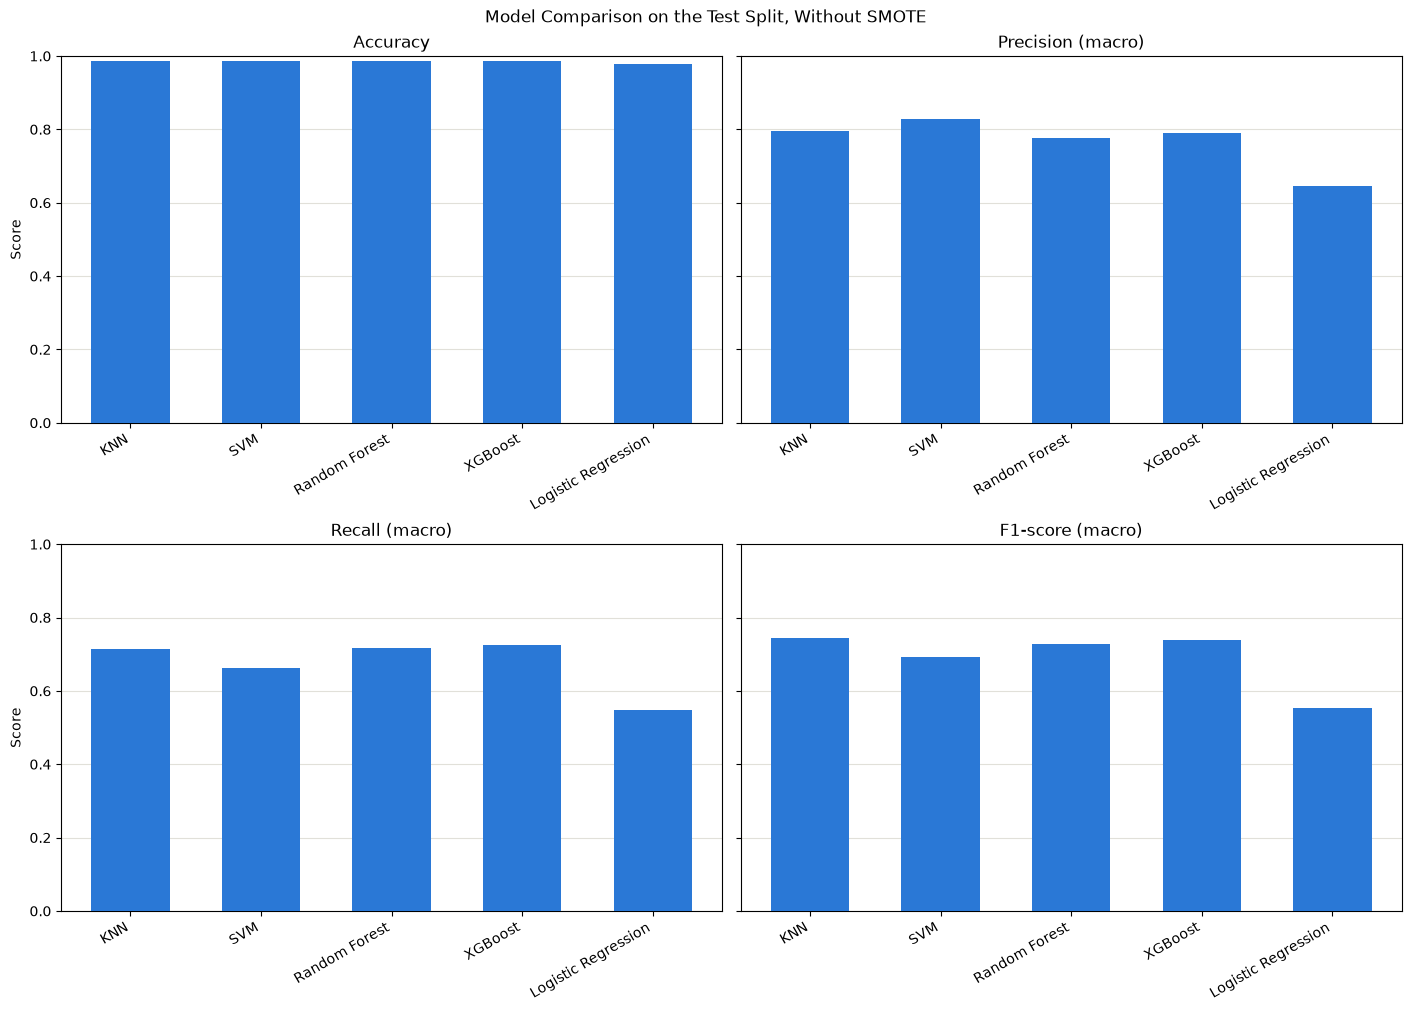

In [209]:
plot_model_comparison(
    clean_metrics,
    save_path=os.path.join(PATH_FOLDER_SETTING_EVALUATION, MODEL_COMPARISON_PLOT_FILE_NAME),
)

## Scores Against Noise Intensity

In [210]:
def plot_metric_against_intensity(
    metrics: pd.DataFrame,
    metric: str,
    population: str = "all",
    figsize: tuple[int, int] = (18, 5),
    save_path: str | None = None,
) -> None:
    noise_types = list(NOISE_MAGNITUDES)
    intensity_ticks = [0]
    for intensity in NOISE_INTENSITIES:
        intensity_ticks.append(round(intensity * 100))

    is_clean = (metrics[SCENARIO_COLUMN] == CLEAN_SCENARIO) & (metrics[POPULATION_COLUMN] == "all")
    is_population = metrics[POPULATION_COLUMN] == population
    fig, axes = plt.subplots(
        1,
        len(noise_types),
        figsize=figsize,
        sharex=True,
        sharey=True,
        squeeze=False,
        layout="constrained",
    )
    legend_handles = {}
    for column_index, noise_type in enumerate(noise_types):
        ax = axes[0, column_index]
        is_noise_type = is_population & (metrics[NOISE_TYPE_COLUMN] == noise_type)
        for model_index, (model_name, model_label) in enumerate(EVALUATED_MODELS.items()):
            is_model = metrics[MODEL_COLUMN] == model_name
            rows = metrics[is_model & (is_noise_type | is_clean)].sort_values(INTENSITY_COLUMN)
            if len(rows) < 2:
                continue
            (line,) = ax.plot(
                rows[INTENSITY_COLUMN] * 100,
                rows[metric],
                color=SERIES_COLORS[model_index],
                marker=SERIES_MARKERS[model_index],
                markersize=8,
                markeredgecolor=EMPTY_CELL_COLOR,
                markeredgewidth=1.5,
                linewidth=2,
                zorder=3,
            )
            legend_handles.setdefault(model_label, line)
        ax.set_title(noise_type.capitalize())
        ax.set_xticks(intensity_ticks)
        ax.grid(color=GRID_COLOR, linewidth=0.8, zorder=0)

    metric_label = METRIC_LABELS.get(metric, metric)
    for ax in axes[-1, :]:
        ax.set_xlabel("Noisy rows (%)")
    for ax in axes[:, 0]:
        ax.set_ylabel(metric_label)
    handles = []
    labels = []
    for model_label in EVALUATED_MODELS.values():
        if model_label in legend_handles:
            handles.append(legend_handles[model_label])
            labels.append(model_label)
    if handles:
        fig.legend(handles, labels, loc="outside lower center", ncol=len(labels))
    fig.suptitle(f"{metric_label} Under Feature Noise, {POPULATIONS[population]}, {SMOTE_LABEL} (0% is the clean test split)")

    if save_path is not None:
        fig.savefig(save_path, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()

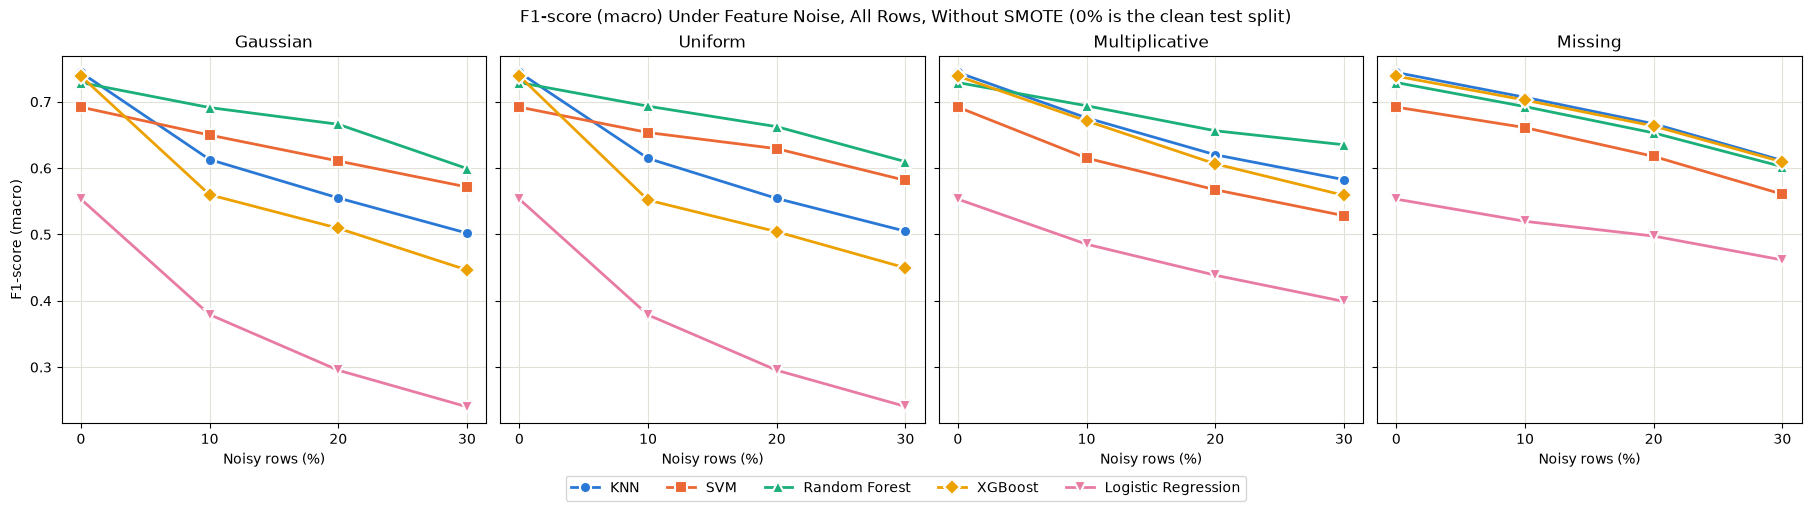

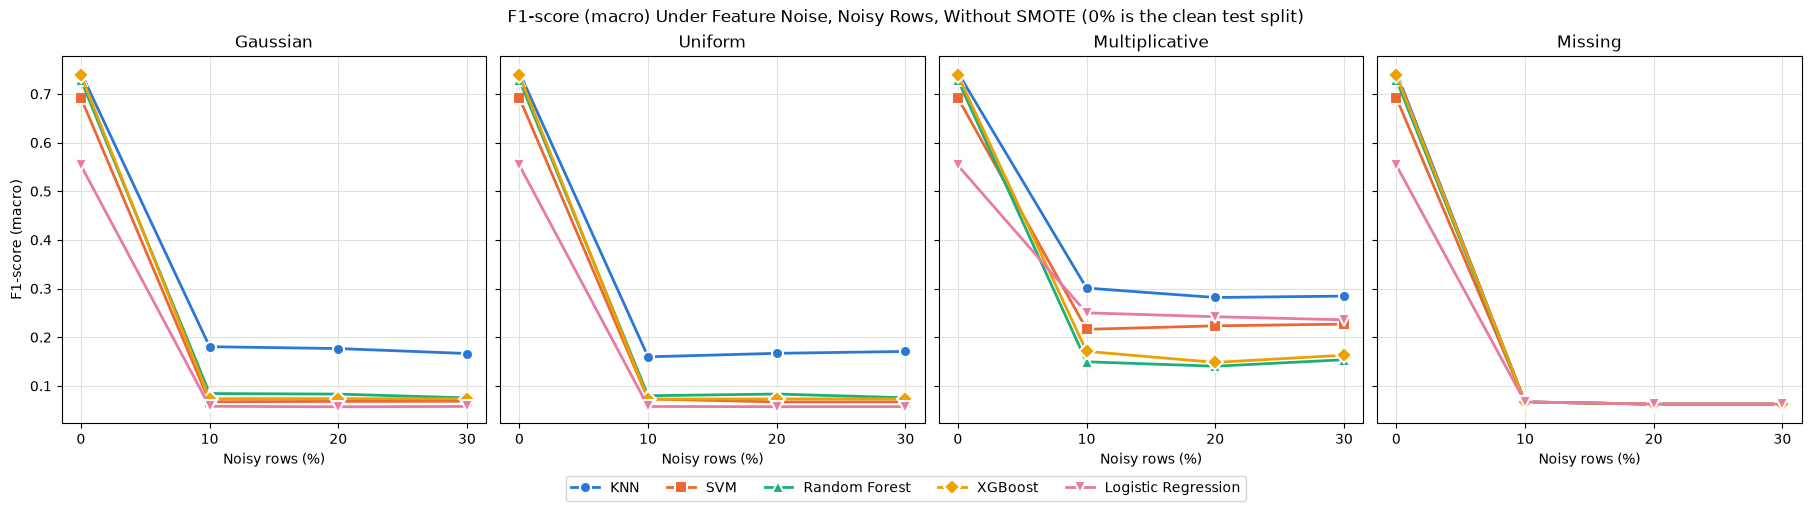

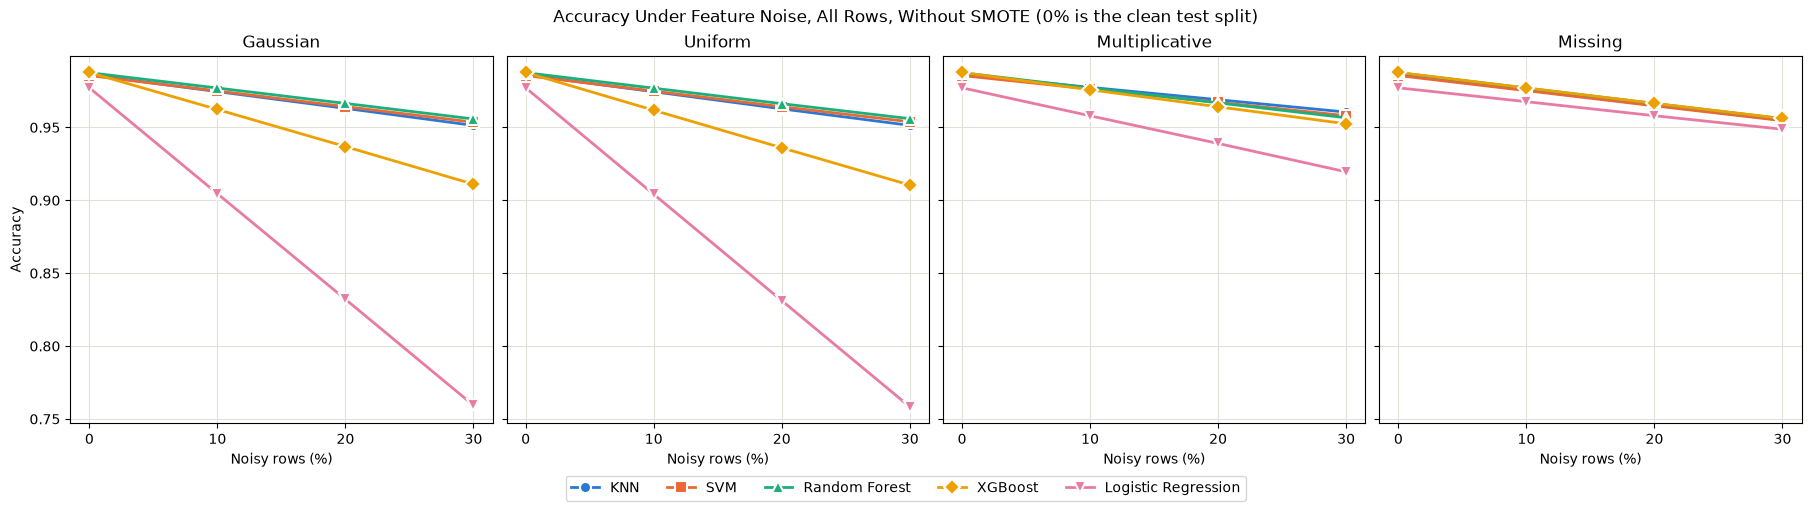

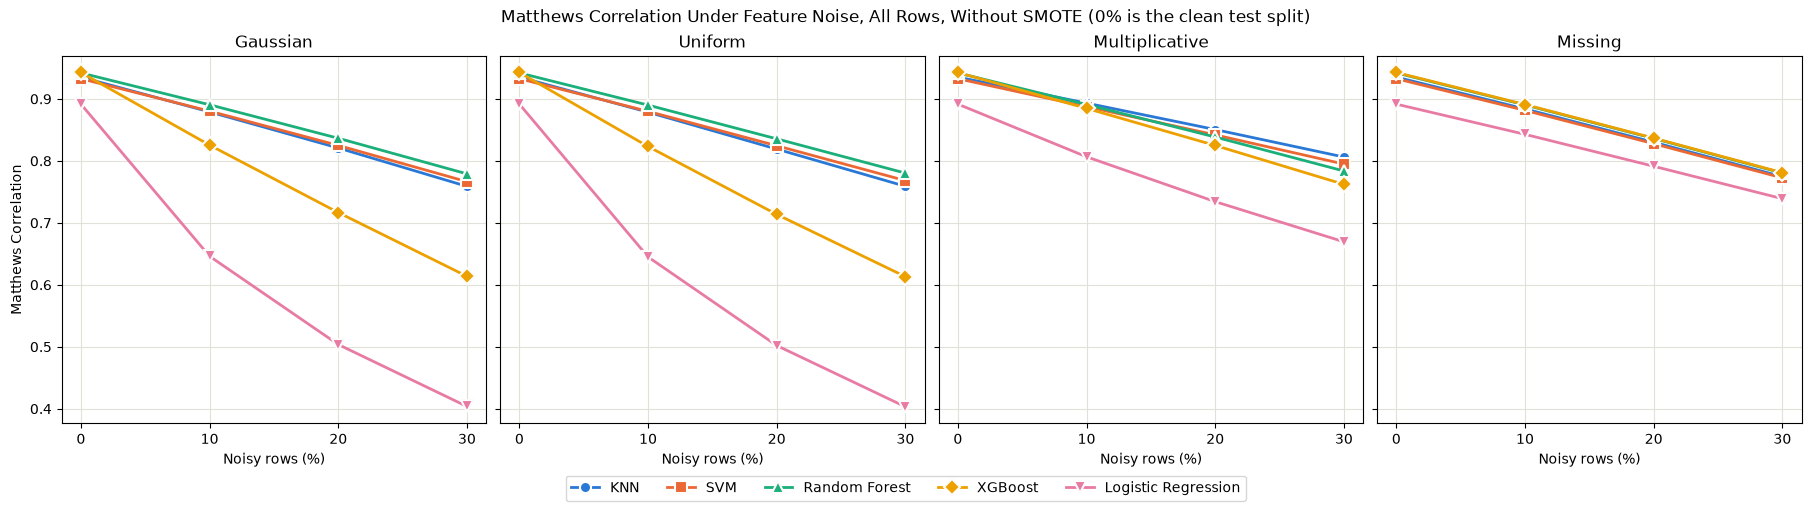

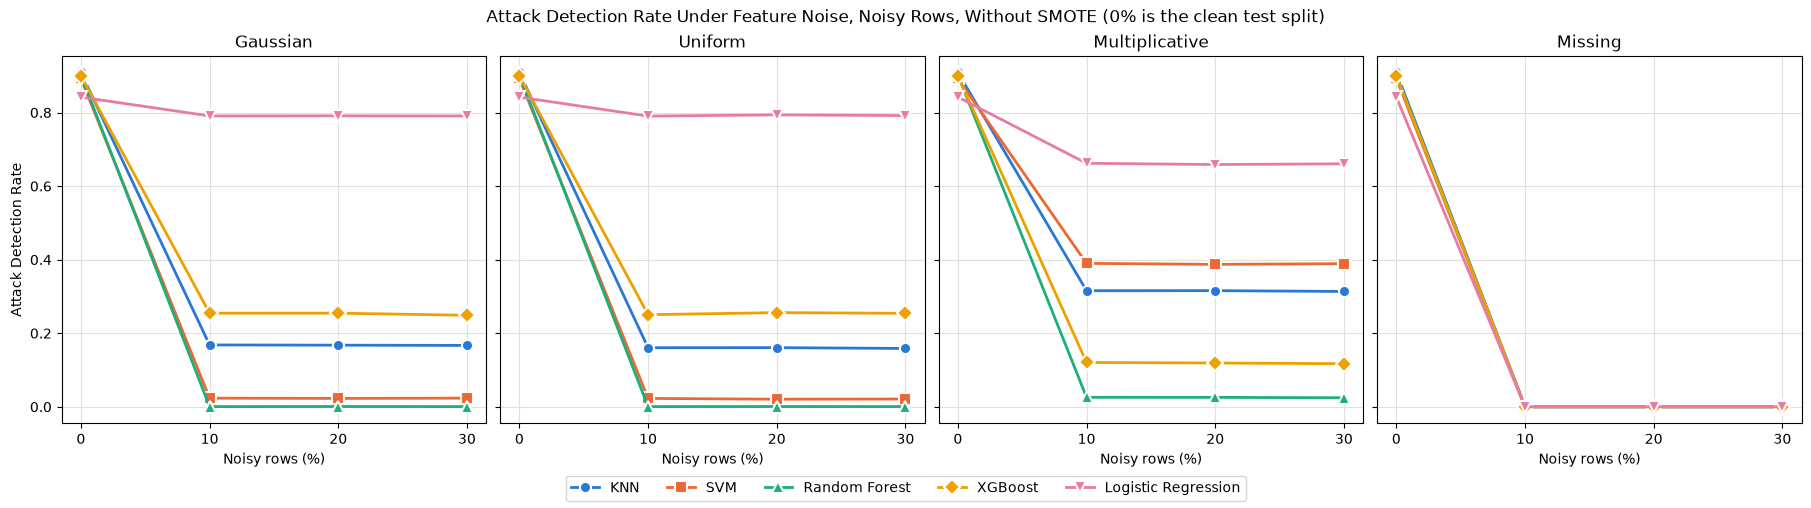

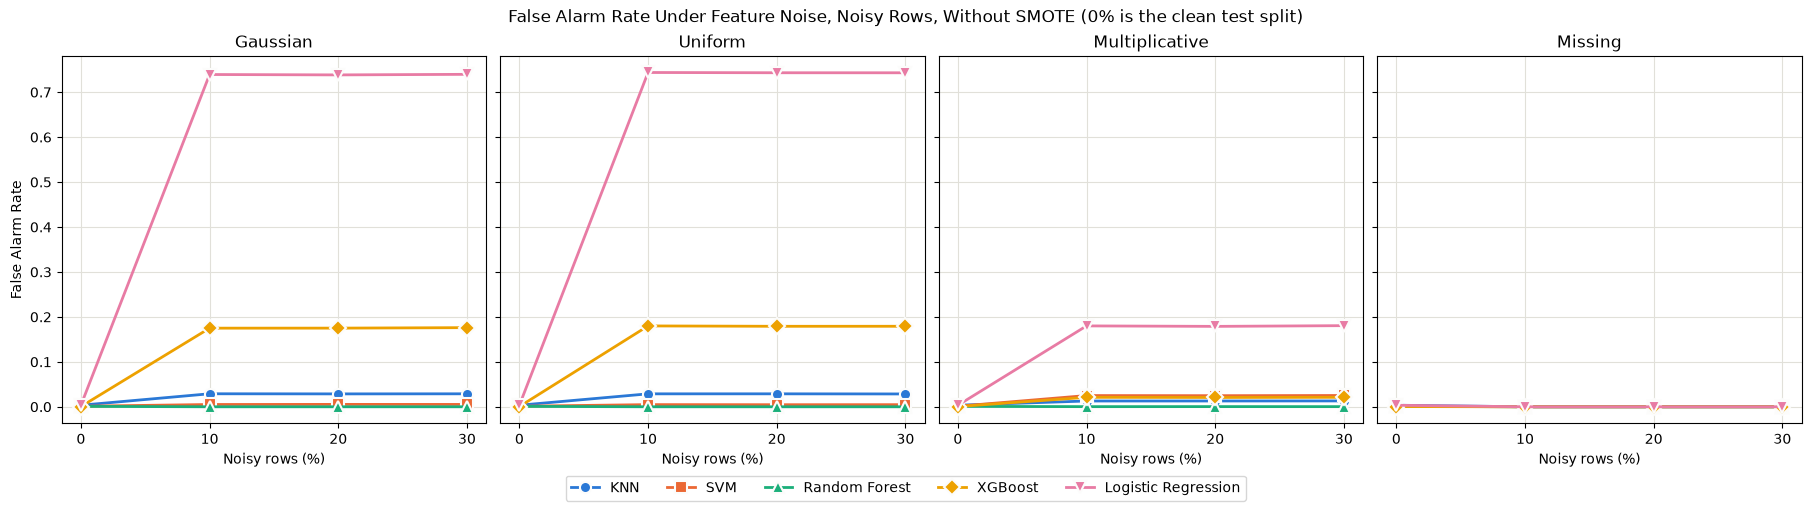

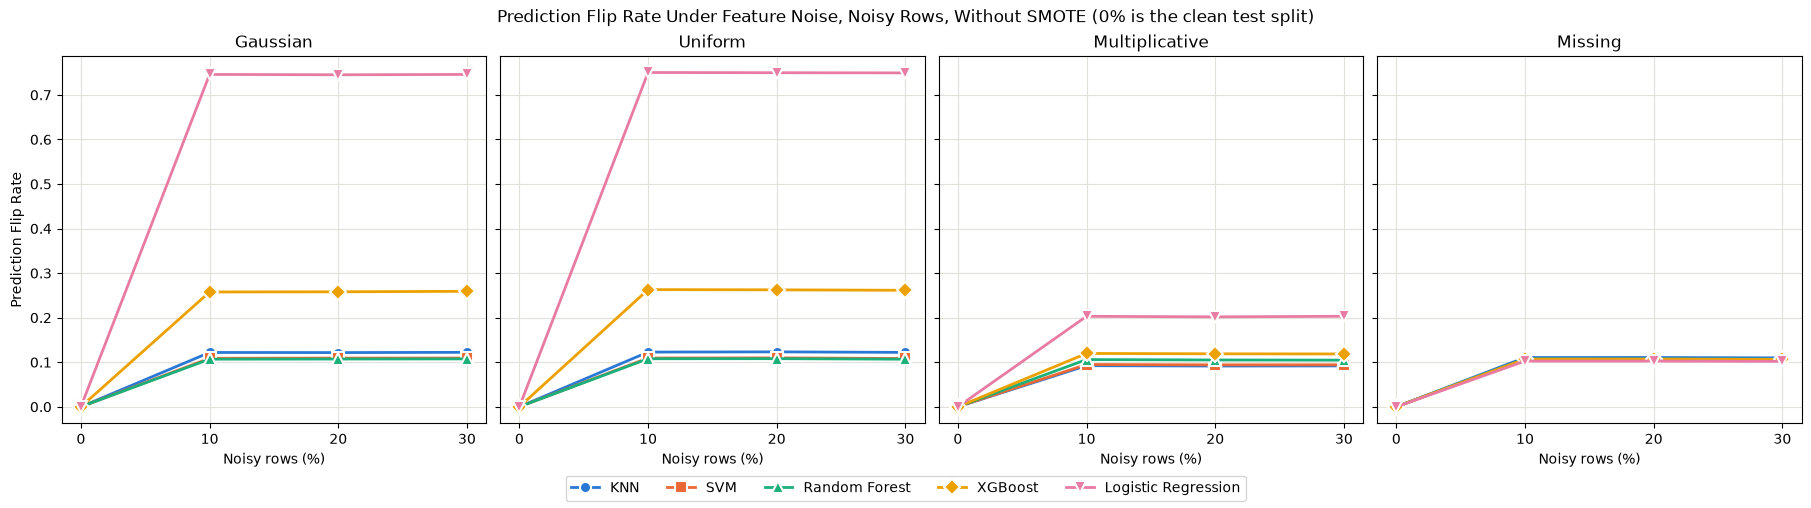

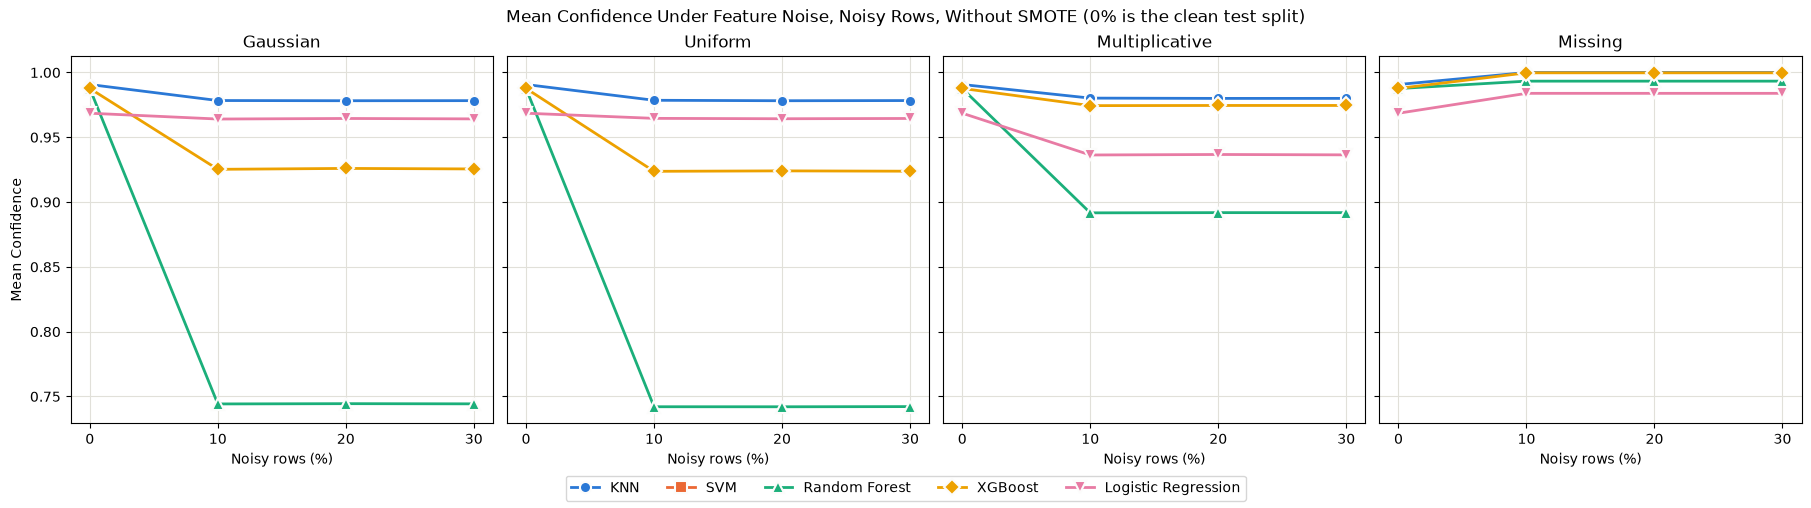

In [211]:
for metric, population in INTENSITY_PLOTS:
    plot_metric_against_intensity(
        metrics,
        metric,
        population,
        save_path=os.path.join(PATH_FOLDER_SETTING_EVALUATION, f"{metric}-{population}-against-intensity.png"),
    )

## Retention

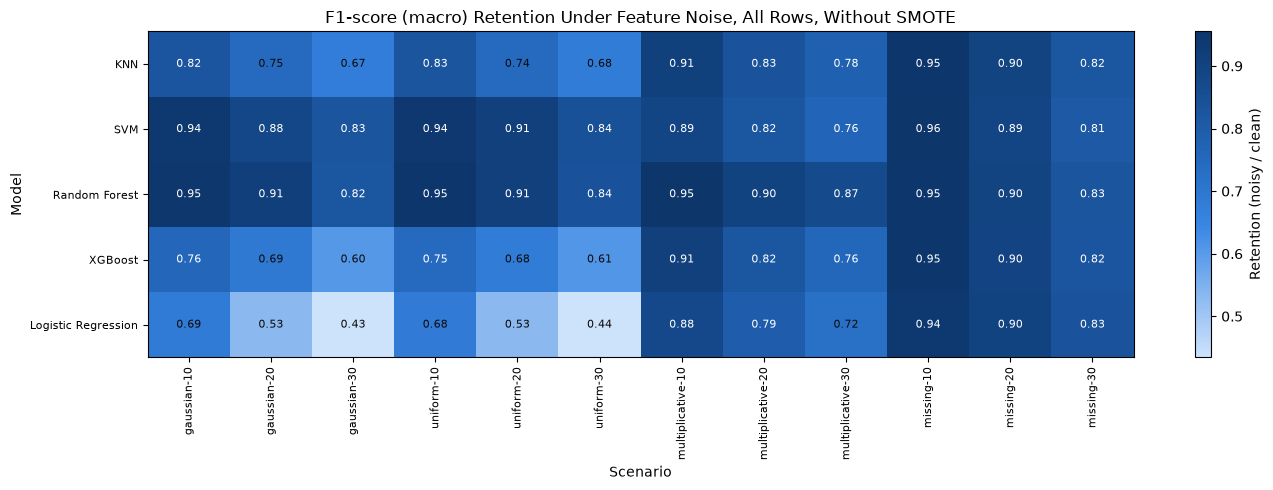

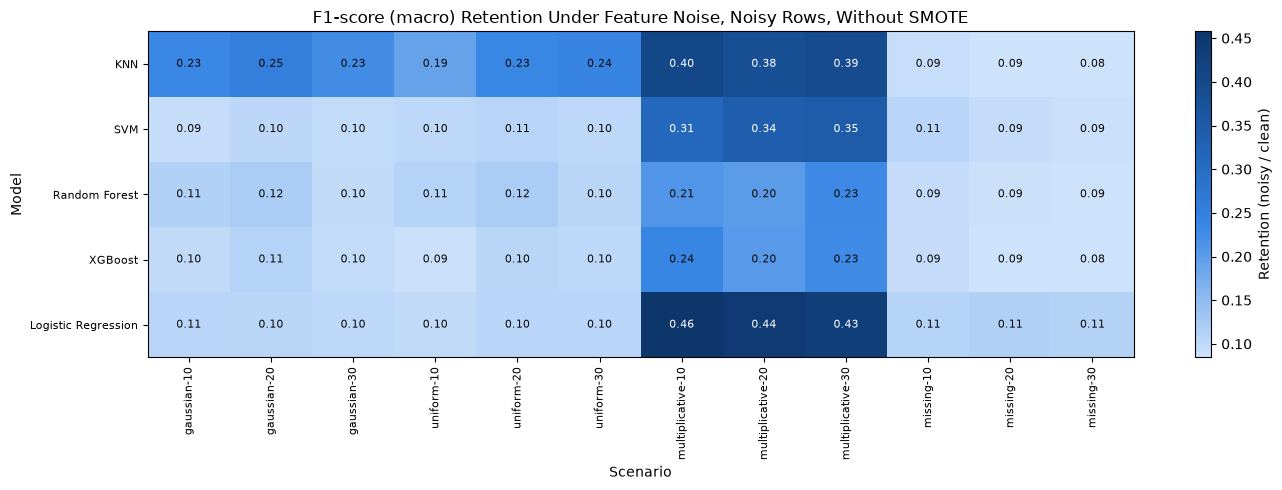

In [212]:
for population in ["all", "noisy"]:
    plot_scenario_heatmap(
        degradation[degradation[METRIC_COLUMN] == ROBUSTNESS_METRIC],
        RETENTION_COLUMN,
        population,
        f"{METRIC_LABELS[ROBUSTNESS_METRIC]} Retention Under Feature Noise, {POPULATIONS[population]}",
        "Retention (noisy / clean)",
        os.path.join(PATH_FOLDER_SETTING_EVALUATION, f"{ROBUSTNESS_METRIC}-{population}-retention.png"),
    )

## Robustness Ranking

In [213]:
def rank_robustness(degradation: pd.DataFrame) -> pd.DataFrame:
    is_noise_scenario = degradation[SCENARIO_COLUMN] != CLEAN_SCENARIO
    scored = degradation[is_noise_scenario].dropna(subset=[RETENTION_COLUMN])
    group_columns = [METRIC_COLUMN, POPULATION_COLUMN, SMOTE_SETTING_COLUMN, MODEL_COLUMN]
    records = []
    for group, rows in scored.groupby(group_columns, sort=False):
        worst = rows.loc[rows[RETENTION_COLUMN].idxmin()]
        record = dict(zip(group_columns, group))
        record.update({
            "scenarios": len(rows),
            "mean_clean_value": rows[CLEAN_VALUE_COLUMN].mean(),
            "mean_value": rows[VALUE_COLUMN].mean(),
            "mean_retention": rows[RETENTION_COLUMN].mean(),
            "worst_retention": worst[RETENTION_COLUMN],
            "worst_scenario": worst[SCENARIO_COLUMN],
            "mean_drop": rows[DROP_COLUMN].mean(),
            "max_drop": rows[DROP_COLUMN].max(),
        })
        for noise_type, noise_rows in rows.groupby(NOISE_TYPE_COLUMN, sort=False):
            record[f"{noise_type}_retention"] = noise_rows[RETENTION_COLUMN].mean()
        records.append(record)

    ranking = pd.DataFrame(records)
    mean_retention = ranking.groupby([METRIC_COLUMN, POPULATION_COLUMN])["mean_retention"]
    ranking.insert(0, "rank", mean_retention.rank(ascending=False, method="min").astype(int))
    return ranking.sort_values([METRIC_COLUMN, POPULATION_COLUMN, "rank"], ignore_index=True)

,rank,metric,population,smote_setting,model,scenarios,mean_clean_value,mean_value,mean_retention,worst_retention,worst_scenario,mean_drop,max_drop,gaussian_retention,uniform_retention,multiplicative_retention,missing_retention
75,1,f1_macro,all,wout-smote,rf,12,0.7289,0.6546,0.8980,0.8223,gaussian-30,0.0743,0.1296,0.8948,0.8988,0.9079,0.8907
76,2,f1_macro,all,wout-smote,svm,12,0.6919,0.6038,0.8727,0.7636,multiplicative-30,0.0880,0.1636,0.8826,0.8981,0.8241,0.8861
77,3,f1_macro,all,wout-smote,knn,12,0.7441,0.6006,0.8071,0.6747,gaussian-30,0.1435,0.2420,0.7481,0.7498,0.8415,0.8892
78,4,f1_macro,all,wout-smote,xgb,12,0.7386,0.5694,0.7709,0.6044,gaussian-30,0.1692,0.2922,0.6840,0.6794,0.8288,0.8913
79,5,f1_macro,all,wout-smote,logreg,12,0.5532,0.3859,0.6976,0.4343,gaussian-30,0.1673,0.3129,0.5512,0.5512,0.7971,0.8911


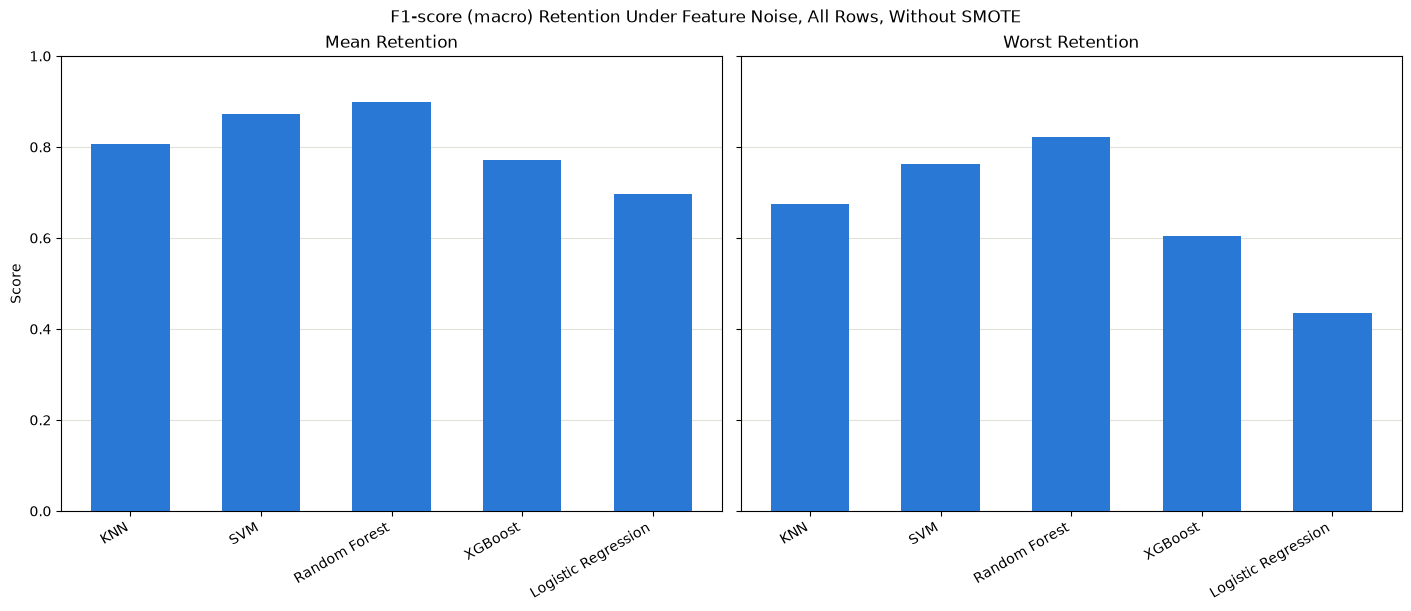

,rank,metric,population,smote_setting,model,scenarios,mean_clean_value,mean_value,mean_retention,worst_retention,worst_scenario,mean_drop,max_drop,gaussian_retention,uniform_retention,multiplicative_retention,missing_retention
85,1,f1_macro,noisy,wout-smote,knn,12,0.7407,0.1733,0.2346,0.0845,missing-30,0.5674,0.6809,0.2369,0.2215,0.3931,0.0870
86,2,f1_macro,noisy,wout-smote,logreg,12,0.5583,0.1054,0.1907,0.0988,uniform-10,0.4529,0.5497,0.1038,0.1029,0.4444,0.1116
87,3,f1_macro,noisy,wout-smote,svm,12,0.6772,0.1058,0.1573,0.0883,missing-30,0.5714,0.6607,0.0976,0.1030,0.3327,0.0957
88,4,f1_macro,noisy,wout-smote,rf,12,0.7142,0.0930,0.1313,0.0853,missing-30,0.6212,0.6944,0.1110,0.1121,0.2135,0.0887
89,5,f1_macro,noisy,wout-smote,xgb,12,0.7324,0.0928,0.1275,0.0846,missing-30,0.6396,0.7564,0.1018,0.0975,0.2229,0.0878


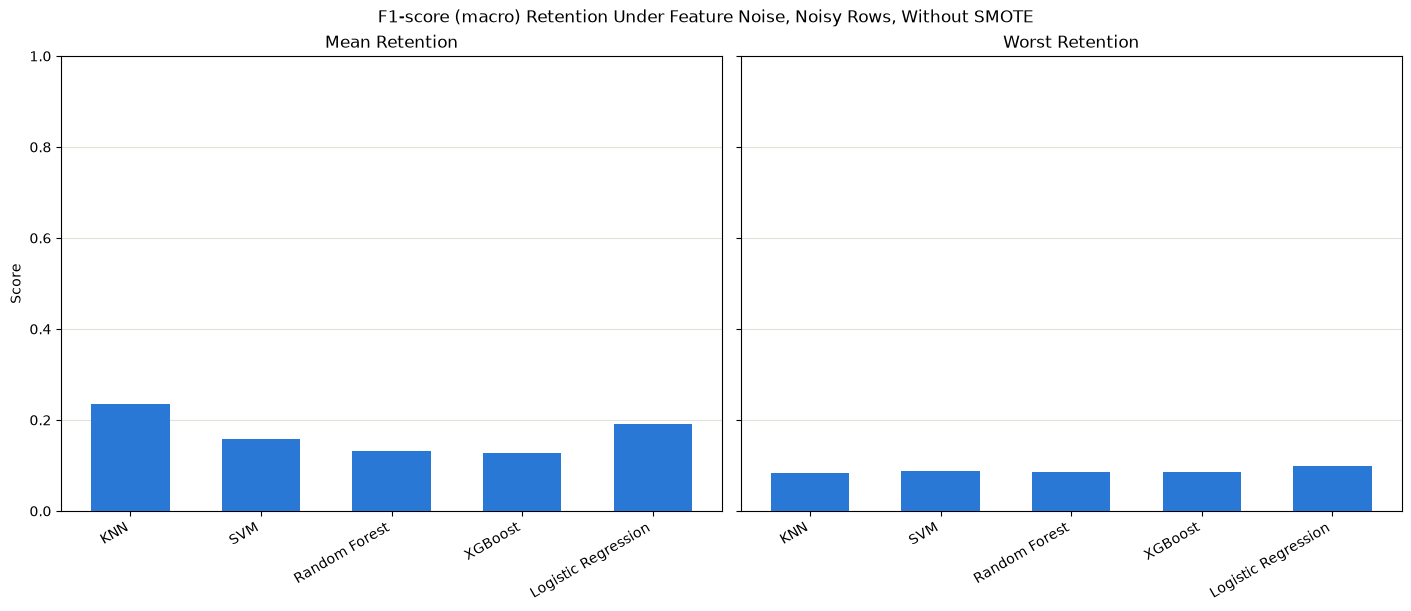

In [214]:
ranking = rank_robustness(degradation)
ranking.to_csv(os.path.join(PATH_FOLDER_SETTING_EVALUATION, ROBUSTNESS_RANKING_FILE_NAME), index=False)
for population in ["all", "noisy"]:
    is_shown = (ranking[METRIC_COLUMN] == ROBUSTNESS_METRIC) & (ranking[POPULATION_COLUMN] == population)
    display(ranking[is_shown].round(4))
    plot_model_comparison(
        ranking[is_shown],
        metrics={"mean_retention": "Mean Retention", "worst_retention": "Worst Retention"},
        figsize=(14, 6),
        title=f"{METRIC_LABELS[ROBUSTNESS_METRIC]} Retention Under Feature Noise, {POPULATIONS[population]}",
        save_path=os.path.join(PATH_FOLDER_SETTING_EVALUATION, f"{ROBUSTNESS_METRIC}-{population}-ranking.png"),
    )

## Intact and Noisy Rows

In [215]:
is_intact = (metrics[POPULATION_COLUMN] == "intact") & (metrics[SCENARIO_COLUMN] != CLEAN_SCENARIO)
intact_flip_rate = metrics[is_intact].groupby([SMOTE_SETTING_COLUMN, MODEL_COLUMN], sort=False)["flip_rate"].max()
end_status(f"At most {intact_flip_rate.max():.4%} of the intact rows changed prediction from the clean test split")
display(intact_flip_rate.rename("max_intact_flip_rate").to_frame())
display(
    metrics[metrics[POPULATION_COLUMN] != "all"].pivot_table(
        index=[SMOTE_SETTING_COLUMN, MODEL_COLUMN],
        columns=[NOISE_TYPE_COLUMN, POPULATION_COLUMN],
        values=ROBUSTNESS_METRIC,
    ).round(4)
)

At most 0.0000% of the intact rows changed prediction from the clean test split 


max_intact_flip_rate
smote_setting model                       
wout-smote    knn                      0.0
              svm                      0.0
              rf                       0.0
              xgb                      0.0
              logreg                   0.0

noise_type             clean gaussian         missing        multiplicative  \
population            intact   intact   noisy  intact  noisy         intact   
smote_setting model                                                           
wout-smote    knn     0.7441   0.7464  0.1746  0.7423  0.064         0.7399   
              logreg  0.5532   0.5516  0.0576  0.5493  0.064         0.5547   
              rf      0.7289   0.7267  0.0809  0.7263  0.064         0.7352   
              svm     0.6919   0.6878  0.0680  0.6900  0.064         0.6943   
              xgb     0.7386   0.7433  0.0736  0.7368  0.064         0.7379   

noise_type                   uniform          
population             noisy  intact   noisy  
smote_setting model                           
wout-smote    knn     0.2890  0.7469  0.1657  
              logreg  0.2427  0.5550  0.0574  
              rf      0.1478  0.7316  0.0795  
              svm     0.2222  0.6985  0.0691  
              xgb     0.1607  0.7387  0.0731

In [216]:
def check_mixture_identity(metrics: pd.DataFrame) -> pd.DataFrame:
    noise_metrics = metrics[metrics[SCENARIO_COLUMN] != CLEAN_SCENARIO]
    table = noise_metrics.pivot_table(
        index=[SMOTE_SETTING_COLUMN, MODEL_COLUMN, SCENARIO_COLUMN, INTENSITY_COLUMN],
        columns=POPULATION_COLUMN,
        values=["accuracy", ROW_COUNT_COLUMN],
    )
    noisy_fraction = table[(ROW_COUNT_COLUMN, "noisy")] / table[(ROW_COUNT_COLUMN, "all")]
    mixture_check = pd.DataFrame({
        "noisy_fraction": noisy_fraction,
        "accuracy": table[("accuracy", "all")],
        "intact_accuracy": table[("accuracy", "intact")],
        "noisy_accuracy": table[("accuracy", "noisy")],
    })
    mixture_check["mixed_accuracy"] = (
        (1 - noisy_fraction) * mixture_check["intact_accuracy"] + noisy_fraction * mixture_check["noisy_accuracy"]
    )
    mixture_check["residual"] = mixture_check["accuracy"] - mixture_check["mixed_accuracy"]
    return mixture_check.reset_index()

In [217]:
mixture_check = check_mixture_identity(metrics)
mixture_check.to_csv(os.path.join(PATH_FOLDER_SETTING_EVALUATION, MIXTURE_CHECK_FILE_NAME), index=False)
largest_residual = mixture_check["residual"].abs().max()
end_status(f"The accuracy differs from the mixture of the intact and noisy rows by at most {largest_residual:.2e}")
display(mixture_check.round(6))

The accuracy differs from the mixture of the intact and noisy rows by at most 1.11e-16


,smote_setting,model,scenario,intensity,noisy_fraction,accuracy,intact_accuracy,noisy_accuracy,mixed_accuracy,residual
0,wout-smote,knn,gaussian-10,0.1,0.1,0.974565,0.986095,0.870793,0.974565,0.0
1,wout-smote,knn,gaussian-20,0.2,0.2,0.963076,0.986064,0.871123,0.963076,0.0
2,wout-smote,knn,gaussian-30,0.3,0.3,0.951375,0.986077,0.870401,0.951375,-0.0
3,wout-smote,knn,missing-10,0.1,0.1,0.975671,0.986121,0.881622,0.975671,0.0
4,wout-smote,knn,missing-20,0.2,0.2,0.965246,0.986140,0.881668,0.965246,0.0
5,wout-smote,knn,missing-30,0.3,0.3,0.954995,0.986019,0.882608,0.954995,0.0
6,wout-smote,knn,multiplicative-10,0.1,0.1,0.977482,0.986087,0.900043,0.977482,0.0
7,wout-smote,knn,multiplicative-20,0.2,0.2,0.969004,0.986096,0.900637,0.969004,0.0
8,wout-smote,knn,multiplicative-30,0.3,0.3,0.960508,0.986096,0.900802,0.960508,-0.0
9,wout-smote,knn,uniform-10,0.1,0.1,0.974479,0.986082,0.870050,0.974479,0.0


## Per-Class Metrics

In [218]:
def score_classes(outcomes: pd.DataFrame, class_names: list[str], benign: int) -> pd.DataFrame:
    labels = outcomes[LABEL_COLUMN].to_numpy()
    predictions = outcomes[PREDICTION_COLUMN].to_numpy()
    clean_predictions = outcomes[CLEAN_PREDICTION_COLUMN].to_numpy()
    rows = outcomes[ROW_COUNT_COLUMN].to_numpy()
    confidence_sums = outcomes[CONFIDENCE_SUM_COLUMN].to_numpy()
    class_codes = np.arange(len(class_names))
    precision, recall, f1, support = precision_recall_fscore_support(
        labels, predictions, labels=class_codes, sample_weight=rows, zero_division=np.nan
    )
    clean_precision, clean_recall, clean_f1, _ = precision_recall_fscore_support(
        labels, clean_predictions, labels=class_codes, sample_weight=rows, zero_division=np.nan
    )

    records = []
    for class_code in class_codes:
        is_class = labels == class_code
        records.append({
            CLASS_COLUMN: class_names[class_code],
            "support": int(support[class_code]),
            "predicted": int(rows[predictions == class_code].sum()),
            "precision": precision[class_code],
            "recall": recall[class_code],
            "f1": f1[class_code],
            "clean_precision": clean_precision[class_code],
            "clean_recall": clean_recall[class_code],
            "clean_f1": clean_f1[class_code],
            "flip_rate": mean_per_row(rows * (predictions != clean_predictions), rows, is_class),
            "benign_rate": mean_per_row(rows * (predictions == benign), rows, is_class),
            "clean_benign_rate": mean_per_row(rows * (clean_predictions == benign), rows, is_class),
            "mean_confidence": mean_per_row(confidence_sums, rows, is_class),
        })
    return pd.DataFrame(records)

In [219]:
def measure_every_class(outcomes: pd.DataFrame, class_names: list[str]) -> pd.DataFrame:
    benign = class_names.index(BENIGN_CLASS)
    groups = outcomes.groupby(COMBINATION_COLUMNS, sort=False)
    tables = []
    started = time.time()
    for group_index, (combination, combination_outcomes) in enumerate(groups, start=1):
        smote_setting, model_name, scenario, _, _ = combination
        for population in POPULATIONS:
            population_outcomes = select_population(combination_outcomes, population)
            if population_outcomes.empty:
                continue
            table = score_classes(population_outcomes, class_names, benign)
            table.insert(0, POPULATION_COLUMN, population)
            tables.append(add_combination_columns(table, smote_setting, model_name, scenario))
        print_progress(group_index, groups.ngroups, "Scoring every class", started=started)

    class_metrics = pd.concat(tables, ignore_index=True)
    class_metrics["f1_drop"] = class_metrics["clean_f1"] - class_metrics["f1"]
    end_status(f"Scored {len(class_names)} classes on {len(tables)} populations")
    return class_metrics

In [220]:
class_metrics = measure_every_class(outcomes, class_names)
class_metrics.to_csv(os.path.join(PATH_FOLDER_SETTING_EVALUATION, CLASS_METRICS_FILE_NAME), index=False)
display(class_metrics.round(4))

Scored 15 classes on 190 populations                                            psed ~00:00:00 left


,smote_setting,model,scenario,noise_type,intensity,population,class,support,predicted,precision,recall,f1,clean_precision,clean_recall,clean_f1,flip_rate,benign_rate,clean_benign_rate,mean_confidence,f1_drop
0,wout-smote,knn,clean,clean,0.0,all,Benign,2019030,2036643,0.9879,0.9965,0.9922,0.9879,0.9965,0.9922,0.0000,0.9965,0.9965,0.9909,0.0000
1,wout-smote,knn,clean,clean,0.0,all,Bot,28907,28900,1.0000,0.9998,0.9999,1.0000,0.9998,0.9999,0.0000,0.0002,0.0002,0.9999,0.0000
2,wout-smote,knn,clean,clean,0.0,all,Brute Force -Web,111,73,0.8630,0.5676,0.6848,0.8630,0.5676,0.6848,0.0000,0.3514,0.3514,0.9129,0.0000
3,wout-smote,knn,clean,clean,0.0,all,Brute Force -XSS,46,40,0.8250,0.7174,0.7674,0.8250,0.7174,0.7674,0.0000,0.1522,0.1522,0.8406,0.0000
4,wout-smote,knn,clean,clean,0.0,all,DDOS attack-HOIC,39772,39771,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2845,wout-smote,logreg,missing-30,missing,0.3,noisy,DoS attacks-Slowloris,576,0,NaN,0.0000,0.0000,0.9879,0.7101,0.8263,0.7188,1.0000,0.2812,0.9839,0.8263
2846,wout-smote,logreg,missing-30,missing,0.3,noisy,FTP-BruteForce,4,0,NaN,0.0000,0.0000,NaN,0.0000,0.0000,0.0000,1.0000,1.0000,0.9839,0.0000
2847,wout-smote,logreg,missing-30,missing,0.3,noisy,Infilteration,8266,0,NaN,0.0000,0.0000,0.3545,0.0081,0.0158,0.0156,1.0000,0.9844,0.9839,0.0158
2848,wout-smote,logreg,missing-30,missing,0.3,noisy,SQL Injection,9,0,NaN,0.0000,0.0000,1.0000,0.1111,0.2000,0.1111,1.0000,0.8889,0.9839,0.2000


In [221]:
def plot_class_heatmap(
    class_metrics: pd.DataFrame,
    class_names: list[str],
    scenario: str,
    population: str,
    value_column: str,
    title: str,
    colorbar_label: str,
    colormap: mcolors.Colormap = SEQUENTIAL_COLORMAP,
    value_range: tuple[float | None, float | None] = (0, 1),
) -> None:
    is_shown = (class_metrics[SCENARIO_COLUMN] == scenario) & (class_metrics[POPULATION_COLUMN] == population)
    plot_heatmap(
        pivot_models(class_metrics[is_shown], CLASS_COLUMN, value_column, class_names),
        f"{title}, {SMOTE_LABEL}",
        colormap=colormap,
        value_range=value_range,
        annotate=True,
        annotation_format=".2f",
        xlabel="Model",
        ylabel="Class",
        colorbar_label=colorbar_label,
        figsize=(10, 9),
        save_path=os.path.join(PATH_FOLDER_SETTING_EVALUATION, f"class-{value_column}-{scenario}-{population}.png"),
    )

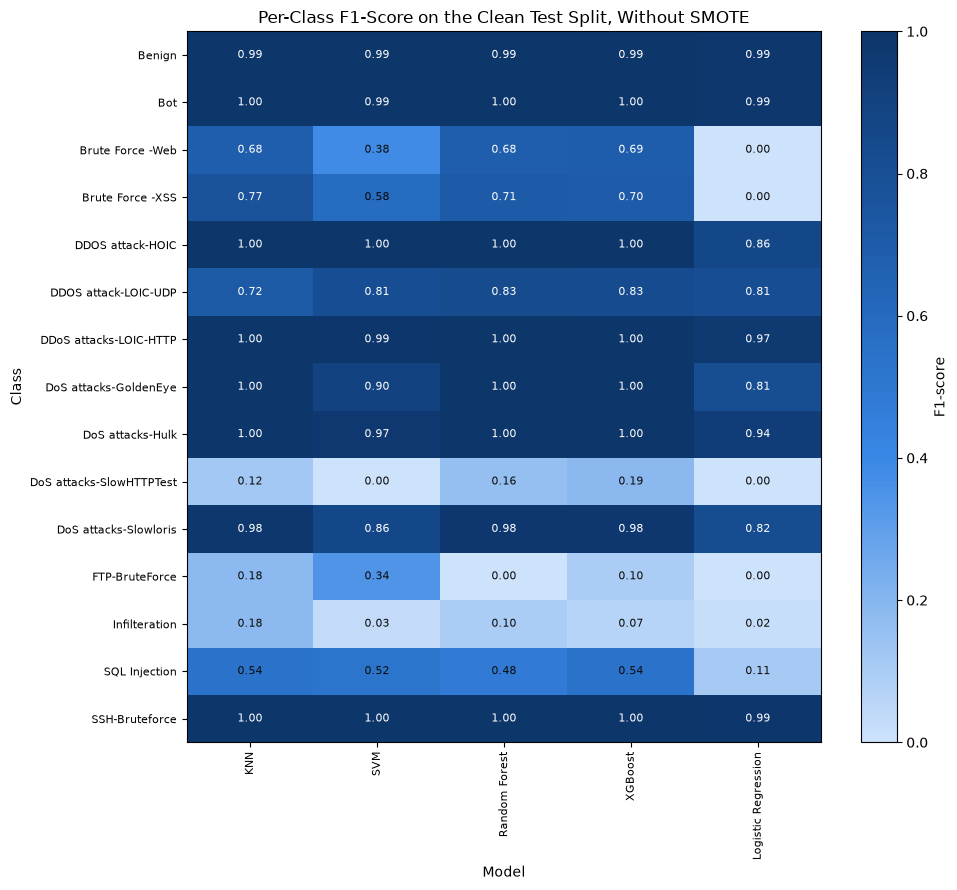

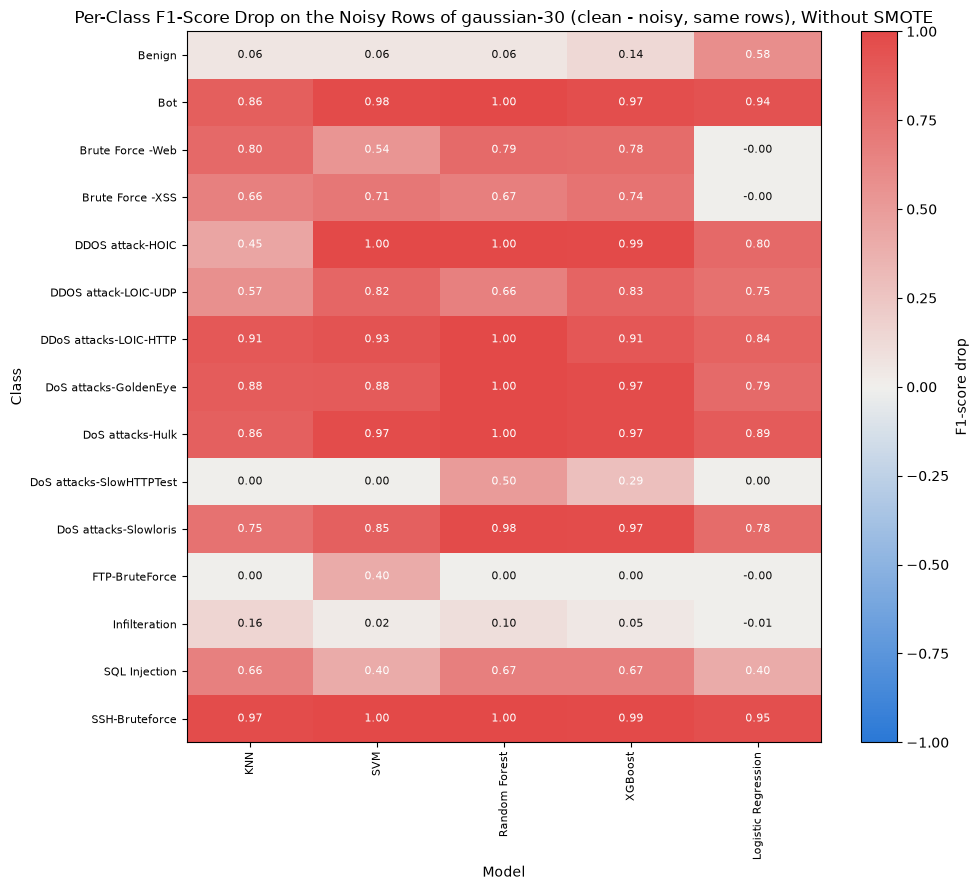

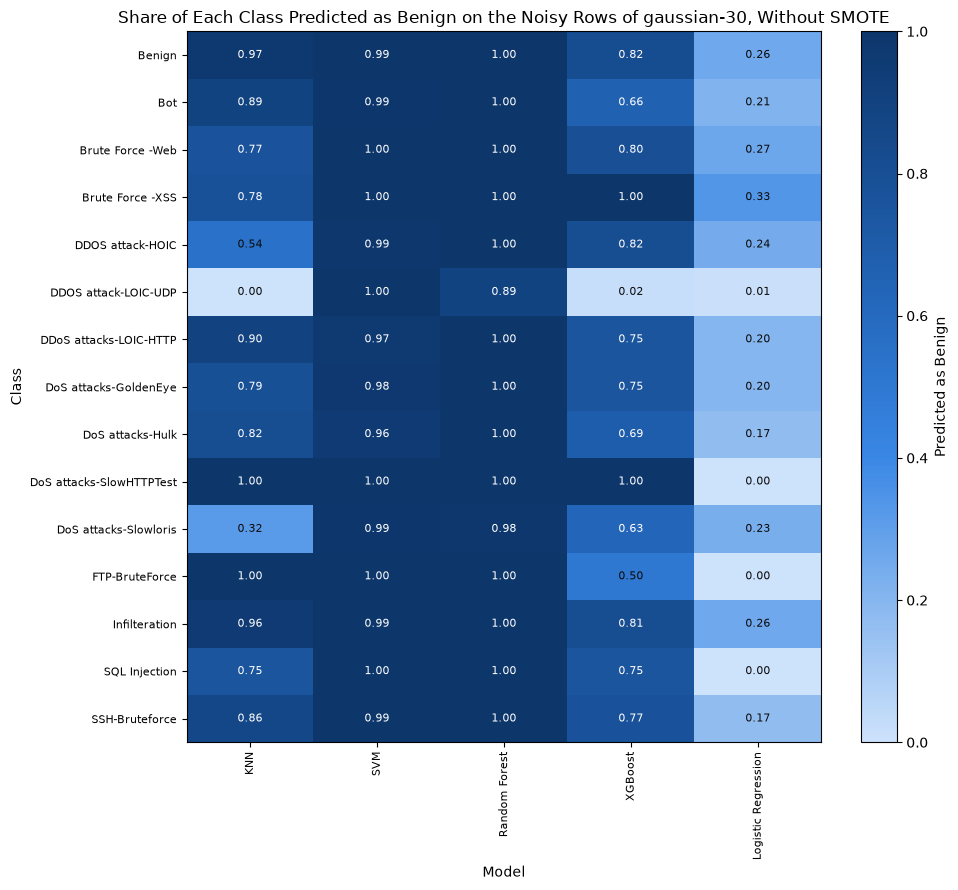

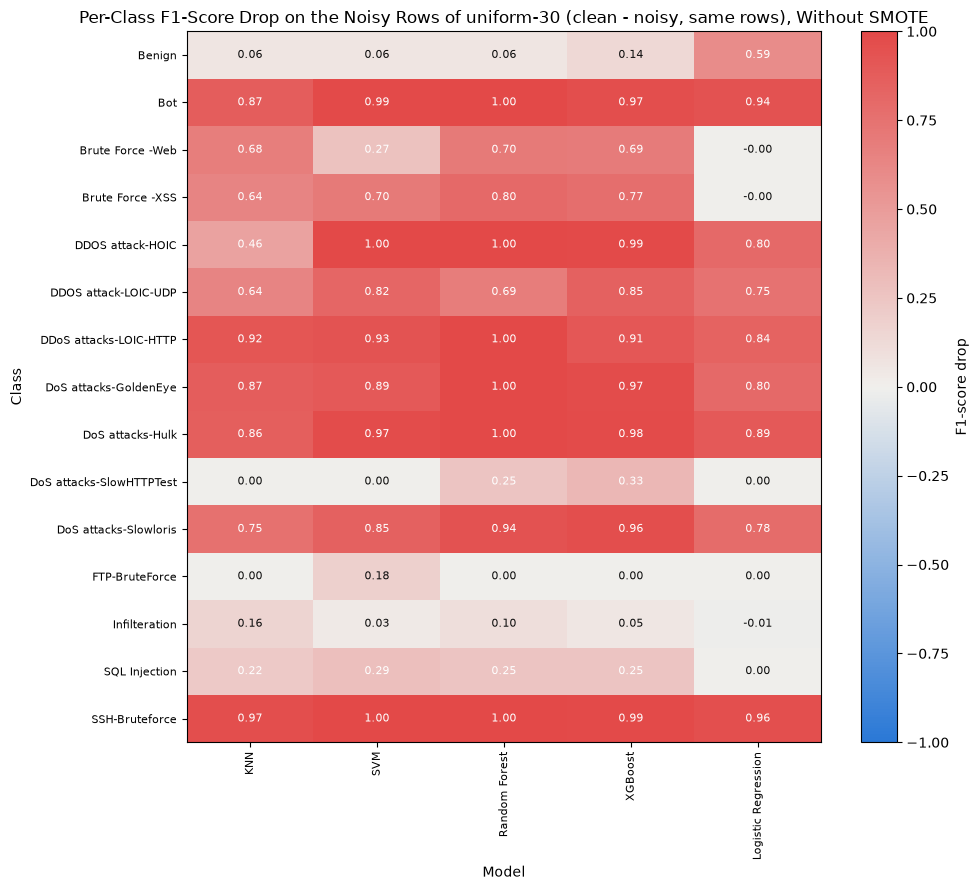

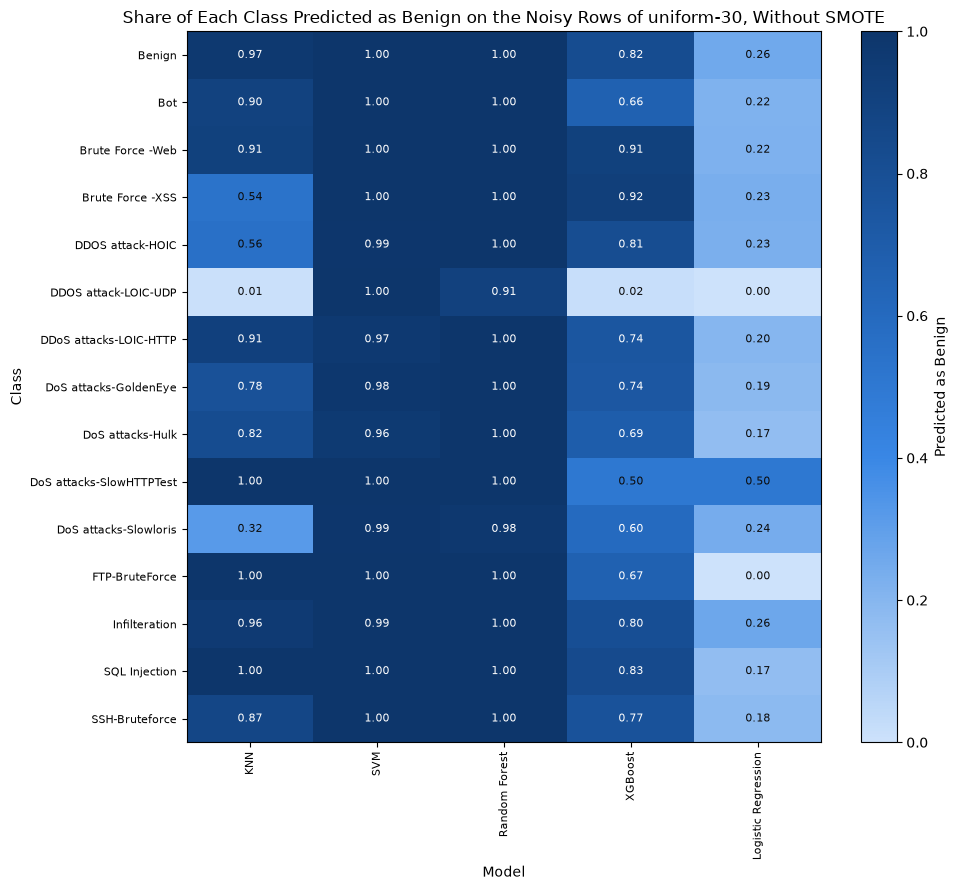

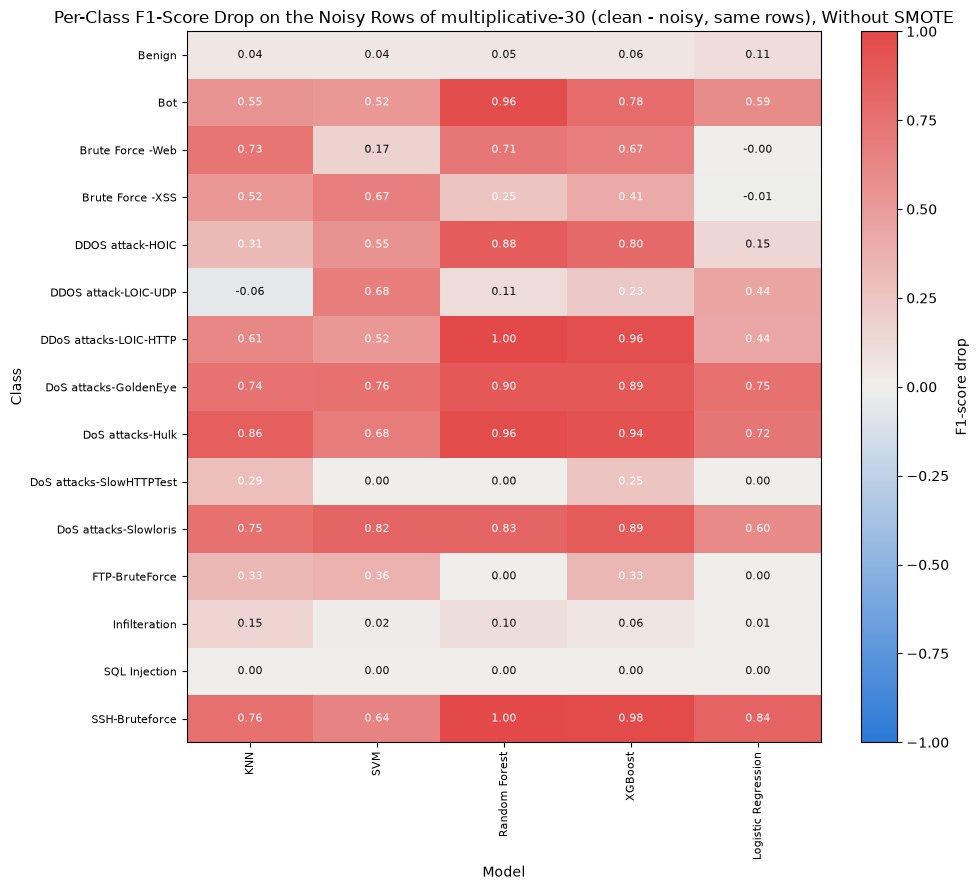

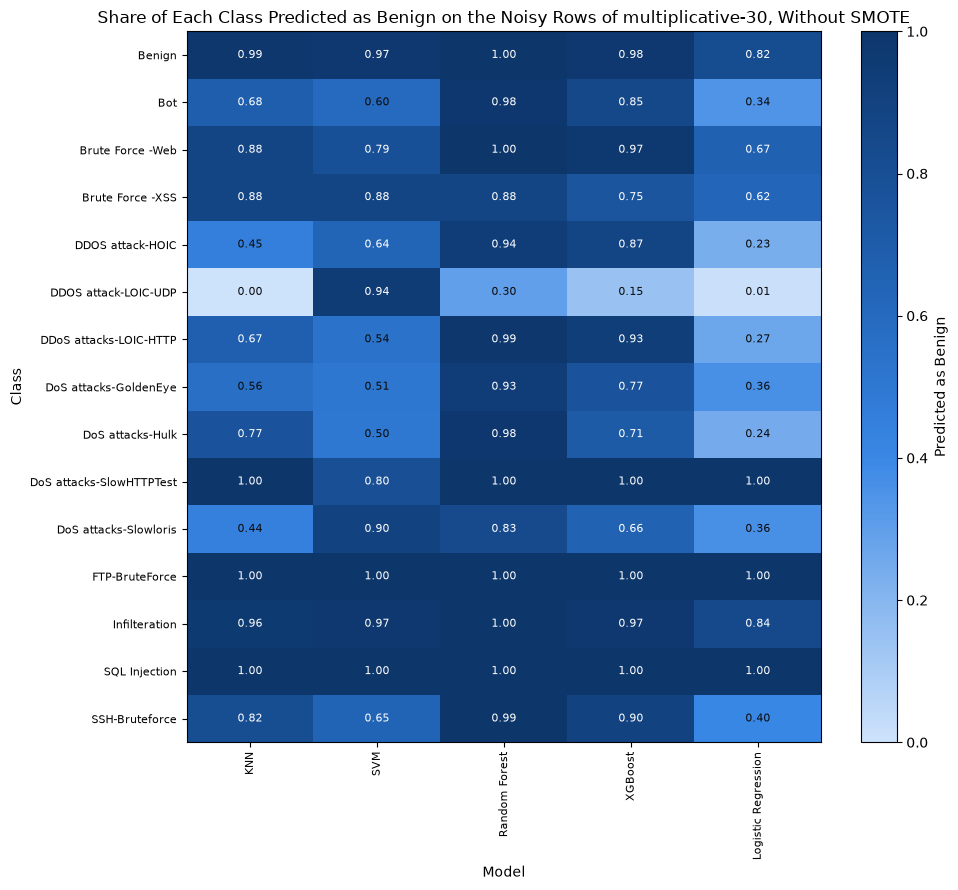

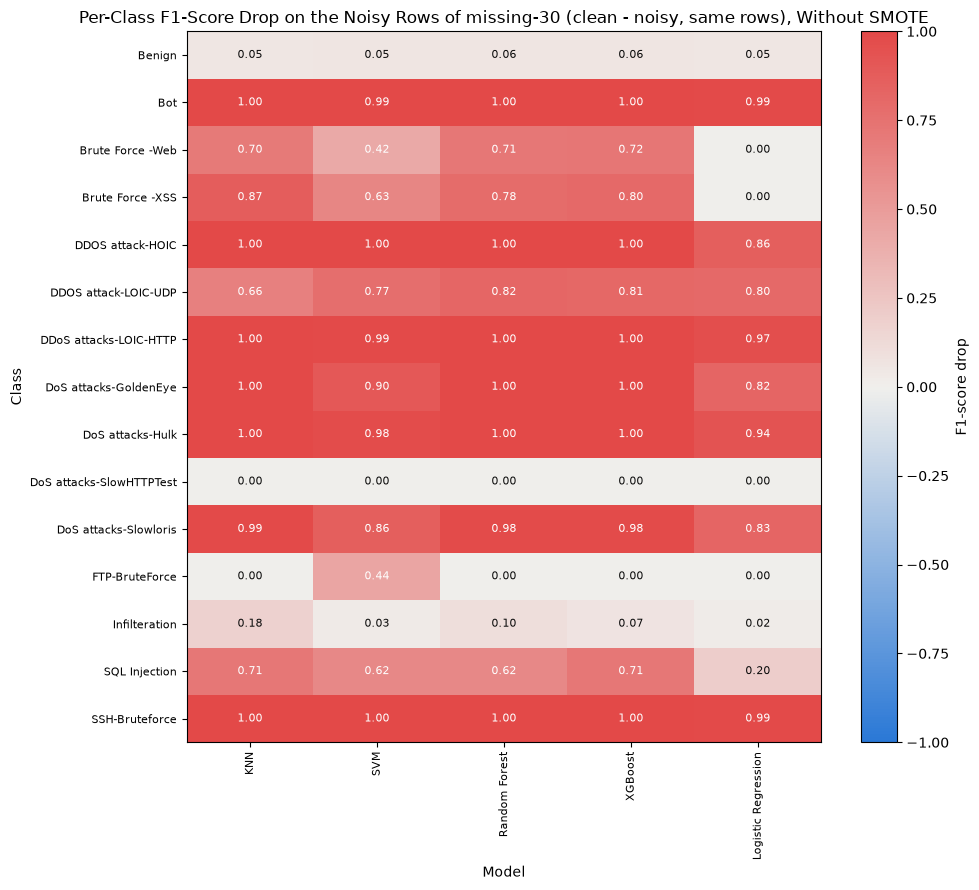

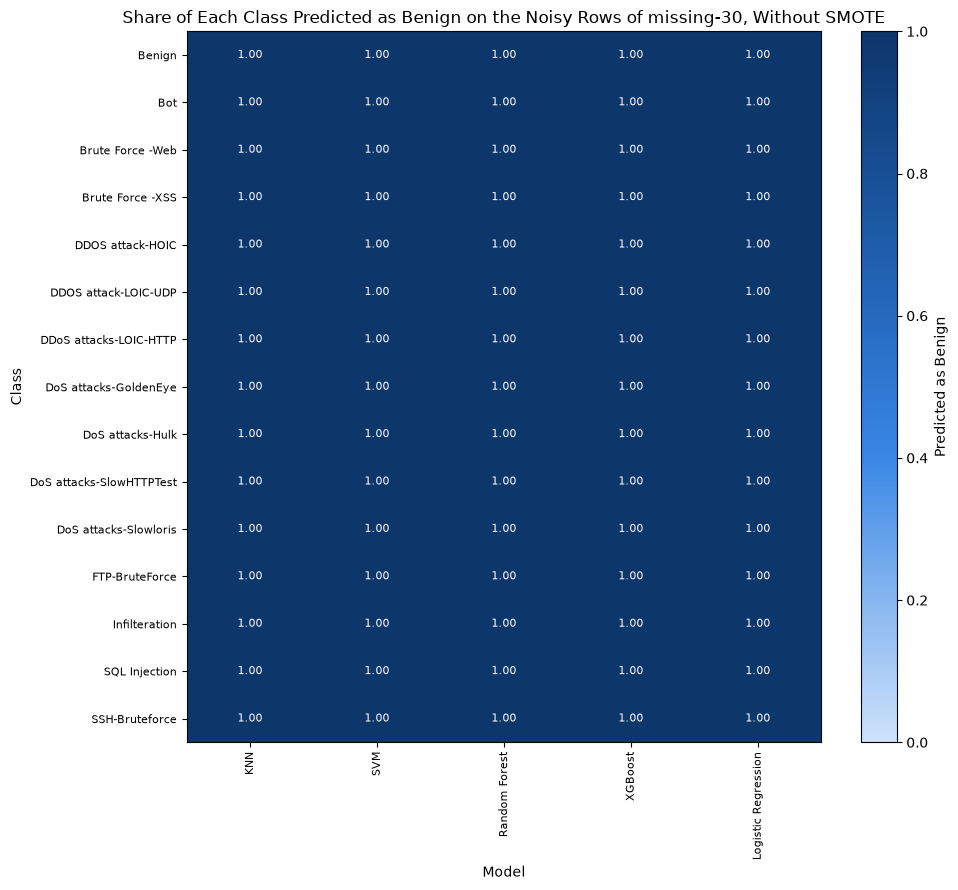

In [222]:
plot_class_heatmap(
    class_metrics,
    class_names,
    CLEAN_SCENARIO,
    "all",
    "f1",
    "Per-Class F1-Score on the Clean Test Split",
    "F1-score",
)
highest_intensity = max(NOISE_INTENSITIES)
for noise_type in NOISE_MAGNITUDES:
    scenario = get_noise_scenario_name(noise_type, highest_intensity)
    plot_class_heatmap(
        class_metrics,
        class_names,
        scenario,
        "noisy",
        "f1_drop",
        f"Per-Class F1-Score Drop on the Noisy Rows of {scenario} (clean - noisy, same rows)",
        "F1-score drop",
        DIVERGING_COLORMAP,
        (-1, 1),
    )
    plot_class_heatmap(
        class_metrics,
        class_names,
        scenario,
        "noisy",
        "benign_rate",
        f"Share of Each Class Predicted as Benign on the Noisy Rows of {scenario}",
        "Predicted as Benign",
    )

## Error Composition

In [223]:
def measure_error_composition(metrics: pd.DataFrame) -> pd.DataFrame:
    is_clean = (metrics[SCENARIO_COLUMN] == CLEAN_SCENARIO) & (metrics[POPULATION_COLUMN] == "all")
    is_noisy = metrics[POPULATION_COLUMN] == "noisy"
    rows = metrics[is_clean | is_noisy].copy()
    rows["error_rate"] = 1 - rows["accuracy"]
    columns = [
        "error_rate",
        "missed_attack_share",
        "attack_confusion_share",
        "false_alarm_share",
        "detection_rate",
        "false_alarm_rate",
    ]
    error_composition = rows.groupby([SMOTE_SETTING_COLUMN, MODEL_COLUMN, NOISE_TYPE_COLUMN], sort=False)[columns].mean()
    return error_composition.reset_index()

In [224]:
def plot_error_composition(
    error_composition: pd.DataFrame,
    bar_width: float = 0.6,
    figsize: tuple[int, int] = (20, 5),
    save_path: str | None = None,
) -> None:
    error_types = {
        "missed_attack_share": "Attack predicted as Benign",
        "attack_confusion_share": "Attack predicted as another attack",
        "false_alarm_share": "Benign predicted as attack",
    }
    noise_types = [CLEAN_SCENARIO] + list(NOISE_MAGNITUDES)
    positions = np.arange(len(EVALUATED_MODELS))
    fig, axes = plt.subplots(
        1,
        len(noise_types),
        figsize=figsize,
        sharey=True,
        squeeze=False,
        layout="constrained",
    )
    for column_index, noise_type in enumerate(noise_types):
        ax = axes[0, column_index]
        is_panel = error_composition[NOISE_TYPE_COLUMN] == noise_type
        panel = error_composition[is_panel].set_index(MODEL_COLUMN).reindex(list(EVALUATED_MODELS))
        bottom = np.zeros(len(positions))
        for type_index, (error_type, error_label) in enumerate(error_types.items()):
            heights = (panel[error_type] * panel["error_rate"]).fillna(0).to_numpy()
            ax.bar(
                positions,
                heights,
                bar_width,
                bottom=bottom,
                label=error_label,
                color=SERIES_COLORS[type_index],
                zorder=3,
            )
            bottom += heights
        ax.set_title(noise_type.capitalize())
        ax.set_xticks(positions)
        ax.set_xticklabels(list(EVALUATED_MODELS.values()), rotation=30, ha="right")
        ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8, zorder=0)

    for ax in axes[:, 0]:
        ax.set_ylabel("Error rate")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=len(labels))
    fig.suptitle(f"Error Composition on the Clean Test Split and on the Noisy Rows, {SMOTE_LABEL} (mean over intensities)")

    if save_path is not None:
        fig.savefig(save_path, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()

,smote_setting,model,noise_type,error_rate,missed_attack_share,attack_confusion_share,false_alarm_share,detection_rate,false_alarm_rate
0,wout-smote,knn,clean,0.0139,0.7734,0.0066,0.2200,0.9089,0.0035
1,wout-smote,knn,gaussian,0.1292,0.7594,0.0439,0.1967,0.1675,0.0288
2,wout-smote,knn,uniform,0.1301,0.7641,0.0412,0.1947,0.1600,0.0287
3,wout-smote,knn,multiplicative,0.0995,0.8116,0.0737,0.1147,0.3150,0.0129
4,wout-smote,knn,missing,0.1180,1.0000,0.0000,0.0000,0.0000,0.0000
5,wout-smote,svm,clean,0.0144,0.8784,0.0503,0.0713,0.8926,0.0012
6,wout-smote,svm,gaussian,0.1207,0.9541,0.0078,0.0381,0.0232,0.0052
7,wout-smote,svm,uniform,0.1208,0.9586,0.0072,0.0342,0.0215,0.0047
8,wout-smote,svm,multiplicative,0.1065,0.6767,0.1168,0.2064,0.3887,0.0249
9,wout-smote,svm,missing,0.1180,1.0000,0.0000,0.0000,0.0000,0.0000


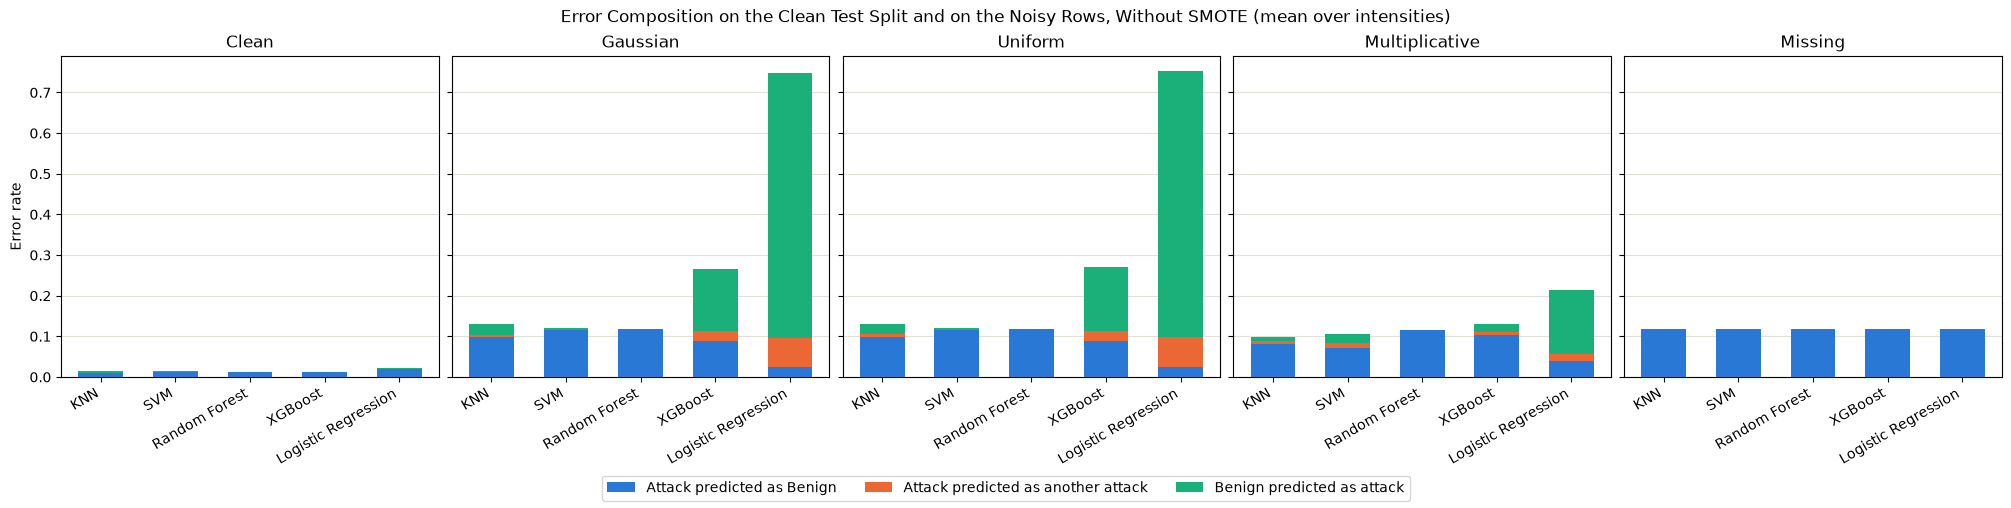

In [225]:
error_composition = measure_error_composition(metrics)
error_composition.to_csv(os.path.join(PATH_FOLDER_SETTING_EVALUATION, ERROR_COMPOSITION_FILE_NAME), index=False)
display(error_composition.round(4))
plot_error_composition(
    error_composition,
    save_path=os.path.join(PATH_FOLDER_SETTING_EVALUATION, ERROR_COMPOSITION_PLOT_FILE_NAME),
)

## Prediction Stability

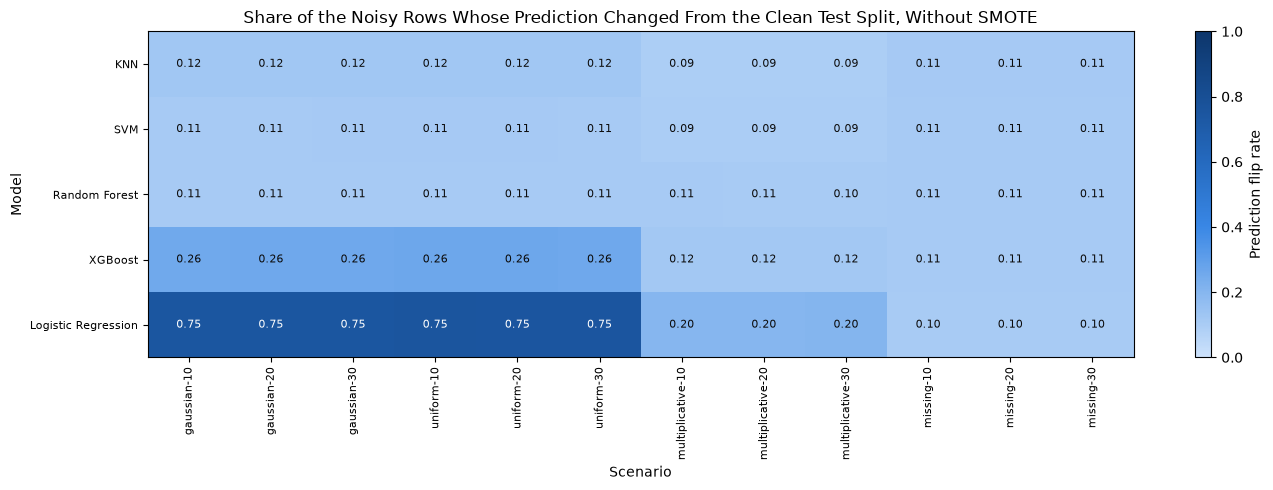

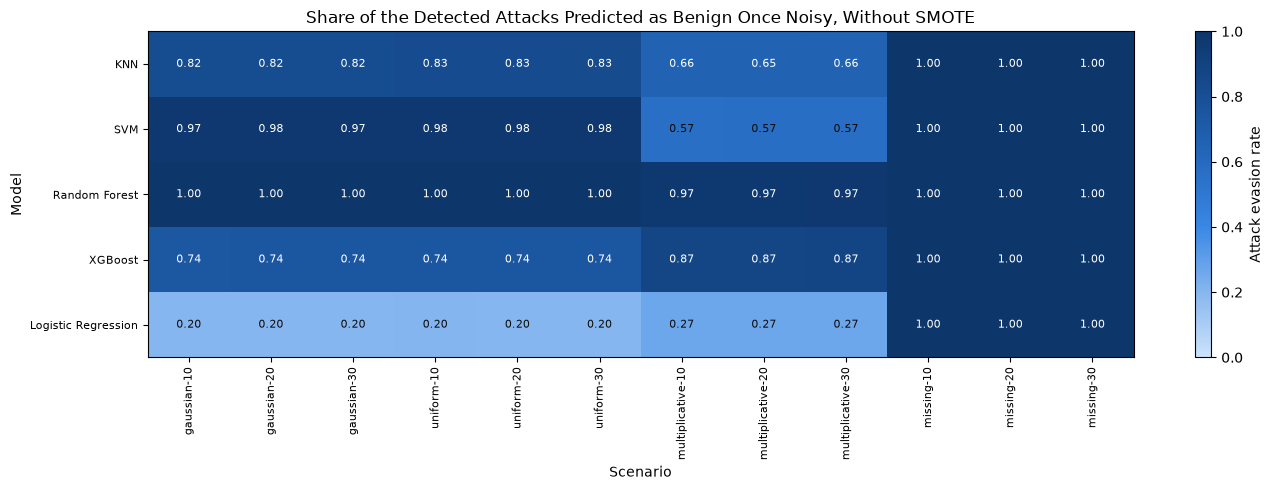

In [226]:
plot_scenario_heatmap(
    metrics,
    "flip_rate",
    "noisy",
    "Share of the Noisy Rows Whose Prediction Changed From the Clean Test Split",
    "Prediction flip rate",
    os.path.join(PATH_FOLDER_SETTING_EVALUATION, "flip_rate-noisy-heatmap.png"),
    value_range=(0, 1),
)
plot_scenario_heatmap(
    metrics,
    "evasion_rate",
    "noisy",
    "Share of the Detected Attacks Predicted as Benign Once Noisy",
    "Attack evasion rate",
    os.path.join(PATH_FOLDER_SETTING_EVALUATION, "evasion_rate-noisy-heatmap.png"),
    value_range=(0, 1),
)

In [227]:
def plot_flip_rate_against_displacement(
    displacement_bins: pd.DataFrame,
    intensity: float = max(NOISE_INTENSITIES),
    figsize: tuple[int, int] = (18, 5),
    save_path: str | None = None,
) -> None:
    noise_types = list(NOISE_MAGNITUDES)
    fig, axes = plt.subplots(
        1,
        len(noise_types),
        figsize=figsize,
        sharey=True,
        squeeze=False,
        layout="constrained",
    )
    legend_handles = {}
    for column_index, noise_type in enumerate(noise_types):
        ax = axes[0, column_index]
        scenario = get_noise_scenario_name(noise_type, intensity)
        for model_index, (model_name, model_label) in enumerate(EVALUATED_MODELS.items()):
            is_line = (
                (displacement_bins[MODEL_COLUMN] == model_name)
                & (displacement_bins[SCENARIO_COLUMN] == scenario)
            )
            rows = displacement_bins[is_line].sort_values("mean_displacement")
            if rows.empty:
                continue
            (line,) = ax.plot(
                rows["mean_displacement"],
                rows["flip_rate"],
                color=SERIES_COLORS[model_index],
                marker=SERIES_MARKERS[model_index],
                markersize=6,
                linewidth=2,
                zorder=3,
            )
            legend_handles.setdefault(model_label, line)
        ax.set_xscale("log")
        ax.set_title(scenario)
        ax.grid(color=GRID_COLOR, linewidth=0.8, zorder=0)

    for ax in axes[-1, :]:
        ax.set_xlabel("Displacement in principal components")
    for ax in axes[:, 0]:
        ax.set_ylabel("Prediction flip rate")
    handles = []
    labels = []
    for model_label in EVALUATED_MODELS.values():
        if model_label in legend_handles:
            handles.append(legend_handles[model_label])
            labels.append(model_label)
    if handles:
        fig.legend(handles, labels, loc="outside lower center", ncol=len(labels))
    fig.suptitle(
        f"Prediction Flip Rate per Displacement Decile of the Noisy Rows, {SMOTE_LABEL} "
        f"({round(intensity * 100)}% noisy rows)"
    )

    if save_path is not None:
        fig.savefig(save_path, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()

,smote_setting,model,scenario,noise_type,intensity,bin,rows,mean_displacement,flip_rate,error_rate
0,wout-smote,knn,gaussian-10,gaussian,0.1,0,22892,3.7565,0.1098,0.1175
1,wout-smote,knn,gaussian-10,gaussian,0.1,1,22892,4.2185,0.1139,0.1214
2,wout-smote,knn,gaussian-10,gaussian,0.1,2,22892,4.4641,0.1160,0.1245
3,wout-smote,knn,gaussian-10,gaussian,0.1,3,22892,4.6622,0.1176,0.1257
4,wout-smote,knn,gaussian-10,gaussian,0.1,4,22892,4.8431,0.1209,0.1273
...,...,...,...,...,...,...,...,...,...,...
595,wout-smote,logreg,missing-30,missing,0.3,5,68675,5.4313,0.1195,0.1328
596,wout-smote,logreg,missing-30,missing,0.3,6,68677,5.9239,0.0317,0.0398
597,wout-smote,logreg,missing-30,missing,0.3,7,68674,6.4910,0.0004,0.0074
598,wout-smote,logreg,missing-30,missing,0.3,8,68676,7.5373,0.0005,0.0127


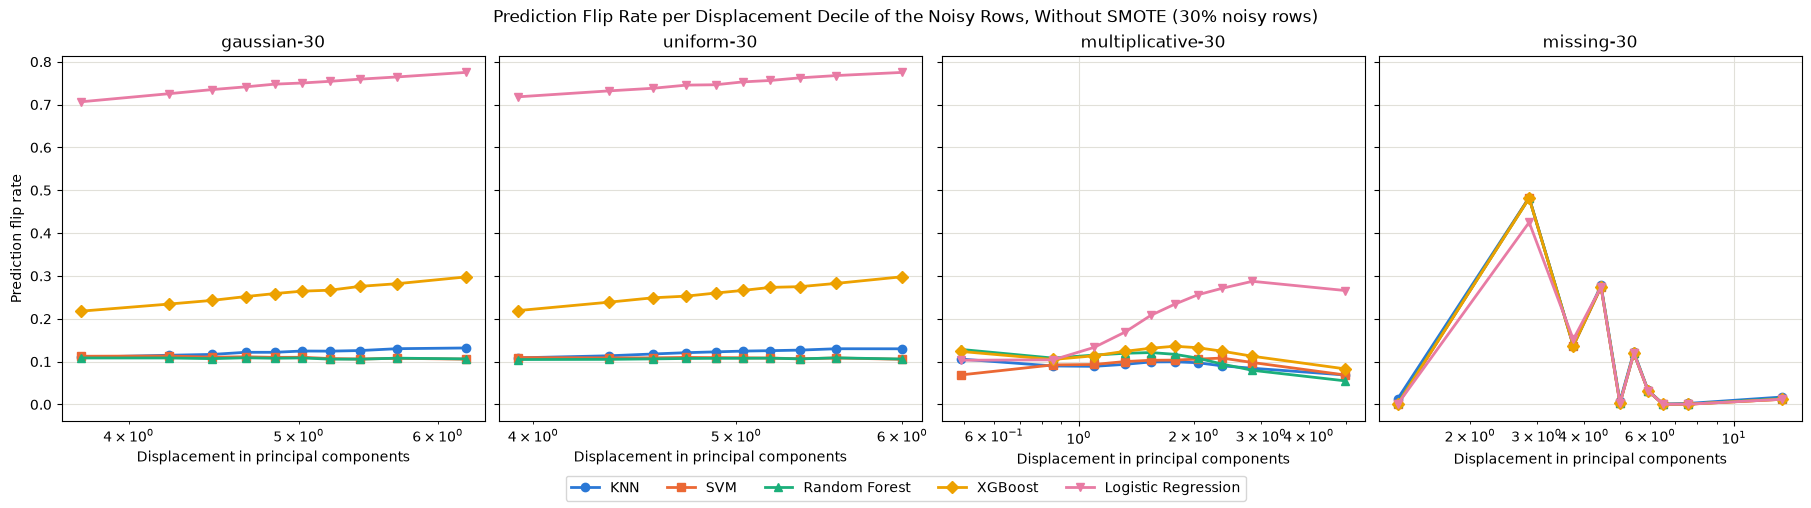

In [228]:
display(displacement_bins.round(4))
plot_flip_rate_against_displacement(
    displacement_bins,
    save_path=os.path.join(PATH_FOLDER_SETTING_EVALUATION, FLIP_RATE_PLOT_FILE_NAME),
)

## Confidence

confidence_gap                                   \
noise_type                    clean gaussian         missing           
population                      all      all   noisy     all   noisy   
smote_setting model                                                    
wout-smote    knn            0.0046   0.0252  0.1075  0.0273  0.1180   
              logreg        -0.0086   0.1357  0.7129  0.0135  0.1020   
              rf             0.0001  -0.0275 -0.1378  0.0223  0.1114   
              xgb            0.0000   0.0386  0.1922  0.0236  0.1178   

                                                            log_loss  ...  \
noise_type           multiplicative         uniform            clean  ...   
population                      all   noisy     all   noisy      all  ...   
smote_setting model                                                   ...   
wout-smote    knn            0.0196  0.0796  0.0254  0.1084   0.1595  ...   
              logreg         0.0233  0.1510  0.1365  0.7172   0.0971  ...   
              rf             0.0016  0.0079 -0.0279 -0.1396   0.0474  ...   
              xgb            0.0209  0.1047  0.0389  0.1943   0.0475  ...   

                     mean_confidence mean_error_confidence                   \
noise_type                   uniform                 clean gaussian           
population                     noisy                   all      all   noisy   
smote_setting model                                                           
wout-smote    knn             0.9784                0.8816   0.9216  0.9415   
              logreg          0.9645                0.8211   0.9476  0.9665   
              rf              0.7421                0.8566   0.7578  0.7096   
              xgb             0.9239                0.8646   0.8836  0.8879   

                                                                             
noise_type           missing         multiplicative         uniform          
population               all   noisy            all   noisy     all   noisy  
smote_setting model                                                          
wout-smote    knn     0.9585  1.0000         0.9199  0.9442  0.9218  0.9415  
              logreg  0.9087  0.9839         0.8509  0.8655  0.9479  0.9667  
              rf      0.9486  0.9933         0.8106  0.7880  0.7568  0.7083  
              xgb     0.9559  0.9998         0.9172  0.9403  0.8829  0.8869  

[4 rows x 36 columns]

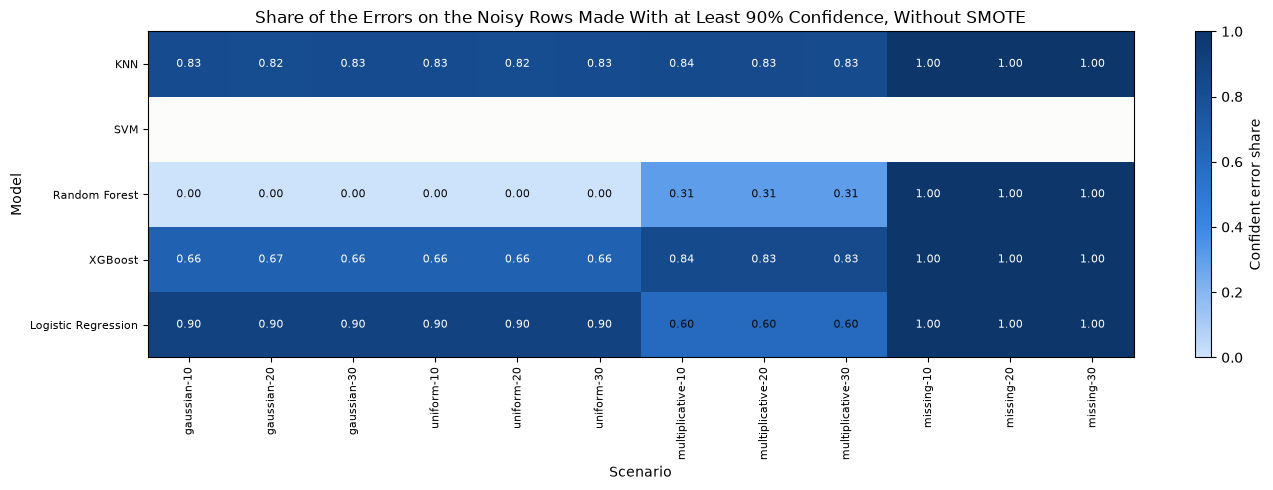

In [229]:
if metrics["mean_confidence"].notna().any():
    display(
        metrics[metrics[POPULATION_COLUMN] != "intact"].pivot_table(
            index=[SMOTE_SETTING_COLUMN, MODEL_COLUMN],
            columns=[NOISE_TYPE_COLUMN, POPULATION_COLUMN],
            values=["mean_confidence", "mean_error_confidence", "confidence_gap", "log_loss"],
        ).round(4)
    )
    plot_scenario_heatmap(
        metrics,
        "confident_error_share",
        "noisy",
        f"Share of the Errors on the Noisy Rows Made With at Least {CONFIDENT_ERROR_THRESHOLD:.0%} Confidence",
        "Confident error share",
        os.path.join(PATH_FOLDER_SETTING_EVALUATION, "confident_error_share-noisy-heatmap.png"),
        value_range=(0, 1),
    )
else:
    end_status("No model gave probabilities, so there is no confidence to compare")

## Confusion Matrices

In [230]:
def get_confusion_matrix(
    outcomes: pd.DataFrame,
    class_names: list[str],
    true_column: str = LABEL_COLUMN,
    predicted_column: str = PREDICTION_COLUMN,
) -> pd.DataFrame:
    matrix = confusion_matrix(
        outcomes[true_column],
        outcomes[predicted_column],
        labels=np.arange(len(class_names)),
        sample_weight=outcomes[ROW_COUNT_COLUMN],
    )
    confusion = pd.DataFrame(matrix, index=class_names, columns=class_names)
    return confusion.rename_axis(index=true_column, columns=predicted_column)

In [231]:
def plot_confusion_matrix(
    confusion: pd.DataFrame,
    title: str,
    save_path: str | None = None,
    show: bool = True,
    xlabel: str = "Predicted Class",
    ylabel: str = "True Class",
) -> None:
    plot_heatmap(
        confusion,
        title,
        log_scale=True,
        annotate=True,
        xlabel=xlabel,
        ylabel=ylabel,
        colorbar_label="Row Count (log scale)",
        figsize=(14, 11),
        save_path=save_path,
        show=show,
    )

In [232]:
def plot_every_matrix(
    outcomes: pd.DataFrame,
    class_names: list[str],
    show_noisy: bool = SHOW_NOISY_MATRICES,
    matrices_folder_path: str = PATH_FOLDER_SETTING_EVALUATION_MATRICES,
) -> None:
    groups = outcomes.groupby(COMBINATION_COLUMNS, sort=False)
    started = time.time()
    for group_index, (combination, combination_outcomes) in enumerate(groups, start=1):
        smote_setting, model_name, scenario, _, _ = combination
        title = f"{EVALUATED_MODELS[model_name]} ({SMOTE_SETTINGS[smote_setting]}), {scenario}"
        show = scenario == CLEAN_SCENARIO or show_noisy
        folder_path = os.path.join(matrices_folder_path, model_name)
        os.makedirs(folder_path, exist_ok=True)
        for population in ["all", "noisy"]:
            population_outcomes = select_population(combination_outcomes, population)
            if population_outcomes.empty:
                continue
            plot_confusion_matrix(
                get_confusion_matrix(population_outcomes, class_names),
                f"Confusion Matrix of {title}, {POPULATIONS[population]}",
                os.path.join(folder_path, f"{scenario}-{population}-{CONFUSION_MATRIX_PLOT_FILE_NAME}"),
                show=show,
            )

        noisy_outcomes = select_population(combination_outcomes, "noisy")
        if not noisy_outcomes.empty:
            plot_confusion_matrix(
                get_confusion_matrix(noisy_outcomes, class_names, CLEAN_PREDICTION_COLUMN, PREDICTION_COLUMN),
                f"Predictions of {title} on the Noisy Rows Against the Same Rows Without Noise",
                os.path.join(folder_path, f"{scenario}-{PREDICTION_TRANSITIONS_PLOT_FILE_NAME}"),
                show=show,
                xlabel="Prediction With Noise",
                ylabel="Prediction Without Noise",
            )
        print_progress(group_index, groups.ngroups, "Plotting confusion matrices", started=started)
    end_status(f"Saved the confusion matrices of {groups.ngroups} predictions to {matrices_folder_path}")

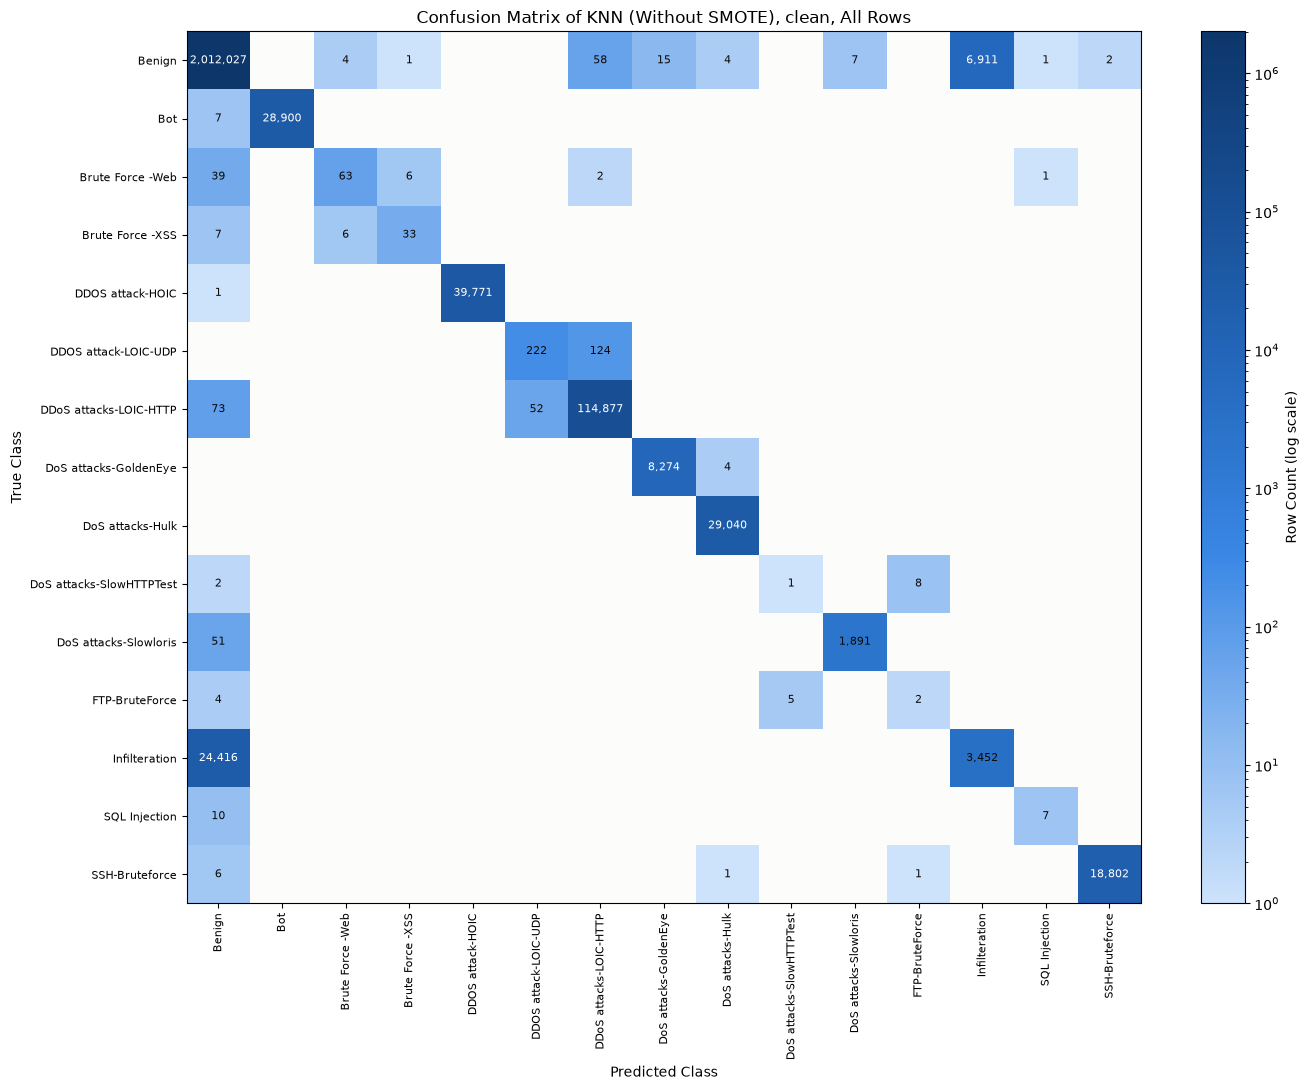

Plotting confusion matrices |██████------------------------| 13/65 (20%) | 00:00:46 elapsed, ~00:03:05 left

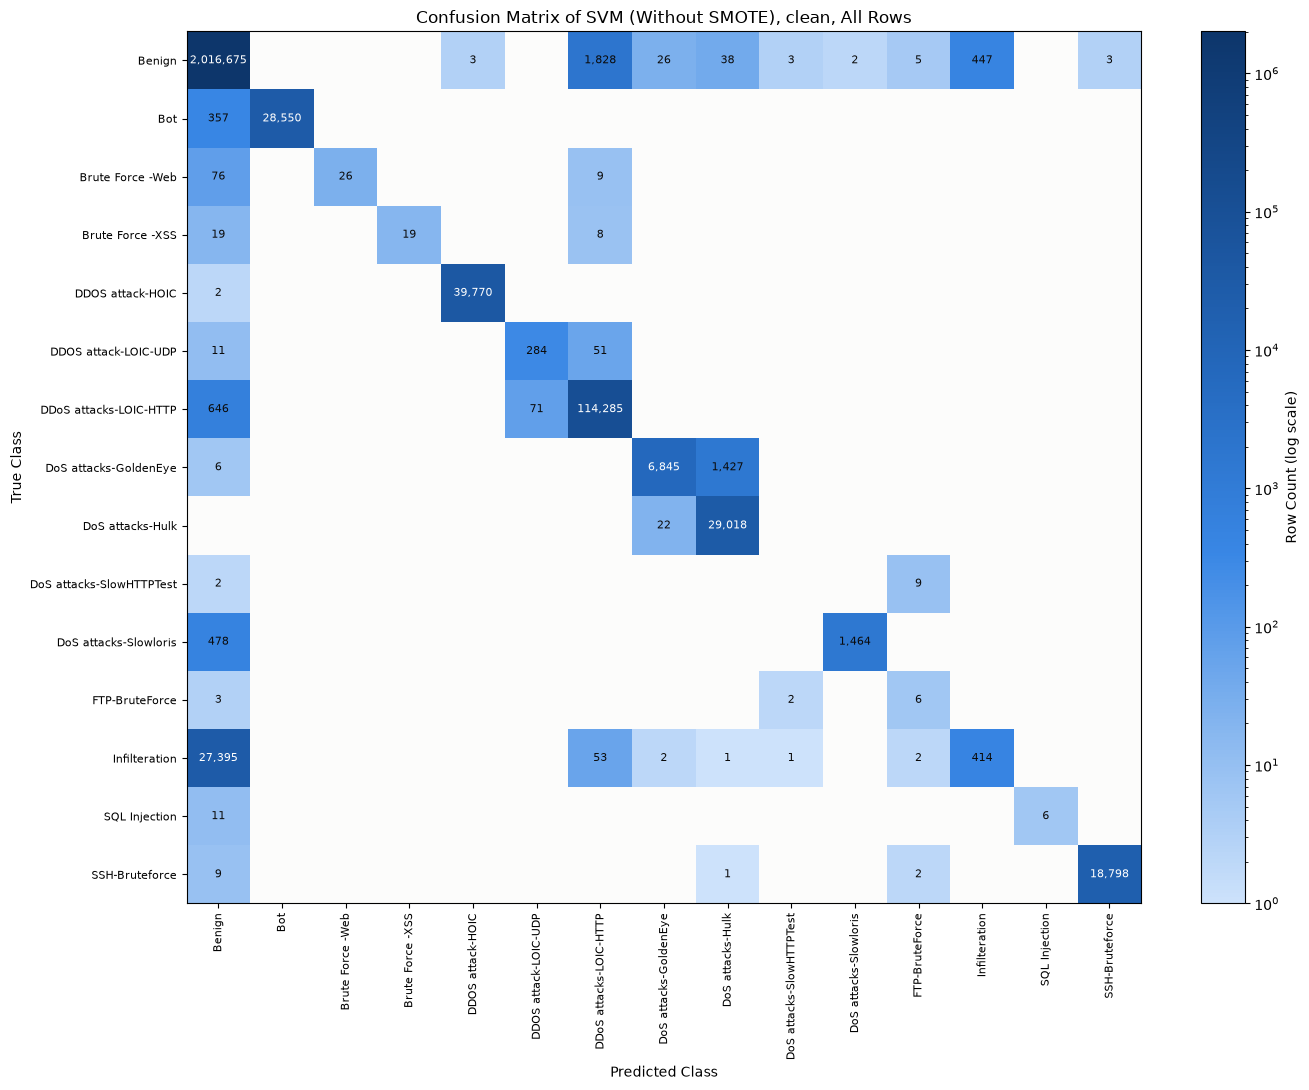

Plotting confusion matrices |████████████------------------| 26/65 (40%) | 00:01:20 elapsed, ~00:02:00 left

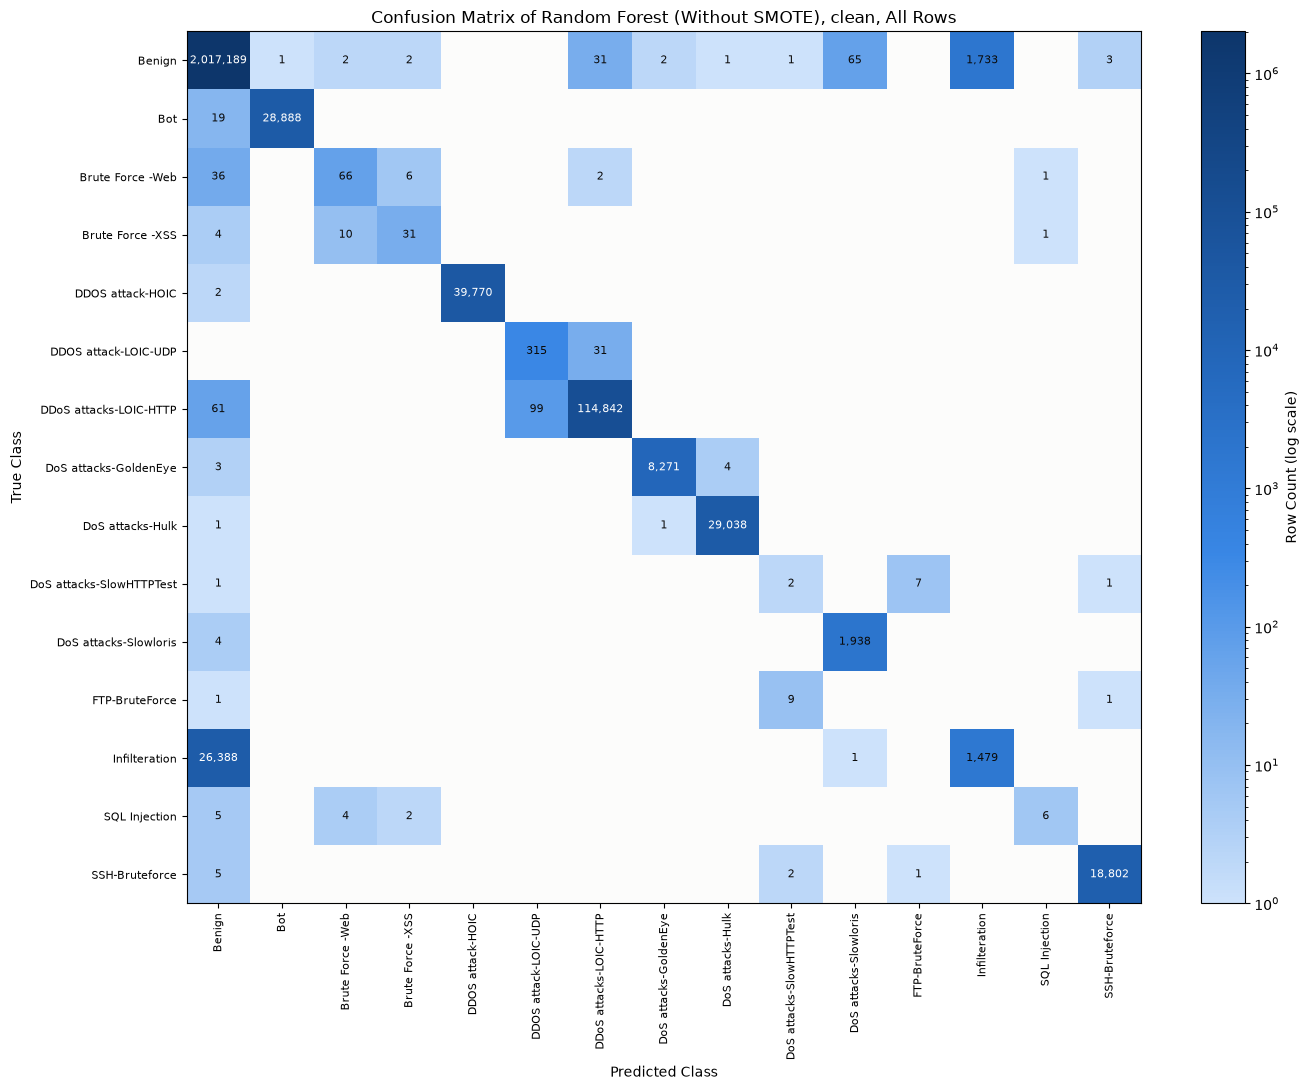

Plotting confusion matrices |██████████████████------------| 39/65 (60%) | 00:01:55 elapsed, ~00:01:17 left

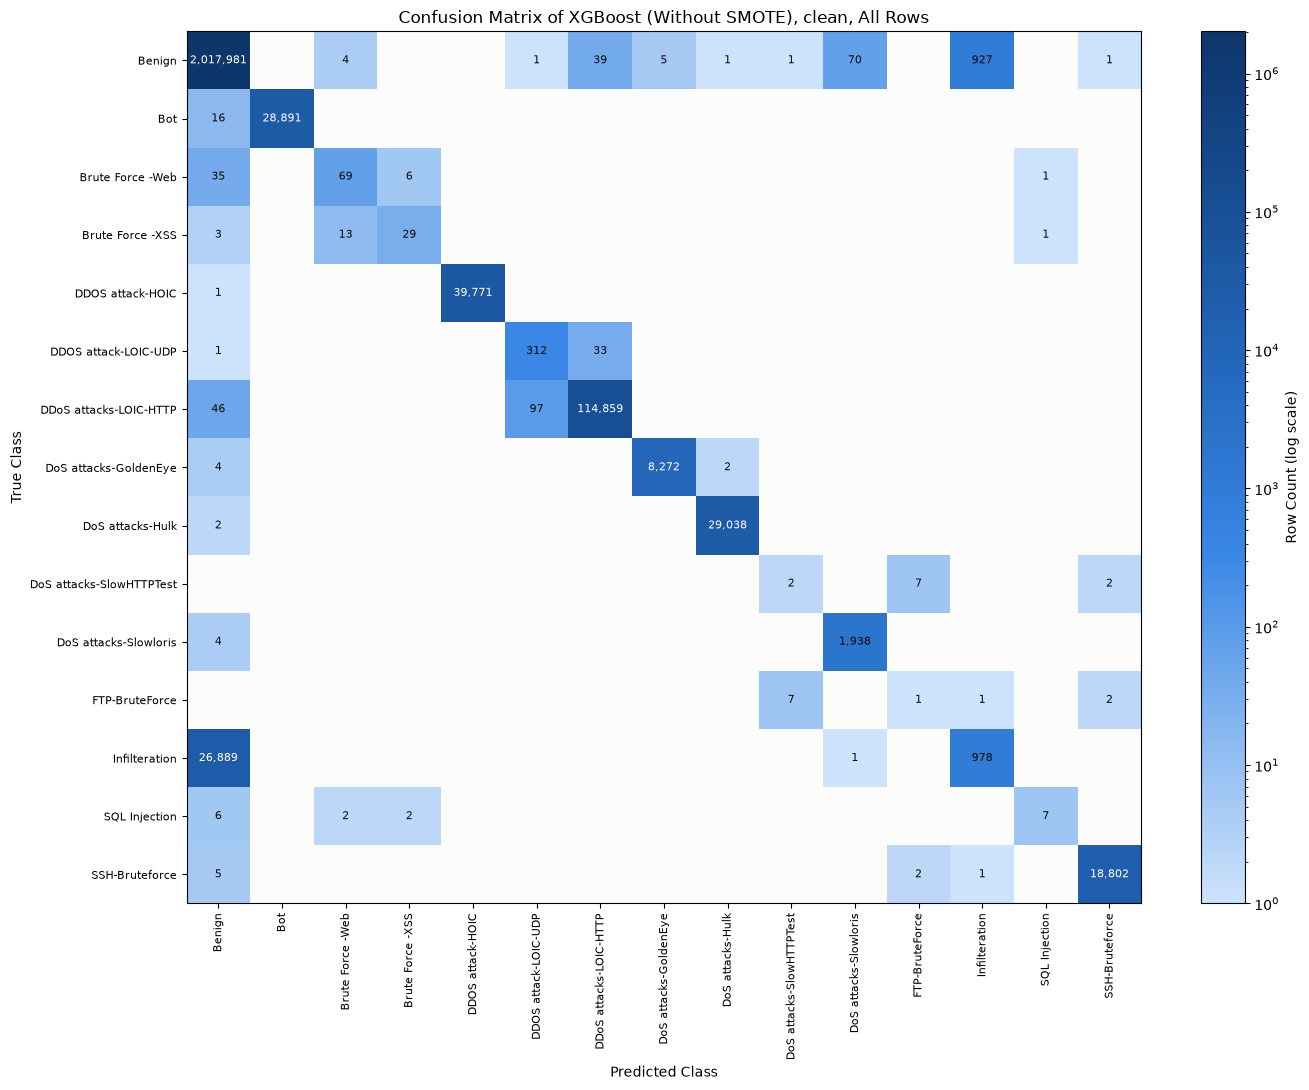

Plotting confusion matrices |████████████████████████------| 52/65 (80%) | 00:02:32 elapsed, ~00:00:38 left

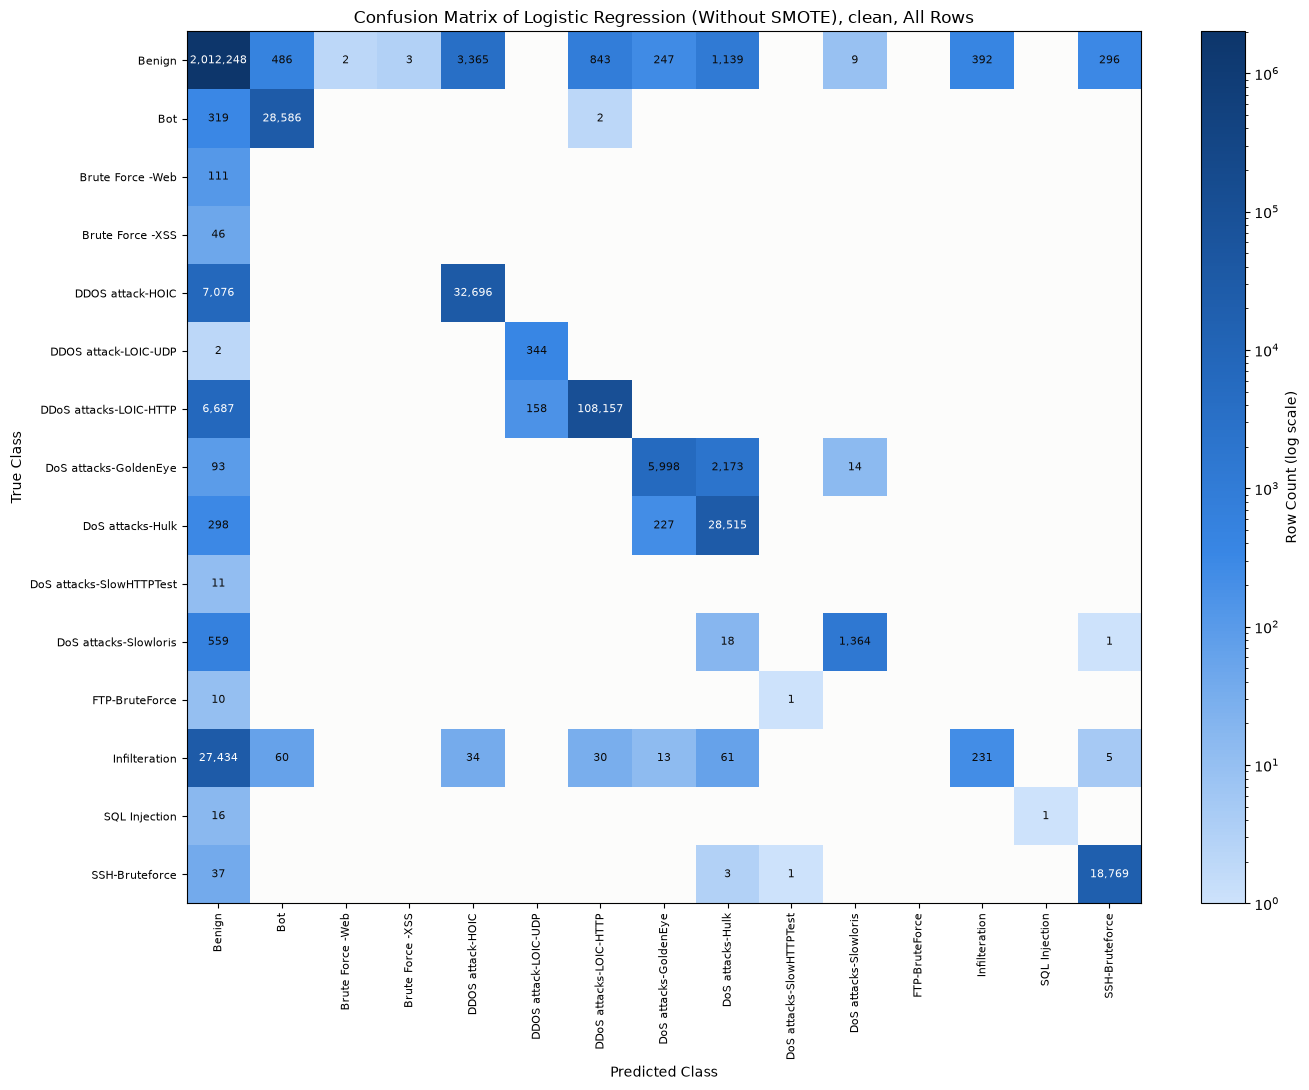

Saved the confusion matrices of 65 predictions to evaluation/wout-smote/matrices3:06 elapsed ~00:00:02 left


In [233]:
if SAVE_MATRIX_PLOTS:
    plot_every_matrix(outcomes, class_names)

## Prediction Cost

In [234]:
def load_prediction_summaries() -> pd.DataFrame:
    summaries = []
    for smote_setting, model_name, scenario in list_predicted_combinations():
        summaries.append(read_prediction_summary(smote_setting, model_name, scenario))
    summaries = pd.DataFrame(summaries)
    summaries["rows_per_second"] = summaries[ROW_COUNT_COLUMN] / summaries["predict_seconds"]
    return summaries

In [235]:
prediction_summaries = load_prediction_summaries()
prediction_summaries.to_csv(os.path.join(PATH_FOLDER_SETTING_EVALUATION, PREDICTION_SUMMARIES_FILE_NAME), index=False)
display(prediction_summaries[prediction_summaries[SCENARIO_COLUMN] == CLEAN_SCENARIO].round(4))
display(
    prediction_summaries.pivot_table(
        index=[SMOTE_SETTING_COLUMN, MODEL_COLUMN],
        columns=SCENARIO_COLUMN,
        values="predict_seconds",
    ).reindex(columns=list_scenario_names()).round(2)
)

,smote_setting,model,scenario,rows,noisy_rows,transform_seconds,predict_seconds,has_confidence,dataset_fingerprint,prediction_batch_size,classifier,pca_components,pca_variance_percentage,smote_k_neighbors,rows_per_second
0,wout-smote,knn,clean,2289191,0,1.9620,1099.5631,True,a19038bb285dc9d4c44664fce35bc46414f8bfb0d21d45...,250000,KNeighborsClassifier,25,95.5944,None,2.081910e+03
13,wout-smote,svm,clean,2289191,0,0.7317,69.3779,False,a19038bb285dc9d4c44664fce35bc46414f8bfb0d21d45...,250000,RetrySVC,25,95.5944,None,3.299596e+04
26,wout-smote,rf,clean,2289191,0,0.8706,55.1450,True,a19038bb285dc9d4c44664fce35bc46414f8bfb0d21d45...,250000,RandomForestClassifier,25,95.5944,None,4.151219e+04
39,wout-smote,xgb,clean,2289191,0,0.6429,2.1068,True,a19038bb285dc9d4c44664fce35bc46414f8bfb0d21d45...,250000,XGBClassifier,25,95.5944,None,1.086554e+06
52,wout-smote,logreg,clean,2289191,0,0.6765,0.8616,True,a19038bb285dc9d4c44664fce35bc46414f8bfb0d21d45...,250000,LogisticRegression,25,95.5944,None,2.656970e+06


scenario                clean  gaussian-10  gaussian-20  gaussian-30  \
smote_setting model                                                    
wout-smote    knn     1099.56      1099.58      1096.56      1097.90   
              logreg     0.86         0.55         0.57         0.58   
              rf        55.15        38.17        44.88        46.78   
              svm       69.38        66.18        61.97        64.21   
              xgb        2.11         1.94         1.99         1.96   

scenario              uniform-10  uniform-20  uniform-30  multiplicative-10  \
smote_setting model                                                           
wout-smote    knn        1100.78     1100.00     1100.91            1098.32   
              logreg        0.54        0.56        0.58               0.56   
              rf           43.09       44.29       45.10              42.47   
              svm          65.24       65.42       65.30              61.63   
              xgb           1.98        1.99        1.96               1.96   

scenario              multiplicative-20  multiplicative-30  missing-10  \
smote_setting model                                                      
wout-smote    knn               1099.92            1099.87     1098.62   
              logreg               0.58               0.54        0.59   
              rf                  43.75              42.04       46.10   
              svm                 65.17              63.57       64.00   
              xgb                  1.96               1.97        1.91   

scenario              missing-20  missing-30  
smote_setting model                           
wout-smote    knn        1099.75     1099.91  
              logreg        0.57        0.56  
              rf           41.35       41.08  
              svm          64.25       64.45  
              xgb           1.92        1.92

## Key Findings

In [236]:
def find_key_findings(
    metrics: pd.DataFrame,
    degradation: pd.DataFrame,
    class_metrics: pd.DataFrame,
    mixture_check: pd.DataFrame,
    metric: str = ROBUSTNESS_METRIC,
) -> pd.DataFrame:
    findings = []
    is_noise_scenario = metrics[SCENARIO_COLUMN] != CLEAN_SCENARIO
    is_attack_class = class_metrics[CLASS_COLUMN] != BENIGN_CLASS
    clean = metrics[~is_noise_scenario & (metrics[POPULATION_COLUMN] == "all")]
    clean = clean.set_index(MODEL_COLUMN)[metric]
    best_clean_model = EVALUATED_MODELS[clean.idxmax()]
    findings.append((f"Highest clean {METRIC_LABELS[metric]}", best_clean_model, clean.max()))

    for population in ["all", "noisy"]:
        is_shown = (
            (degradation[METRIC_COLUMN] == metric)
            & (degradation[POPULATION_COLUMN] == population)
            & (degradation[SCENARIO_COLUMN] != CLEAN_SCENARIO)
        )
        retention = degradation[is_shown]
        if retention.empty:
            continue
        by_model = retention.groupby(MODEL_COLUMN)[RETENTION_COLUMN].mean()
        by_scenario = retention.groupby(SCENARIO_COLUMN)[RETENTION_COLUMN].mean()
        by_noise_type = retention.groupby(NOISE_TYPE_COLUMN)[RETENTION_COLUMN].mean()
        rows_label = POPULATIONS[population].lower()
        findings.append((
            f"Most robust model, {rows_label} (mean retention)",
            EVALUATED_MODELS[by_model.idxmax()],
            by_model.max(),
        ))
        findings.append((
            f"Least robust model, {rows_label} (mean retention)",
            EVALUATED_MODELS[by_model.idxmin()],
            by_model.min(),
        ))
        findings.append((
            f"Hardest scenario, {rows_label} (mean retention)",
            by_scenario.idxmin(),
            by_scenario.min(),
        ))
        findings.append((
            f"Most damaging noise type, {rows_label} (mean retention)",
            by_noise_type.idxmin(),
            by_noise_type.min(),
        ))

    noisy_rows = metrics[metrics[POPULATION_COLUMN] == "noisy"]
    highest_questions = {
        "flip_rate": "Most unstable model on the noisy rows (mean flip rate)",
        "evasion_rate": "Model whose detected attacks turn Benign most often (mean evasion rate)",
        "false_alarm_rate": "Model with the most false alarms on the noisy rows (mean false alarm rate)",
        "confident_error_share": "Model with the most confident errors on the noisy rows",
    }
    for column, question in highest_questions.items():
        by_model = noisy_rows.groupby(MODEL_COLUMN)[column].mean().dropna()
        if not by_model.empty:
            findings.append((question, EVALUATED_MODELS[by_model.idxmax()], by_model.max()))

    noisy_classes = class_metrics[(class_metrics[POPULATION_COLUMN] == "noisy") & is_attack_class]
    if not noisy_classes.empty:
        benign_rate = noisy_classes.groupby(CLASS_COLUMN)["benign_rate"].mean().dropna()
        f1_drop = noisy_classes.groupby(CLASS_COLUMN)["f1_drop"].mean().dropna()
        findings.append((
            "Attack most often predicted as Benign on the noisy rows",
            benign_rate.idxmax(),
            benign_rate.max(),
        ))
        findings.append((
            "Attack with the largest F1-score drop on the noisy rows",
            f1_drop.idxmax(),
            f1_drop.max(),
        ))

    is_intact = (metrics[POPULATION_COLUMN] == "intact") & is_noise_scenario
    findings.append((
        "Largest flip rate on the intact rows (0 means the clean baseline is valid)",
        "",
        metrics.loc[is_intact, "flip_rate"].max(),
    ))
    findings.append((
        "Largest accuracy mixture residual (0 means the populations add up)",
        "",
        mixture_check["residual"].abs().max(),
    ))
    return pd.DataFrame(findings, columns=["finding", "answer", "value"])

In [237]:
key_findings = find_key_findings(metrics, degradation, class_metrics, mixture_check)
key_findings.to_csv(os.path.join(PATH_FOLDER_SETTING_EVALUATION, KEY_FINDINGS_FILE_NAME), index=False)
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(key_findings.round(4))

,finding,answer,value
0,Highest clean F1-score (macro),KNN,0.7441
1,"Most robust model, all rows (mean retention)",Random Forest,0.8980
2,"Least robust model, all rows (mean retention)",Logistic Regression,0.6976
3,"Hardest scenario, all rows (mean retention)",gaussian-30,0.6723
4,"Most damaging noise type, all rows (mean retention)",gaussian,0.7521
5,"Most robust model, noisy rows (mean retention)",KNN,0.2346
6,"Least robust model, noisy rows (mean retention)",XGBoost,0.1275
7,"Hardest scenario, noisy rows (mean retention)",missing-30,0.0909
8,"Most damaging noise type, noisy rows (mean retention)",missing,0.0942
9,Most unstable model on the noisy rows (mean flip rate),Logistic Regression,0.4502
